# **Analisis sentimen multi-class pada ulasan aspek Attractions and Activities destinasi wisata Pulau Jawa menggunakan IndoBERTweet.**


---




## Import Libraries

In [ ]:
!pip install yake
from yake import KeywordExtractor


!pip install -q transformers datasets accelerate evaluate emoji Sastrawi

# ============================================================
# INSTALL LIBRARY
# ============================================================

!pip install PySastrawi emoji scikit-learn --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.4/91.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.5/360.5 kB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 7.9 MB/s eta 0:00:00


In [ ]:
# =========================================
# CELL 1 — IMPORT & GLOBAL CONFIG
# =========================================

# ===== Core Library =====
import pandas as pd
import numpy as np
import re
import random
import warnings
warnings.filterwarnings("ignore")

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns

# ===== NLP =====
import emoji
import unicodedata
from collections import Counter

# ===== Sastrawi =====
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# ===== Scikit-Learn =====
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# ===== PyTorch =====
import torch
import torch.nn as nn

# ===== HuggingFace =====
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

# ===== Dataset =====
from datasets import Dataset

import matplotlib

# =========================================
# SASTRAWI INITIALIZATION
# =========================================

stop_factory = StopWordRemoverFactory()
stemmer_factory = StemmerFactory()

stopword_remover = stop_factory.create_stop_word_remover()
stemmer = stemmer_factory.create_stemmer()

print("✅ Semua library berhasil diimport")
print(f"   Versi emoji  : {emoji.__version__}")
print(f"   Jumlah stopword Sastrawi: {len(stop_factory.get_stop_words())}")

# =========================================
# DISPLAY CONFIG
# =========================================

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)

# =========================================
# RANDOM SEED
# =========================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# =========================================
# DEVICE CONFIG
# =========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# MODEL_NAME = "indolem/indobertweet-base-uncased"

# # =========================================
# # LABEL MAPPING
# # =========================================

# label2id = {
#     "negative": 0,
#     "neutral": 1,
#     "positive": 2
# }

# id2label = {
#     0: "negative",
#     1: "neutral",
#     2: "positive"
# }

✅ Semua library berhasil diimport
   Versi emoji  : 2.15.0
   Jumlah stopword Sastrawi: 809
Using device: cuda


## Getting Data

In [ ]:
import requests
import csv
import time
from google.colab import userdata

# API_KEY = "YOUR_GOOGLE_API_KEY"
API_KEY = userdata.get('GOOGLE_MAPS_API')
LANGUAGE = "id"

# Bali bounding box
MIN_LAT = -8.90
MAX_LAT = -8.00
MIN_LNG = 114.43
MAX_LNG = 115.72

# 10 km ≈ 0.09 degrees
LAT_STEP = 0.09
LNG_STEP = 0.09
RADIUS_METERS = 10000

def nearby_search(lat, lng, token=None):
    url = "https://maps.googleapis.com/maps/api/place/nearbysearch/json"
    params = {
        "location": f"{lat},{lng}",
        "radius": RADIUS_METERS,
        "type": "tourist_attraction",
        "language": LANGUAGE,
        "key": API_KEY
    }
    if token:
        params["pagetoken"] = token
    resp = requests.get(url, params=params).json()
    return resp

def get_reviews(place_id):
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,reviews",
        "language": LANGUAGE,
        "reviews_sort": "newest",
        "key": API_KEY
    }
    resp = requests.get(url, params=params).json()
    result = resp.get("result", {})
    return result.get("name"), result.get("reviews", [])

def generate_grid(min_lat, max_lat, min_lng, max_lng, lat_step, lng_step):
    points = []
    lat = min_lat
    while lat <= max_lat:
        lng = min_lng
        while lng <= max_lng:
            points.append((lat, lng))
            lng += lng_step
        lat += lat_step
    return points

def main():
    print("[+] Generating 10 km grid for Bali")
    grid_points = generate_grid(MIN_LAT, MAX_LAT, MIN_LNG, MAX_LNG, LAT_STEP, LNG_STEP)
    print(f"Total grid points: {len(grid_points)}")

    seen_places = set()

    # Stage 1: Discover unique places
    for i, (lat, lng) in enumerate(grid_points, start=1):
        print(f"\n[#] Point {i}/{len(grid_points)} at ({lat},{lng})")

        response = nearby_search(lat, lng)
        for place in response.get("results", []):
            pid = place.get("place_id")
            if pid:
                seen_places.add(pid)

        # pagination
        token = response.get("next_page_token")
        if token:
            time.sleep(2)  # Google requires short delay
            response2 = nearby_search(lat, lng, token)
            for place in response2.get("results", []):
                pid = place.get("place_id")
                if pid:
                    seen_places.add(pid)

        print(f"    -> Unique places so far: {len(seen_places)}")

    print("\n[✓] DONE scanning Grid.")
    print(f"Total unique place IDs found: {len(seen_places)}")

    # Stage 2: Fetch Indonesian reviews
    reviews_out = []
    for idx, pid in enumerate(seen_places, start=1):
        place_name, reviews = get_reviews(pid)
        for r in reviews:
            if r.get("language") == "id":
                reviews_out.append({
                    "place_id": pid,
                    "place_name": place_name,
                    "author": r.get("author_name"),
                    "rating": r.get("rating"),
                    "time": r.get("relative_time_description"),
                    "text": r.get("text")
                })

        if idx % 50 == 0:
            print(f"[Reviews] Fetched for {idx} places...")

    print(f"\n[✓] Finished fetching reviews.")
    print(f"Total Indonesian reviews collected: {len(reviews_out)}")

    # Save to CSV
    fname = "bali_reviews_10km.csv"
    header = ["place_id", "place_name", "author", "rating", "time", "text"]
    with open(fname, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=header)
        writer.writeheader()
        for row in reviews_out:
            writer.writerow(row)

    print(f"[Output] Saved to {fname}")

if __name__ == "__main__":
    main()


[+] Generating 10 km grid for Bali
Total grid points: 165

[#] Point 1/165 at (-8.9,114.43)
    -> Unique places so far: 0

[#] Point 2/165 at (-8.9,114.52000000000001)
    -> Unique places so far: 0

[#] Point 3/165 at (-8.9,114.61000000000001)
    -> Unique places so far: 0

[#] Point 4/165 at (-8.9,114.70000000000002)
    -> Unique places so far: 0

[#] Point 5/165 at (-8.9,114.79000000000002)
    -> Unique places so far: 0

[#] Point 6/165 at (-8.9,114.88000000000002)
    -> Unique places so far: 0

[#] Point 7/165 at (-8.9,114.97000000000003)
    -> Unique places so far: 0

[#] Point 8/165 at (-8.9,115.06000000000003)
    -> Unique places so far: 37

[#] Point 9/165 at (-8.9,115.15000000000003)
    -> Unique places so far: 72

[#] Point 10/165 at (-8.9,115.24000000000004)
    -> Unique places so far: 99

[#] Point 11/165 at (-8.9,115.33000000000004)
    -> Unique places so far: 99

[#] Point 12/165 at (-8.9,115.42000000000004)
    -> Unique places so far: 99

[#] Point 13/165 at (

In [ ]:
import requests
import csv
import time
from google.colab import userdata

# API Key Google Maps
API_KEY = userdata.get('GOOGLE_MAPS_API')
LANGUAGE = "id"

# Bounding box Pulau Bali
MIN_LAT = -8.90
MAX_LAT = -8.00
MIN_LNG = 114.43
MAX_LNG = 115.72

# Grid parameter (~10 km antar titik)
LAT_STEP = 0.09
LNG_STEP = 0.09
RADIUS_METERS = 10000

def nearby_search(lat, lng, token=None):
    url = "https://maps.googleapis.com/maps/api/place/nearbysearch/json"
    params = {
        "location": f"{lat},{lng}",
        "radius": RADIUS_METERS,
        "type": "tourist_attraction",
        "language": LANGUAGE,
        "key": API_KEY
    }
    if token:
        params["pagetoken"] = token
    resp = requests.get(url, params=params).json()
    return resp

def get_details_and_reviews(place_id):
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,reviews,geometry,formatted_address",
        "language": LANGUAGE,
        "reviews_sort": "newest",
        "key": API_KEY
    }
    resp = requests.get(url, params=params).json()
    result = resp.get("result", {})
    return (
        result.get("name"),
        result.get("reviews", []),
        result.get("geometry", {}),
        result.get("formatted_address", "")
    )

def generate_grid(min_lat, max_lat, min_lng, max_lng, lat_step, lng_step):
    points = []
    lat = min_lat
    while lat <= max_lat:
        lng = min_lng
        while lng <= max_lng:
            points.append((lat, lng))
            lng += lng_step
        lat += lat_step
    return points

def in_bali(lat, lng):
    return (MIN_LAT <= lat <= MAX_LAT) and (MIN_LNG <= lng <= MAX_LNG)

def main():
    print("[+] Generating 10 km grid for Bali")
    grid_points = generate_grid(MIN_LAT, MAX_LAT, MIN_LNG, MAX_LNG, LAT_STEP, LNG_STEP)
    print(f"Total grid points: {len(grid_points)}")

    seen_places = set()

    # Stage 1: Discover unique places
    for idx, (lat, lng) in enumerate(grid_points, start=1):
        print(f"\n[#] Point {idx}/{len(grid_points)} at ({lat},{lng})")
        response = nearby_search(lat, lng)
        for place in response.get("results", []):
            pid = place.get("place_id")
            geom = place.get("geometry", {}).get("location", {})
            plat, plng = geom.get("lat"), geom.get("lng")
            if pid and plat and plng and in_bali(plat, plng):
                seen_places.add(pid)

        token = response.get("next_page_token")
        if token:
            time.sleep(2)
            response2 = nearby_search(lat, lng, token)
            for place in response2.get("results", []):
                pid = place.get("place_id")
                geom = place.get("geometry", {}).get("location", {})
                plat, plng = geom.get("lat"), geom.get("lng")
                if pid and plat and plng and in_bali(plat, plng):
                    seen_places.add(pid)

        print(f"    -> Unique Bali places so far: {len(seen_places)}")

    print("\n[✓] DONE Grid scanning.")
    print(f"Total unique place IDs (Bali only): {len(seen_places)}")

    # Stage 2: Fetch reviews, lat/lng, address
    reviews_out = []
    for count, pid in enumerate(seen_places, start=1):
        name, reviews, geom, addr = get_details_and_reviews(pid)

        loc = geom.get("location", {})
        lat_p = loc.get("lat")
        lng_p = loc.get("lng")

        # Filter by bounding box (safe), and address contains 'Bali'
        if not lat_p or not lng_p:
            continue
        if not in_bali(lat_p, lng_p):
            continue
        if "Bali" not in addr:
            # Optional: skip non-bali addresses
            continue

        # Collect only Indonesian reviews
        for r in reviews:
            if r.get("language") == "id":
                reviews_out.append({
                    "place_id": pid,
                    "place_name": name,
                    "address": addr,
                    "lat": lat_p,
                    "lng": lng_p,
                    "author": r.get("author_name"),
                    "rating": r.get("rating"),
                    "time": r.get("relative_time_description"),
                    "text": r.get("text")
                })

        if count % 50 == 0:
            print(f"[Reviews] Processed {count} places... Total reviews: {len(reviews_out)}")

    print(f"\n[✓] Finished collecting reviews.")
    print(f"Total Indonesian reviews collected: {len(reviews_out)}")

    # Save to CSV
    fname = "bali_tourist_attractions_reviews.csv"
    header = ["place_id", "place_name", "address", "lat", "lng", "author", "rating", "time", "text"]
    with open(fname, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=header)
        writer.writeheader()
        for row in reviews_out:
            writer.writerow(row)

    print(f"[Output] Saved to {fname}")

if __name__ == "__main__":
    main()


[+] Generating 10 km grid for Bali
Total grid points: 165

[#] Point 1/165 at (-8.9,114.43)
    -> Unique Bali places so far: 0

[#] Point 2/165 at (-8.9,114.52000000000001)
    -> Unique Bali places so far: 0

[#] Point 3/165 at (-8.9,114.61000000000001)
    -> Unique Bali places so far: 0

[#] Point 4/165 at (-8.9,114.70000000000002)
    -> Unique Bali places so far: 0

[#] Point 5/165 at (-8.9,114.79000000000002)
    -> Unique Bali places so far: 0

[#] Point 6/165 at (-8.9,114.88000000000002)
    -> Unique Bali places so far: 0

[#] Point 7/165 at (-8.9,114.97000000000003)
    -> Unique Bali places so far: 0

[#] Point 8/165 at (-8.9,115.06000000000003)
    -> Unique Bali places so far: 37

[#] Point 9/165 at (-8.9,115.15000000000003)
    -> Unique Bali places so far: 72

[#] Point 10/165 at (-8.9,115.24000000000004)
    -> Unique Bali places so far: 99

[#] Point 11/165 at (-8.9,115.33000000000004)
    -> Unique Bali places so far: 99

[#] Point 12/165 at (-8.9,115.42000000000004)

In [ ]:
import requests
import csv
import time
from google.colab import userdata

# API Key Google Maps
API_KEY = userdata.get('GOOGLE_MAPS_API')

# Example place ID (replace with any valid place ID)
PLACE_ID = "ChIJEyT4_2kB0i0RhjuQyukzEi8"

def get_place_reviews(place_id):
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,reviews,geometry,formatted_address",
        "reviews_sort": "newest",
        "reviews_no_translations": "true",  # <--- prevent translation
        "key": API_KEY
    }

    resp = requests.get(url, params=params).json()
    result = resp.get("result", {})

    place_name = result.get("name")
    address = result.get("formatted_address")
    reviews = result.get("reviews", [])

    print(f"Place: {place_name}")
    print(f"Address: {address}")
    print(f"Total reviews fetched: {len(reviews)}\n")

    for r in reviews:

      print(f"Author: {r.get('author_name')}")
      print(f"Rating: {r.get('rating')}")
      print(f"Time: {r.get('relative_time_description')}")
      print(f"Time: {r.get('time')}")
      print(f"Review Text: {r.get('text')}")
      print(f"ORILanguage: {r.get('original_language')}")
      print(f"Languange: {r.get('language')}")
      print(f"Translate: {r.get('translated')}")
      print("-" * 50)

if __name__ == "__main__":
    get_place_reviews(PLACE_ID)


Place: Amed Snorkeling & Sunset tour
Address: Jl ketut natih, Purwakerti, Kec. Abang, Kabupaten Karangasem, Bali 80852, Indonesia
Total reviews fetched: 5

Author: Sacha M
Rating: 5
Time: in the last week
Time: 1755766270
Review Text: 
ORILanguage: None
Languange: None
Translate: False
--------------------------------------------------
Author: Juli Purnami
Rating: 5
Time: 4 weeks ago
Time: 1753778494
Review Text: Hari ini saya liburan ke amed,dan mencoba snorkel di amed view sangat bagus ikannya banyak dan saya melihat penyu 2 sangat besar dan karang sangat bagus. Trimakasih banyak jack. Hari ini saya berliburan di amed sangat hoki 🥰
ORILanguage: id
Languange: id
Translate: False
--------------------------------------------------
Author: Pretty Woman
Rating: 5
Time: 4 weeks ago
Time: 1753778206
Review Text: Thebest coral❤️
ORILanguage: en
Languange: en
Translate: False
--------------------------------------------------
Author: Pageh adi Pradnyana
Rating: 5
Time: a month ago
Time: 17529

In [ ]:
import requests
import csv
import time
import datetime
from google.colab import userdata

# API Key Google Maps
API_KEY = userdata.get('GOOGLE_MAPS_API')
LANGUAGE = "id"

# Bounding box Pulau Bali
MIN_LAT = -8.90
MAX_LAT = -8.00
MIN_LNG = 114.43
MAX_LNG = 115.72

# Grid parameter (~10 km antar titik)
LAT_STEP = 0.09
LNG_STEP = 0.09
RADIUS_METERS = 10000

def nearby_search(lat, lng, token=None):
    url = "https://maps.googleapis.com/maps/api/place/nearbysearch/json"
    params = {
        "location": f"{lat},{lng}",
        "radius": RADIUS_METERS,
        "type": "tourist_attraction",
        "language": LANGUAGE,
        "key": API_KEY
    }
    if token:
        params["pagetoken"] = token
    resp = requests.get(url, params=params).json()
    return resp

def get_details_and_reviews(place_id):
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,reviews,geometry,formatted_address",
        "reviews_sort": "newest",
        "reviews_no_translations": "true",  # <--- prevent translation
        "key": API_KEY
    }
    resp = requests.get(url, params=params).json()
    result = resp.get("result", {})
    return (
        result.get("name"),
        result.get("reviews", []),
        result.get("geometry", {}),
        result.get("formatted_address", "")
    )


def generate_grid(min_lat, max_lat, min_lng, max_lng, lat_step, lng_step):
    points = []
    lat = min_lat
    while lat <= max_lat:
        lng = min_lng
        while lng <= max_lng:
            points.append((lat, lng))
            lng += lng_step
        lat += lat_step
    return points

def in_bali(lat, lng):
    return (MIN_LAT <= lat <= MAX_LAT) and (MIN_LNG <= lng <= MAX_LNG)

def main():
    print("[+] Generating 10 km grid for Bali")
    grid_points = generate_grid(MIN_LAT, MAX_LAT, MIN_LNG, MAX_LNG, LAT_STEP, LNG_STEP)
    print(f"Total grid points: {len(grid_points)}")

    seen_places = set()

    # Stage 1: Discover unique places
    for idx, (lat, lng) in enumerate(grid_points, start=1):
        print(f"\n[#] Point {idx}/{len(grid_points)} at ({lat},{lng})")
        response = nearby_search(lat, lng)
        for place in response.get("results", []):
            pid = place.get("place_id")
            geom = place.get("geometry", {}).get("location", {})
            plat, plng = geom.get("lat"), geom.get("lng")
            if pid and plat and plng and in_bali(plat, plng):
                seen_places.add(pid)

        token = response.get("next_page_token")
        if token:
            time.sleep(2)
            response2 = nearby_search(lat, lng, token)
            for place in response2.get("results", []):
                pid = place.get("place_id")
                geom = place.get("geometry", {}).get("location", {})
                plat, plng = geom.get("lat"), geom.get("lng")
                if pid and plat and plng and in_bali(plat, plng):
                    seen_places.add(pid)

        print(f"    -> Unique Bali places so far: {len(seen_places)}")

    print("\n[✓] DONE Grid scanning.")
    print(f"Total unique place IDs (Bali only): {len(seen_places)}")

    # Stage 2: Fetch reviews, lat/lng, address
    reviews_out = []
    for count, pid in enumerate(seen_places, start=1):
        name, reviews, geom, addr = get_details_and_reviews(pid)

        loc = geom.get("location", {})
        lat_p = loc.get("lat")
        lng_p = loc.get("lng")

        # Filter by bounding box (safe), and address contains 'Bali'
        if not lat_p or not lng_p:
            continue
        if not in_bali(lat_p, lng_p):
            continue
        if "Bali" not in addr:
            # Optional: skip non-bali addresses
            continue

        # Collect only Indonesian reviews
        for r in reviews:
            if r.get("language") == "id":
                reviews_out.append({
                    "place_id": pid,
                    "place_name": name,
                    "address": addr,
                    "lat": lat_p,
                    "lng": lng_p,
                    "author": r.get("author_name"),
                    "rating": r.get("rating"),
                    "time": r.get("relative_time_description"),
                    "text": r.get("text")
                })

        if count % 50 == 0:
            print(f"[Reviews] Processed {count} places... Total reviews: {len(reviews_out)}")

    print(f"\n[✓] Finished collecting reviews.")
    print(f"Total Indonesian reviews collected: {len(reviews_out)}")

    # Save to CSV
    fname = "bali_tourist_attractions_reviews.csv"
    header = ["place_id", "place_name", "address", "lat", "lng", "author", "rating", "time", "text"]
    with open(fname, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=header)
        writer.writeheader()
        for row in reviews_out:
            writer.writerow(row)

    print(f"[Output] Saved to {fname}")

if __name__ == "__main__":
    main()


[+] Generating 10 km grid for Bali
Total grid points: 165

[#] Point 1/165 at (-8.9,114.43)
    -> Unique Bali places so far: 0

[#] Point 2/165 at (-8.9,114.52000000000001)
    -> Unique Bali places so far: 0

[#] Point 3/165 at (-8.9,114.61000000000001)
    -> Unique Bali places so far: 0

[#] Point 4/165 at (-8.9,114.70000000000002)
    -> Unique Bali places so far: 0

[#] Point 5/165 at (-8.9,114.79000000000002)
    -> Unique Bali places so far: 0

[#] Point 6/165 at (-8.9,114.88000000000002)
    -> Unique Bali places so far: 0

[#] Point 7/165 at (-8.9,114.97000000000003)
    -> Unique Bali places so far: 0

[#] Point 8/165 at (-8.9,115.06000000000003)
    -> Unique Bali places so far: 37

[#] Point 9/165 at (-8.9,115.15000000000003)
    -> Unique Bali places so far: 72

[#] Point 10/165 at (-8.9,115.24000000000004)
    -> Unique Bali places so far: 99

[#] Point 11/165 at (-8.9,115.33000000000004)
    -> Unique Bali places so far: 99

[#] Point 12/165 at (-8.9,115.42000000000004)

In [ ]:
import requests
import csv
import time
from google.colab import userdata

# API Key Google Maps
API_KEY = userdata.get('GOOGLE_MAPS_API')
LANGUAGE = "id"

# Bounding box Pulau Bali
MIN_LAT = -8.90
MAX_LAT = -8.00
MIN_LNG = 114.43
MAX_LNG = 115.72

# Grid parameter (~10 km antar titik)
LAT_STEP = 0.09
LNG_STEP = 0.09
RADIUS_METERS = 10000

def nearby_search(lat, lng, token=None):
    url = "https://maps.googleapis.com/maps/api/place/nearbysearch/json"
    params = {
        "location": f"{lat},{lng}",
        "radius": RADIUS_METERS,
        "type": "tourist_attraction",
        "language": LANGUAGE,
        "key": API_KEY
    }
    if token:
        params["pagetoken"] = token
    resp = requests.get(url, params=params).json()
    return resp

def get_details_and_reviews(place_id):
    url = "https://maps.googleapis.com/maps/api/place/details/json"
    params = {
        "place_id": place_id,
        "fields": "name,reviews,geometry,formatted_address",
        "reviews_sort": "newest",
        "reviews_no_translations": "true",  # <--- prevent translation
        "key": API_KEY
    }
    resp = requests.get(url, params=params).json()
    result = resp.get("result", {})
    return (
        result.get("name"),
        result.get("reviews", []),
        result.get("geometry", {}),
        result.get("formatted_address", "")
    )


def generate_grid(min_lat, max_lat, min_lng, max_lng, lat_step, lng_step):
    points = []
    lat = min_lat
    while lat <= max_lat:
        lng = min_lng
        while lng <= max_lng:
            points.append((lat, lng))
            lng += lng_step
        lat += lat_step
    return points

def in_bali(lat, lng):
    return (MIN_LAT <= lat <= MAX_LAT) and (MIN_LNG <= lng <= MAX_LNG)

def main():
    print("[+] Generating 10 km grid for Bali")
    grid_points = generate_grid(MIN_LAT, MAX_LAT, MIN_LNG, MAX_LNG, LAT_STEP, LNG_STEP)
    print(f"Total grid points: {len(grid_points)}")

    seen_places = set()

    # Stage 1: Discover unique places
    for idx, (lat, lng) in enumerate(grid_points, start=1):
        print(f"\n[#] Point {idx}/{len(grid_points)} at ({lat},{lng})")
        response = nearby_search(lat, lng)
        for place in response.get("results", []):
            pid = place.get("place_id")
            geom = place.get("geometry", {}).get("location", {})
            plat, plng = geom.get("lat"), geom.get("lng")
            if pid and plat and plng and in_bali(plat, plng):
                seen_places.add(pid)

        token = response.get("next_page_token")
        if token:
            time.sleep(2)
            response2 = nearby_search(lat, lng, token)
            for place in response2.get("results", []):
                pid = place.get("place_id")
                geom = place.get("geometry", {}).get("location", {})
                plat, plng = geom.get("lat"), geom.get("lng")
                if pid and plat and plng and in_bali(plat, plng):
                    seen_places.add(pid)

        print(f"    -> Unique Bali places so far: {len(seen_places)}")

    print("\n[✓] DONE Grid scanning.")
    print(f"Total unique place IDs (Bali only): {len(seen_places)}")

    # Stage 2: Fetch reviews, lat/lng, address
    reviews_out = []
    for count, pid in enumerate(seen_places, start=1):
        name, reviews, geom, addr = get_details_and_reviews(pid)

        loc = geom.get("location", {})
        lat_p = loc.get("lat")
        lng_p = loc.get("lng")

        # Filter by bounding box (safe), and address contains 'Bali'
        if not lat_p or not lng_p:
            continue
        if not in_bali(lat_p, lng_p):
            continue
        if "Bali" not in addr:
            # Optional: skip non-bali addresses
            continue

        # Collect only Indonesian reviews
        for r in reviews:
          # No language filtering — keep all original reviews
          reviews_out.append({
              "place_id": pid,
              "place_name": name,
              "address": addr,
              "lat": lat_p,
              "lng": lng_p,
              "author": r.get("author_name"),
              "rating": r.get("rating"),
              "time": r.get("relative_time_description"),
              "text": r.get("text"),
              "language": r.get("language")  # optional: keep track of original language
          })


        if count % 50 == 0:
            print(f"[Reviews] Processed {count} places... Total reviews: {len(reviews_out)}")

    print(f"\n[✓] Finished collecting reviews.")
    print(f"Total Indonesian reviews collected: {len(reviews_out)}")

    # Save to CSV
    fname = "bali_tourist_attractions_reviews.csv"
    header = ["place_id", "place_name", "address", "lat", "lng", "author", "rating", "time", "text", "language"]
    with open(fname, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=header)
        writer.writeheader()
        for row in reviews_out:
            writer.writerow(row)

    print(f"[Output] Saved to {fname}")

if __name__ == "__main__":
    main()


[+] Generating 10 km grid for Bali
Total grid points: 165

[#] Point 1/165 at (-8.9,114.43)
    -> Unique Bali places so far: 0

[#] Point 2/165 at (-8.9,114.52000000000001)
    -> Unique Bali places so far: 0

[#] Point 3/165 at (-8.9,114.61000000000001)
    -> Unique Bali places so far: 0

[#] Point 4/165 at (-8.9,114.70000000000002)
    -> Unique Bali places so far: 0

[#] Point 5/165 at (-8.9,114.79000000000002)
    -> Unique Bali places so far: 0

[#] Point 6/165 at (-8.9,114.88000000000002)
    -> Unique Bali places so far: 0

[#] Point 7/165 at (-8.9,114.97000000000003)
    -> Unique Bali places so far: 0

[#] Point 8/165 at (-8.9,115.06000000000003)
    -> Unique Bali places so far: 37

[#] Point 9/165 at (-8.9,115.15000000000003)
    -> Unique Bali places so far: 72

[#] Point 10/165 at (-8.9,115.24000000000004)
    -> Unique Bali places so far: 99

[#] Point 11/165 at (-8.9,115.33000000000004)
    -> Unique Bali places so far: 99

[#] Point 12/165 at (-8.9,115.42000000000004)

### Jawa

In [ ]:
import requests
import csv
import time
from google.colab import userdata

# Google Maps API Key
API_KEY = userdata.get('GOOGLE_MAPS_API')

def fetch_all_nearby(lat, lng, radius=50000):
    """Fetch all nearby results (handles next_page_token)"""
    all_results = []
    url = f"https://maps.googleapis.com/maps/api/place/nearbysearch/json?location={lat},{lng}&radius={radius}&type=tourist_attraction&key={API_KEY}"

    while url:
        response = requests.get(url)
        data = response.json()
        if "results" in data:
            all_results.extend(data["results"])

        token = data.get("next_page_token")
        if token:
            time.sleep(2)  # wait for token to activate
            url = f"https://maps.googleapis.com/maps/api/place/nearbysearch/json?pagetoken={token}&key={API_KEY}"
        else:
            url = None

    return all_results


def discovery_grid():
    # Example bounding box: Java
    min_lat, max_lat = -8.80, -5.50
    min_lng, max_lng = 105.0, 114.6
    step = 0.45   # ~50 km step

    seen = set()
    all_places = []

    # Calculate total grid cells
    total_lat_steps = int((max_lat - min_lat) / step) + 1
    total_lng_steps = int((max_lng - min_lng) / step) + 1
    total_cells = total_lat_steps * total_lng_steps
    cell_counter = 0

    lat = min_lat
    while lat <= max_lat:
        lng = min_lng
        while lng <= max_lng:
            cell_counter += 1
            print(f"[{cell_counter}/{total_cells}] Scanning cell at lat={lat:.2f}, lng={lng:.2f} ...")

            results = fetch_all_nearby(lat, lng, radius=50000)
            print(f"  -> Found {len(results)} results in this cell.")

            for place in results:
                pid = place.get("place_id")
                if pid and pid not in seen:
                    seen.add(pid)
                    all_places.append({
                        "place_id": pid,
                        "name": place.get("name", ""),
                        "lat": place["geometry"]["location"]["lat"],
                        "lng": place["geometry"]["location"]["lng"],
                    })
            lng += step
        lat += step

    with open("places_stage1.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["place_id", "name", "lat", "lng"])
        writer.writeheader()
        writer.writerows(all_places)

    print(f"\n✅ Finished! Saved {len(all_places)} unique places to places_stage1.csv")


# Run Stage 1
discovery_grid()


[1/176] Scanning cell at lat=-8.80, lng=105.00 ...
  -> Found 0 results in this cell.
[2/176] Scanning cell at lat=-8.80, lng=105.45 ...
  -> Found 0 results in this cell.
[3/176] Scanning cell at lat=-8.80, lng=105.90 ...
  -> Found 0 results in this cell.
[4/176] Scanning cell at lat=-8.80, lng=106.35 ...
  -> Found 0 results in this cell.
[5/176] Scanning cell at lat=-8.80, lng=106.80 ...
  -> Found 0 results in this cell.
[6/176] Scanning cell at lat=-8.80, lng=107.25 ...
  -> Found 0 results in this cell.
[7/176] Scanning cell at lat=-8.80, lng=107.70 ...
  -> Found 0 results in this cell.
[8/176] Scanning cell at lat=-8.80, lng=108.15 ...
  -> Found 0 results in this cell.
[9/176] Scanning cell at lat=-8.80, lng=108.60 ...
  -> Found 0 results in this cell.
[10/176] Scanning cell at lat=-8.80, lng=109.05 ...
  -> Found 0 results in this cell.
[11/176] Scanning cell at lat=-8.80, lng=109.50 ...
  -> Found 0 results in this cell.
[12/176] Scanning cell at lat=-8.80, lng=109.95 ...


In [ ]:
import requests
import csv
import time
from google.colab import userdata

API_KEY = userdata.get('GOOGLE_MAPS_API')

def fetch_place_details(place_id):
    """Fetch full formatted_address and newest untranslated reviews for a given place_id."""
    url = (
        f"https://maps.googleapis.com/maps/api/place/details/json"
        f"?place_id={place_id}"
        f"&fields=formatted_address,reviews"
        f"&reviews_sort=newest"
        f"&reviews_no_translations=true"
        f"&key={API_KEY}"
    )
    response = requests.get(url).json()
    result = response.get("result", {})
    return result.get("formatted_address", ""), result.get("reviews", [])


def fetch_reviews():
    with open("places_stage1.csv", newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        places = list(reader)

    all_reviews = []

    for i, row in enumerate(places, 1):
        pid = row["place_id"]
        name = row.get("name", "")
        lat_p = row.get("lat", "")
        lng_p = row.get("lng", "")

        addr, reviews = fetch_place_details(pid)

        for r in reviews:
            all_reviews.append({
                "place_id": pid,
                "place_name": name,
                "address": addr,
                "lat": lat_p,
                "lng": lng_p,
                "author_name": r.get("author_name", ""),
                "author_url": r.get("author_url", ""),
                "language": r.get("language", ""),
                "original_language": r.get("original_language", ""),
                "rating": r.get("rating", ""),
                "relative_time_description": r.get("relative_time_description", ""),
                "time_unix": r.get("time", ""),
                "text": r.get("text", "")
            })

        if i % 50 == 0:
            print(f"Processed {i} places...")
            time.sleep(2)

    with open("reviews_stage2.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=[
            "place_id", "place_name", "address", "lat", "lng",
            "author_name", "author_url", "language", "original_language",
            "rating", "relative_time_description", "time_unix", "text"
        ])
        writer.writeheader()
        writer.writerows(all_reviews)

    print(f"Saved {len(all_reviews)} reviews to reviews_stage2.csv")

# Run Stage 2
fetch_reviews()


Processed 50 places...
Processed 100 places...
Processed 150 places...
Processed 200 places...
Processed 250 places...
Processed 300 places...
Processed 350 places...
Processed 400 places...
Processed 450 places...
Processed 500 places...
Processed 550 places...
Processed 600 places...
Processed 650 places...
Processed 700 places...
Processed 750 places...
Processed 800 places...
Processed 850 places...
Processed 900 places...
Processed 950 places...
Processed 1000 places...
Processed 1050 places...
Processed 1100 places...
Processed 1150 places...
Processed 1200 places...
Processed 1250 places...
Processed 1300 places...
Processed 1350 places...
Processed 1400 places...
Processed 1450 places...
Processed 1500 places...
Processed 1550 places...
Processed 1600 places...
Processed 1650 places...
Processed 1700 places...
Processed 1750 places...
Processed 1800 places...
Processed 1850 places...
Processed 1900 places...
Processed 1950 places...
Processed 2000 places...
Processed 2050 place

In [ ]:
import csv

# Java bounding box
MIN_LAT, MAX_LAT = -8.8, -5.5
MIN_LNG, MAX_LNG = 105.0, 114.6

def filter_indonesian_reviews_in_java(input_file="reviews_stage2.csv", output_file="reviews_indonesian_java.csv"):
    with open(input_file, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        rows = []
        for row in reader:
            lang = row.get("language", "")
            text = row.get("text", "").strip()
            try:
                lat = float(row.get("lat", "0"))
                lng = float(row.get("lng", "0"))
            except ValueError:
                continue

            if lang == "id" and text and (MIN_LAT <= lat <= MAX_LAT) and (MIN_LNG <= lng <= MAX_LNG):
                rows.append(row)

    with open(output_file, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=reader.fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    print(f"Filtered {len(rows)} Indonesian reviews in Java into {output_file}")

# Run filter
filter_indonesian_reviews_in_java()


Filtered 6206 Indonesian reviews in Java into reviews_indonesian_java.csv


In [ ]:
import pandas as pd

# Load your file
df = pd.read_csv("/content/reviews_stage2.csv")

# Check unique values in the language column
unique_langs = df['language'].unique()

print("Unique languages:", unique_langs)
print("Count per language:")
print(df['language'].value_counts())


Unique languages: ['mt' 'id' nan 'en' 'ms' 'la' 'jv' 'su' 'cs' 'fr' 'tr' 'sw' 'fi' 'zh-Hant'
 'fil' 'so' 'hi' 'it' 'rw' 'de' 'fy' 'ha' 'lb' 'nl' 'ar' 'haw' 'es' 'ru'
 'mi' 'ja' 'ku' 'ko' 'zh' 'ro' 'no' 'sq' 'eu' 'eo' 'pt' 'sv' 'da' 'et'
 'te' 'ta' 'el' 'gd' 'ay' 'ga' 'mn' 'ht' 'th' 'hu' 'lv' 'vi' 'ff' 'ny'
 'yo' 'pl' 'ig' 'hmn']
Count per language:
language
id         6273
en          606
ms          103
jv           54
su           34
fr           26
ar           26
de           21
es           16
it           14
nl           14
fi           11
hi           10
ja           10
fil           8
cs            7
zh-Hant       7
ko            5
lb            5
ru            4
sv            4
tr            4
ha            3
zh            3
sw            3
la            3
so            3
pt            3
te            3
ny            2
mt            2
et            2
hu            2
eu            2
no            2
haw           1
fy            1
rw            1
ro            1
sq            1


In [ ]:
import csv

def check_non_null_text(file="reviews_indonesian_java.csv"):
    with open(file, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        empty_count = 0
        total = 0
        for row in reader:
            total += 1
            text = row.get("text", "").strip()
            if not text:
                empty_count += 1

    if empty_count == 0:
        print(f"✅ All {total} reviews have non-null text.")
    else:
        print(f"⚠️ Found {empty_count} reviews without text out of {total} total.")

# Run check
check_non_null_text()


✅ All 6206 reviews have non-null text.


## Load Data

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

base_path = '/content/drive/MyDrive/Data TA/'

Mounted at /content/drive


In [ ]:


df = pd.read_csv(base_path + 'target_data_labelled3.csv')


Mounted at /content/drive


In [ ]:

print("=== DATASET LOADED SUCCESSFULLY ===")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Info:")
df.info()

=== DATASET LOADED SUCCESSFULLY ===

Dataset Shape:
(6206, 10)

First 5 Rows:


,place_name,rating,time_readable,text,Attractions and Activities,Facilities and Amenities,Cleanliness and Environment,Location and Accessibility,Price and Value,Crowds and Atmosphere
0,Spote mancing mbah riman,5,2025-05-10 6:10:07,Ikannya nyamber terus,positive,NaN,NaN,NaN,NaN,NaN
1,Kebun kopi srawung,5,2023-01-19 10:56:18,Kebun kopi dengan pemandangan yang indah,NaN,NaN,positive,NaN,NaN,NaN
2,Pantai Sumenggung ꦥꦼꦱꦶꦱꦶꦂꦱꦸꦩꦼꦔ꧀ꦒꦸꦁ,5,2023-10-18 0:00:58,Baik sekali,NaN,NaN,NaN,NaN,NaN,NaN
3,Pantai Sumenggung ꦥꦼꦱꦶꦱꦶꦂꦱꦸꦩꦼꦔ꧀ꦒꦸꦁ,5,2022-06-09 20:04:30,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",NaN,NaN,neutral,NaN,NaN,NaN
4,Pantai Sumenggung ꦥꦼꦱꦶꦱꦶꦂꦱꦸꦩꦼꦔ꧀ꦒꦸꦁ,3,2021-01-27 13:08:45,Yg suka berpetualangan silahkan ke pantai sumenggung...tp klw musim hujan jln nya becak...😂,neutral,NaN,NaN,negative,NaN,NaN



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6206 entries, 0 to 6205
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   place_name                   6206 non-null   object
 1   rating                       6206 non-null   int64 
 2   time_readable                6206 non-null   object
 3   text                         6206 non-null   object
 4   Attractions and Activities   3376 non-null   object
 5   Facilities and Amenities     1237 non-null   object
 6   Cleanliness and Environment  1590 non-null   object
 7   Location and Accessibility   965 non-null    object
 8   Price and Value              572 non-null    object
 9   Crowds and Atmosphere        1062 non-null   object
dtypes: int64(1), object(9)
memory usage: 485.0+ KB


In [ ]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 21.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=b469dd6b5fde317ac9d04691b867c04ef3ea29fb4208db42cf505084c1c1cbe8
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [ ]:
import pandas as pd
from langdetect import detect, DetectorFactory
from tqdm import tqdm

DetectorFactory.seed = 42

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Data TA/target_data_labelled3.csv')

# Fungsi deteksi bahasa
def detect_language(text):
    try:
        if pd.isna(text) or str(text).strip() == "":
            return "unknown"
        return detect(str(text))
    except:
        return "unknown"

# Deteksi bahasa seluruh review
tqdm.pandas()
df['detected_lang'] = df['text'].progress_apply(detect_language)

# Statistik
print("="*60)
print("DISTRIBUSI BAHASA")
print("="*60)
print(df['detected_lang'].value_counts())

# Review non Indonesia
non_id = df[df['detected_lang'] != 'id']

print("\nJumlah review non-Indonesia:", len(non_id))
print("Persentase:", round(len(non_id)/len(df)*100, 2), "%")

display(
    non_id[
        ['text', 'detected_lang']
    ].head(50)
)

100%|██████████| 6206/6206 [00:47<00:00, 130.73it/s]

DISTRIBUSI BAHASA
detected_lang
id         5392
tl          308
unknown      75
en           61
da           51
de           47
sw           41
fi           32
et           25
af           24
so           21
no           16
ro           16
sl           15
it           14
nl           12
pt            9
tr            7
ca            6
lt            6
es            6
sv            5
cy            4
pl            4
sq            3
hr            3
vi            2
cs            1
Name: count, dtype: int64

Jumlah review non-Indonesia: 814
Persentase: 13.12 %


,text,detected_lang
10,Tersedia pompa submersible HCL,en
31,Bagus,tl
66,Oke,af
74,Bersih,de
77,"Fasilitasnya good, toilet free,gazebo free.",en
94,Cocok untuk spot foto,no
95,Bagussss,et
102,😴,unknown
103,Bagus,tl
107,cocok buat camping,en


In [ ]:
english_reviews = df[
    df['detected_lang'] == 'en'
]

print(f"Jumlah review English: {len(english_reviews)}")

display(
    english_reviews[
        ['text']
    ].sample(
        min(30, len(english_reviews)),
        random_state=42
    )
)

Jumlah review English: 61


,text
10,Tersedia pompa submersible HCL
309,IJEN GEOPARK TOP
4881,cantik pantainy fotogenic haha
3401,Spot memancing
573,"I think this beach is one of hidden gem beach. The ticket is cheap for 2 tourists. It still quite and calm. When I went there, it was quite only 4 tourists but I saw many rubbish like bottle, plastic, snack pack and others. I hope the manager can give more rubbish bin. It still the beach is so beautiful and calmly. Anw, the route is easily accessible by vehicle. There are 3 spots actually, in the east there is a beach, in the middle there is a hill that u can see the beach from the top and in the west there is also a beach.\n\nTermasuk pantai yg masih sepi, hanya saja sampahnya masih banyak yg tidak dibuang di tempatnya. Ini sangat disayangkan padahal sudah disediakan bak sampah sendiri. Pantainya sudah lengkap fasilitasnya (toilet dan warung) tapi masih perlu adanya Musala. Semoga pengunjung dapat menjaga kebersihan selalu. Salam lestari!"
5892,Pulau yg cantik. Recomended to visit !
3434,Bagus alternatif goa lengir
5062,D'Greatest party of Bu Sekjen
566,pesona sunrise dan rock fishing
4255,AIR TERJUN MADURA ...


## Data Understanding

### Data Structure Analysis

In [ ]:

print("=== COLUMN NAMES ===")
for i, col in enumerate(df.columns):
    print(f"{i+1}. {col}")

print("\n=== DATA TYPES ===")
display(df.dtypes)

print("\n=== DATASET SHAPE ===")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

=== COLUMN NAMES ===
1. place_name
2. rating
3. time_readable
4. text
5. Attractions and Activities
6. Facilities and Amenities
7. Cleanliness and Environment
8. Location and Accessibility
9. Price and Value
10. Crowds and Atmosphere

=== DATA TYPES ===


,0
place_name,object
rating,int64
time_readable,object
text,object
Attractions and Activities,object
Facilities and Amenities,object
Cleanliness and Environment,object
Location and Accessibility,object
Price and Value,object
Crowds and Atmosphere,object



=== DATASET SHAPE ===
Rows    : 6206
Columns : 10


### Missing Value & Duplicate Analysis

In [ ]:

missing_count = df.isnull().sum()

missing_percent = (
    df.isnull().sum() / len(df)
) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percent
}).sort_values(
    by='Missing Percentage (%)',
    ascending=False
)

print("=== MISSING VALUE ANALYSIS ===")
display(missing_df)


duplicate_count = df.duplicated().sum()

print("\n=== DUPLICATE ANALYSIS ===")
print(f"Total Duplicate Rows: {duplicate_count}")

duplicate_percent = (
    duplicate_count / len(df)
) * 100

print(f"Duplicate Percentage: {duplicate_percent:.2f}%")

=== MISSING VALUE ANALYSIS ===


,Missing Count,Missing Percentage (%)
Price and Value,5634,90.783113
Location and Accessibility,5241,84.450532
Crowds and Atmosphere,5144,82.887528
Facilities and Amenities,4969,80.067676
Cleanliness and Environment,4616,74.379633
Attractions and Activities,2830,45.601031
rating,0,0.000000
place_name,0,0.000000
time_readable,0,0.000000
text,0,0.000000



=== DUPLICATE ANALYSIS ===
Total Duplicate Rows: 0
Duplicate Percentage: 0.00%


### Review Age Analysis

In [ ]:

date_candidates = [
    col for col in df.columns
    if 'date' in col.lower()
    or 'time' in col.lower()
]

print("Possible Date Columns:")
print(date_candidates)

Possible Date Columns:
['time_readable']


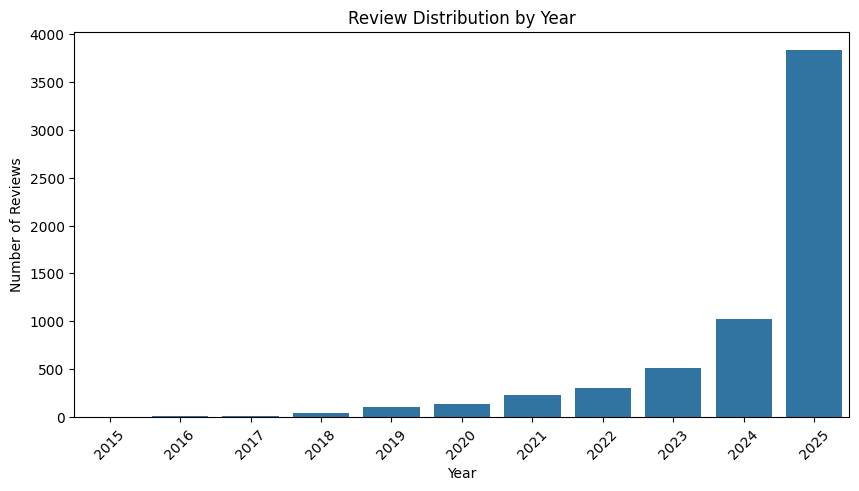

In [ ]:

df['time_readable'] = pd.to_datetime(
    df['time_readable'],
    errors='coerce'
)

df['review_year'] = df['time_readable'].dt.year

plt.figure(figsize=(10,5))

sns.countplot(
    x='review_year',
    data=df,
    order=sorted(df['review_year'].dropna().unique())
)

plt.title("Review Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=45)

plt.show()

### Filter Last 5 Years

In [ ]:

df['time_readable'] = pd.to_datetime(
    df['time_readable'],
    errors='coerce'
)

MIN_YEAR = 2021


df = df[
    df['time_readable'].dt.year >= MIN_YEAR
].copy()


df.reset_index(drop=True, inplace=True)

print("=== DATASET AFTER 5-YEAR FILTER ===")
print(df.shape)

print("\nYear Distribution:")
print(
    df['time_readable']
    .dt.year
    .value_counts()
    .sort_index()
)

=== DATASET AFTER 5-YEAR FILTER ===
(5905, 11)

Year Distribution:
time_readable
2021     227
2022     306
2023     510
2024    1027
2025    3835
Name: count, dtype: int64


### Aspect Frequency Analysis

=== ASPECT FREQUENCY ===


,Aspect,Frequency
0,Attractions and Activities,3239
2,Cleanliness and Environment,1521
1,Facilities and Amenities,1196
5,Crowds and Atmosphere,1020
3,Location and Accessibility,902
4,Price and Value,564


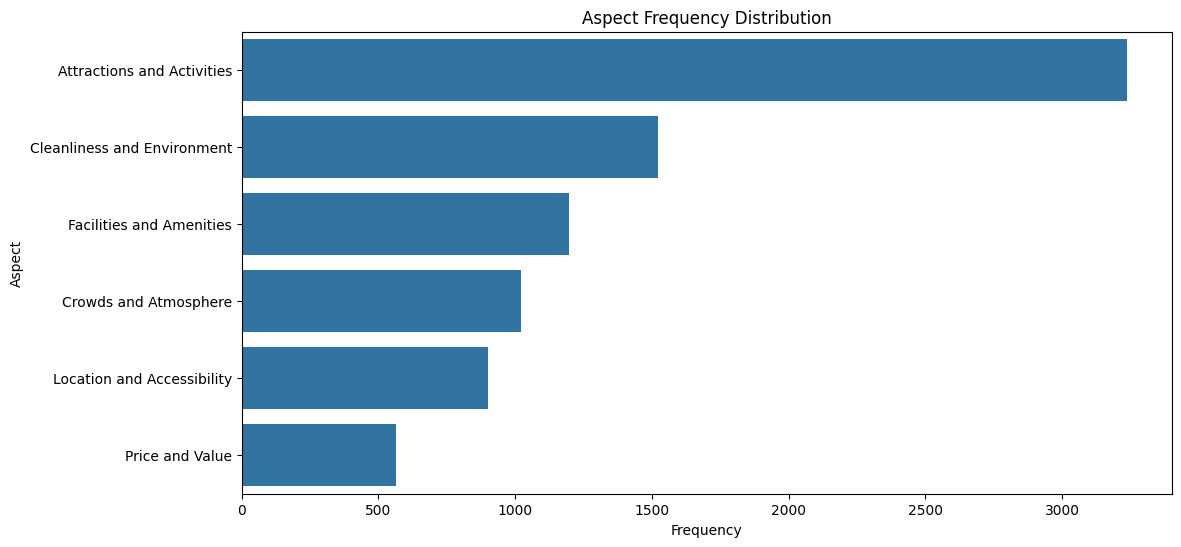

In [ ]:

aspect_cols = [
    "Attractions and Activities",
    "Facilities and Amenities",
    "Cleanliness and Environment",
    "Location and Accessibility",
    "Price and Value",
    "Crowds and Atmosphere"
]

aspect_frequency = {}

for col in aspect_cols:
    aspect_frequency[col] = df[col].notnull().sum()

aspect_df = pd.DataFrame({
    'Aspect': aspect_frequency.keys(),
    'Frequency': aspect_frequency.values()
})

aspect_df = aspect_df.sort_values(
    by='Frequency',
    ascending=False
)

print("=== ASPECT FREQUENCY ===")
display(aspect_df)

plt.figure(figsize=(12,6))

sns.barplot(
    data=aspect_df,
    x='Frequency',
    y='Aspect'
)

plt.title("Aspect Frequency Distribution")
plt.xlabel("Frequency")
plt.ylabel("Aspect")

plt.show()

## Aspect & Sentiment Distribution Analysis

In [ ]:


print("=== ASPECT DISTRIBUTION ANALYSIS ===")

aspect_cols = [
    "Attractions and Activities",
    "Facilities and Amenities",
    "Cleanliness and Environment",
    "Location and Accessibility",
    "Price and Value",
    "Crowds and Atmosphere"
]

missing_cols = [
    col for col in aspect_cols
    if col not in df.columns
]

if len(missing_cols) > 0:
    print("Missing Aspect Columns:")
    print(missing_cols)

else:
    print("All aspect columns detected successfully.")

aspect_frequency = {}

for col in aspect_cols:
    count = df[col].notnull().sum()
    aspect_frequency[col] = count

aspect_df = pd.DataFrame({
    "Aspect": list(aspect_frequency.keys()),
    "Frequency": list(aspect_frequency.values())
})

aspect_df = aspect_df.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

aspect_df["Percentage (%)"] = (
    aspect_df["Frequency"] / len(df)
) * 100

print("\n=== ASPECT FREQUENCY TABLE ===")

display(aspect_df)

=== ASPECT DISTRIBUTION ANALYSIS ===
All aspect columns detected successfully.

=== ASPECT FREQUENCY TABLE ===


,Aspect,Frequency,Percentage (%)
0,Attractions and Activities,3239,54.851820
1,Cleanliness and Environment,1521,25.757832
2,Facilities and Amenities,1196,20.254022
3,Crowds and Atmosphere,1020,17.273497
4,Location and Accessibility,902,15.275191
5,Price and Value,564,9.551228


### Aspect Distribution Visualization

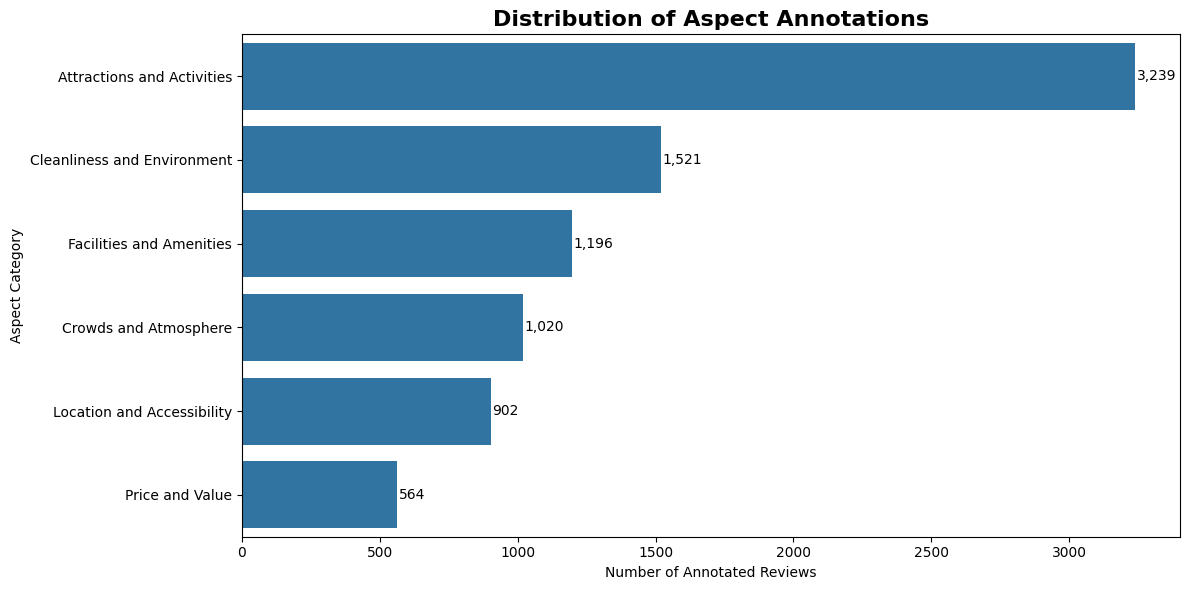

In [ ]:

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=aspect_df,
    x="Frequency",
    y="Aspect"
)

for i, row in aspect_df.iterrows():
    ax.text(
        row["Frequency"] + 5,
        i,
        f'{row["Frequency"]:,}',
        va='center'
    )


plt.title(
    "Distribution of Aspect Annotations",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Number of Annotated Reviews")
plt.ylabel("Aspect Category")

plt.tight_layout()

plt.show()

### Aspect Sentiment Breakdown

In [ ]:


all_sentiment_data = []

for aspect in aspect_cols:

    sentiment_counts = (
        df[aspect]
        .value_counts(dropna=True)
    )

    for sentiment, count in sentiment_counts.items():

        all_sentiment_data.append({
            "Aspect": aspect,
            "Sentiment": sentiment,
            "Count": count
        })


sentiment_aspect_df = pd.DataFrame(all_sentiment_data)

print("=== SENTIMENT DISTRIBUTION PER ASPECT ===")

display(sentiment_aspect_df)

=== SENTIMENT DISTRIBUTION PER ASPECT ===


,Aspect,Sentiment,Count
0,Attractions and Activities,positive,2681
1,Attractions and Activities,neutral,375
2,Attractions and Activities,negative,183
3,Facilities and Amenities,positive,688
4,Facilities and Amenities,negative,367
5,Facilities and Amenities,neutral,141
6,Cleanliness and Environment,positive,1186
7,Cleanliness and Environment,negative,299
8,Cleanliness and Environment,neutral,36
9,Location and Accessibility,negative,397


### Visualization Sentiment per Aspect

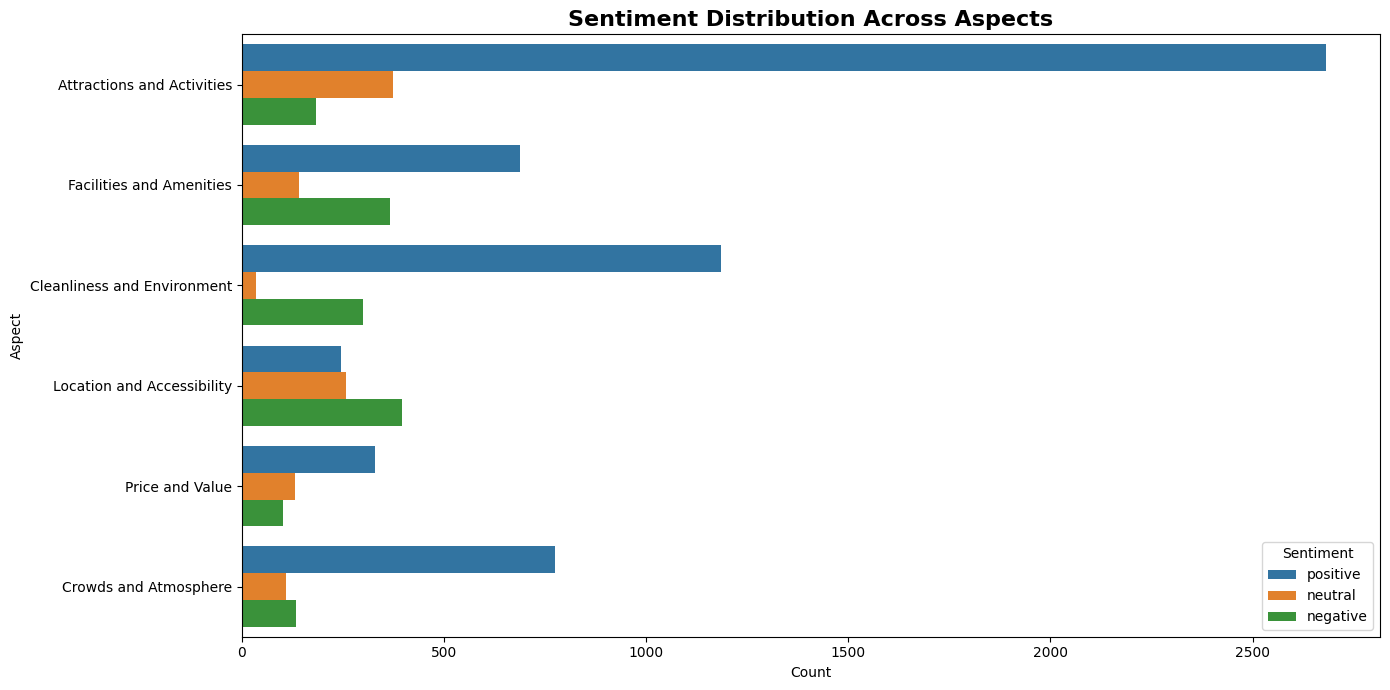

In [ ]:


plt.figure(figsize=(14,7))

sns.countplot(
    data=df.melt(
        value_vars=aspect_cols,
        var_name='Aspect',
        value_name='Sentiment'
    ),
    y='Aspect',
    hue='Sentiment'
)

plt.title(
    "Sentiment Distribution Across Aspects",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Count")
plt.ylabel("Aspect")

plt.legend(title='Sentiment')

plt.tight_layout()

plt.show()

In [ ]:

print("=== ANALYSIS CONCLUSION ===\n")

most_common_aspect = aspect_df.iloc[0]["Aspect"]
least_common_aspect = aspect_df.iloc[-1]["Aspect"]

print(f"Most frequent aspect  : {most_common_aspect}")
print(f"Least frequent aspect : {least_common_aspect}")

print("\nResearch Decision:")
print("- All aspects will be retained.")
print("- No aspect-based filtering is applied.")
print("- Aspect annotations are used as sentiment sources for majority voting.")
print("- Final task remains single-label sentiment classification.")

=== ANALYSIS CONCLUSION ===

Most frequent aspect  : Attractions and Activities
Least frequent aspect : Price and Value

Research Decision:
- All aspects will be retained.
- No aspect-based filtering is applied.
- Aspect annotations are used as sentiment sources for majority voting.
- Final task remains single-label sentiment classification.


## Label Preparation (Majority Voting)

In [ ]:


aspect_cols = [
    "Attractions and Activities",
    "Facilities and Amenities",
    "Cleanliness and Environment",
    "Location and Accessibility",
    "Price and Value",
    "Crowds and Atmosphere"
]

print("=== ASPECT COLUMNS ===")

for i, col in enumerate(aspect_cols, start=1):
    print(f"{i}. {col}")

=== ASPECT COLUMNS ===
1. Attractions and Activities
2. Facilities and Amenities
3. Cleanliness and Environment
4. Location and Accessibility
5. Price and Value
6. Crowds and Atmosphere


### Majority Voting Function

In [ ]:

from collections import Counter

def majority_vote(row):
    sentiments = []

    for col in aspect_cols:

        value = row[col]

        if pd.notnull(value):
            sentiments.append(str(value).lower().strip())

    if len(sentiments) == 0:
        return np.nan


    sentiment_counts = Counter(sentiments)

    max_count = max(sentiment_counts.values())

    candidates = [
        label
        for label, count in sentiment_counts.items()
        if count == max_count
    ]

    priority_order = [
        'positive',
        'neutral',
        'negative'
    ]

    for label in priority_order:
        if label in candidates:
            return label

### Apply Majority Voting

In [ ]:

print("Applying majority voting...")
df['sentiment'] = df.apply(
    majority_vote,
    axis=1
)

print("Majority voting completed.")

preview_cols = aspect_cols + ['sentiment']

display(df[preview_cols].head(10))

Applying majority voting...
Majority voting completed.


,Attractions and Activities,Facilities and Amenities,Cleanliness and Environment,Location and Accessibility,Price and Value,Crowds and Atmosphere,sentiment
0,positive,NaN,NaN,NaN,NaN,NaN,positive
1,NaN,NaN,positive,NaN,NaN,NaN,positive
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,neutral,NaN,NaN,NaN,neutral
4,neutral,NaN,NaN,negative,NaN,NaN,neutral
5,NaN,NaN,NaN,negative,NaN,NaN,negative
6,NaN,NaN,positive,NaN,NaN,positive,positive
7,NaN,NaN,NaN,neutral,NaN,NaN,neutral
8,NaN,neutral,NaN,NaN,NaN,NaN,neutral
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Remove Rows Without Label

In [ ]:

print("=== BEFORE DROPPING ===")
print(df.shape)

df_labeled = df.dropna(
    subset=['sentiment']
).copy()

df_labeled.reset_index(
    drop=True,
    inplace=True
)

print("\n=== AFTER DROPPING ===")
print(df_labeled.shape)

removed_rows = len(df) - len(df_labeled)

print(f"\nRemoved rows without sentiment label: {removed_rows}")

=== BEFORE DROPPING ===
(5905, 12)

=== AFTER DROPPING ===
(4913, 12)

Removed rows without sentiment label: 992


### Final Dataset Selection

In [ ]:

final_cols = [
    'text',
    'sentiment'
]

df_labeled = df_labeled[final_cols].copy()


df_labeled.rename(
    columns={
        'text': 'review_text'
    },
    inplace=True
)

print("=== FINAL LABELED DATASET ===")

display(df_labeled.head())

print("\nDataset Shape:")
print(df_labeled.shape)

=== FINAL LABELED DATASET ===


,review_text,sentiment
0,Ikannya nyamber terus,positive
1,Kebun kopi dengan pemandangan yang indah,positive
2,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",neutral
3,Yg suka berpetualangan silahkan ke pantai sumenggung...tp klw musim hujan jln nya becak...😂,neutral
4,Jalannya becek,negative



Dataset Shape:
(4913, 2)


#### Save Final Labelled

In [ ]:

output_filename = "df_labeled_majority_voting_2021_2025.csv"

save_path = base_path + output_filename

df_labeled.to_csv(
    save_path,
    index=False,
    encoding='utf-8-sig'
)

print("=== DATASET SAVED SUCCESSFULLY ===")
print(f"Location : {save_path}")

print("\nDataset Shape:")
print(df_labeled.shape)

=== DATASET SAVED SUCCESSFULLY ===
Location : /content/drive/MyDrive/Data TA/df_labeled_majority_voting_2021_2025.csv

Dataset Shape:
(4913, 2)


#### Load Data

In [ ]:
df_labeled = pd.read_csv(
    base_path + "df_labeled_majority_voting_2021_2025.csv"
)

print("=== LABELED DATASET LOADED ===")

print("\nShape:")
print(df_labeled.shape)

print("\nSample Data:")
display(df_labeled.head())

print("\nLabel Distribution:")
print(df_labeled['sentiment'].value_counts())

=== LABELED DATASET LOADED ===

Shape:
(4913, 2)

Sample Data:


,review_text,sentiment
0,Ikannya nyamber terus,positive
1,Kebun kopi dengan pemandangan yang indah,positive
2,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",neutral
3,Yg suka berpetualangan silahkan ke pantai sumenggung...tp klw musim hujan jln nya becak...😂,neutral
4,Jalannya becek,negative



Label Distribution:
sentiment
positive    3731
negative     605
neutral      577
Name: count, dtype: int64


## EDA

### EDA Setup

In [ ]:
print("=== POST-LABELING EDA ===")

print("\nDataset Shape:")
print(df_labeled.shape)

print("\nColumns:")
print(df_labeled.columns.tolist())

print("\nSentiment Labels:")
print(df_labeled['sentiment'].unique())

=== POST-LABELING EDA ===

Dataset Shape:
(4913, 2)

Columns:
['review_text', 'sentiment']

Sentiment Labels:
['positive' 'neutral' 'negative']


### Sentiment Distribution

=== SENTIMENT DISTRIBUTION ===


,Count,Percentage (%)
sentiment,,
positive,3731,75.94
negative,605,12.31
neutral,577,11.74


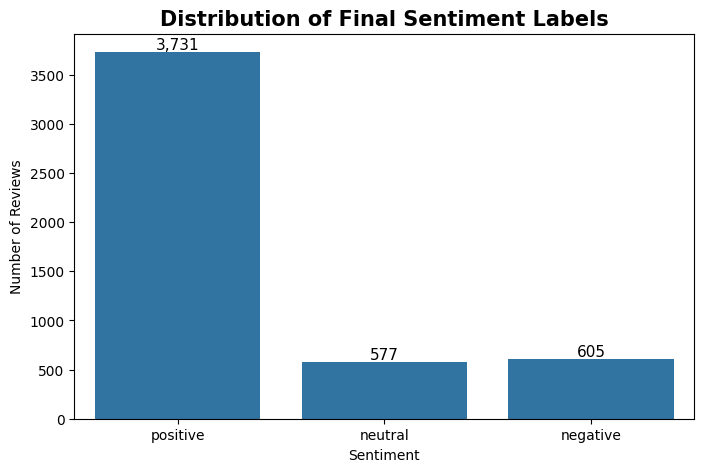

In [ ]:
sentiment_counts = (
    df_labeled['sentiment']
    .value_counts()
)

sentiment_percentages = (
    df_labeled['sentiment']
    .value_counts(normalize=True)
) * 100


distribution_df = pd.DataFrame({
    'Count': sentiment_counts,
    'Percentage (%)': sentiment_percentages.round(2)
})

print("=== SENTIMENT DISTRIBUTION ===")

display(distribution_df)

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df_labeled,
    x='sentiment',
    order=['positive', 'neutral', 'negative']
)

for p in ax.patches:

    ax.annotate(
        f'{int(p.get_height()):,}',
        (
            p.get_x() + p.get_width()/2,
            p.get_height()
        ),
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.title(
    "Distribution of Final Sentiment Labels",
    fontsize=15,
    fontweight='bold'
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

### Pie Chart Distribution

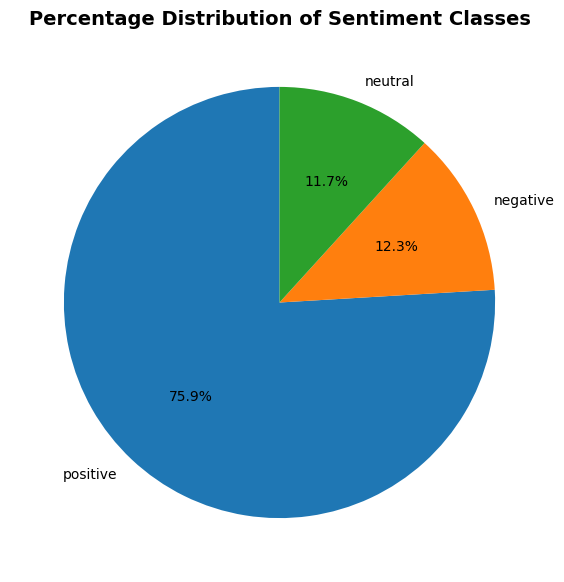

In [ ]:
plt.figure(figsize=(7,7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title(
    "Percentage Distribution of Sentiment Classes",
    fontsize=14,
    fontweight='bold'
)

plt.show()

### Calculate Review Length

In [ ]:
df_labeled['char_length'] = (
    df_labeled['review_text']
    .astype(str)
    .apply(len)
)

df_labeled['word_length'] = (
    df_labeled['review_text']
    .astype(str)
    .apply(lambda x: len(x.split()))
)

length_summary = (
    df_labeled
    .groupby('sentiment')[
        ['char_length', 'word_length']
    ]
    .agg(['mean', 'median', 'max'])
)

print("=== REVIEW LENGTH SUMMARY ===")

display(length_summary)

=== REVIEW LENGTH SUMMARY ===


char_length              word_length            
                 mean median   max        mean median  max
sentiment                                                 
negative   150.376860   80.0  2566   23.452893   12.0  371
neutral    106.237435   44.0  2495   16.322357    7.0  353
positive   123.666845   64.0  3080   18.763602   10.0  439

### Boxplot Review Length

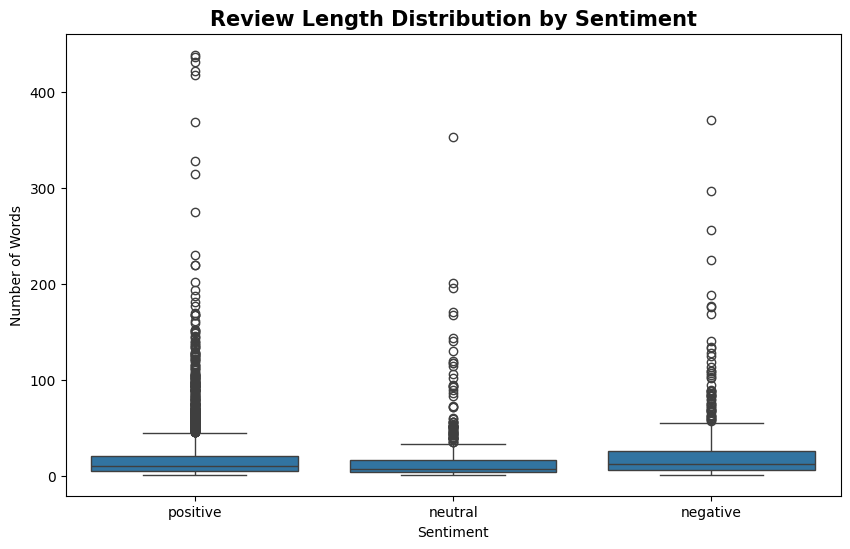

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df_labeled,
    x='sentiment',
    y='word_length',
    order=['positive', 'neutral', 'negative']
)

plt.title(
    "Review Length Distribution by Sentiment",
    fontsize=15,
    fontweight='bold'
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.show()

### Top Word Frequency

In [ ]:
from collections import Counter



def get_top_words(text_series, n=20):

    all_words = " ".join(
        text_series.astype(str)
    ).lower().split()

    counter = Counter(all_words)

    return pd.DataFrame(
        counter.most_common(n),
        columns=['Word', 'Frequency']
    )


top_words_dict = {}

for sentiment in ['positive', 'neutral', 'negative']:

    temp_df = df_labeled[
        df_labeled['sentiment'] == sentiment
    ]

    top_words = get_top_words(
        temp_df['review_text'],
        n=20
    )

    top_words_dict[sentiment] = top_words

    print(f"\n=== TOP WORDS: {sentiment.upper()} ===")

    display(top_words)


=== TOP WORDS: POSITIVE ===


,Word,Frequency
0,dan,1909
1,yang,1402
2,di,1199
3,untuk,918
4,tempat,809
5,pantai,708
6,ada,678
7,sangat,604
8,bagus,603
9,yg,574



=== TOP WORDS: NEUTRAL ===


,Word,Frequency
0,di,202
1,dan,173
2,yang,135
3,ada,125
4,ke,104
5,untuk,97
6,tempat,89
7,bisa,81
8,dari,77
9,pantai,76



=== TOP WORDS: NEGATIVE ===


,Word,Frequency
0,di,271
1,dan,240
2,ada,212
3,tidak,211
4,yang,177
5,yg,140
6,ke,124
7,saya,118
8,jalan,114
9,tempat,110


### Visualization Top Words

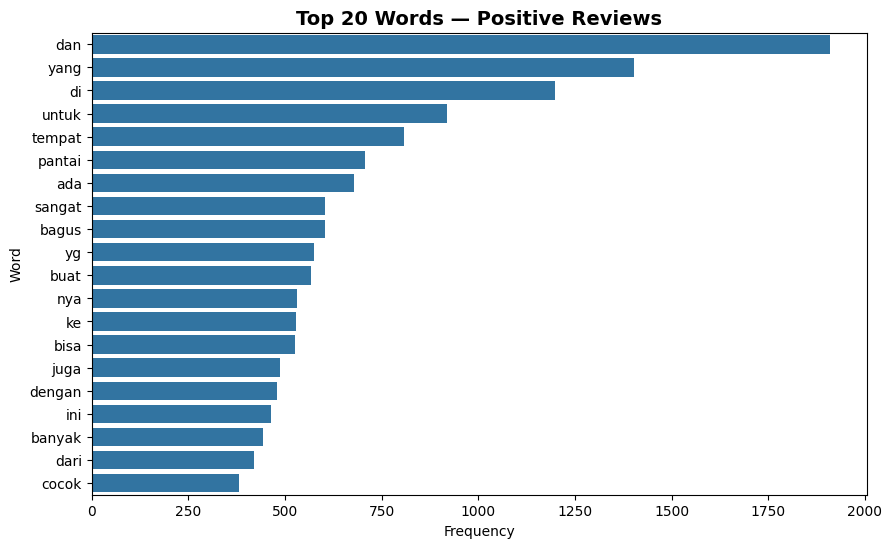

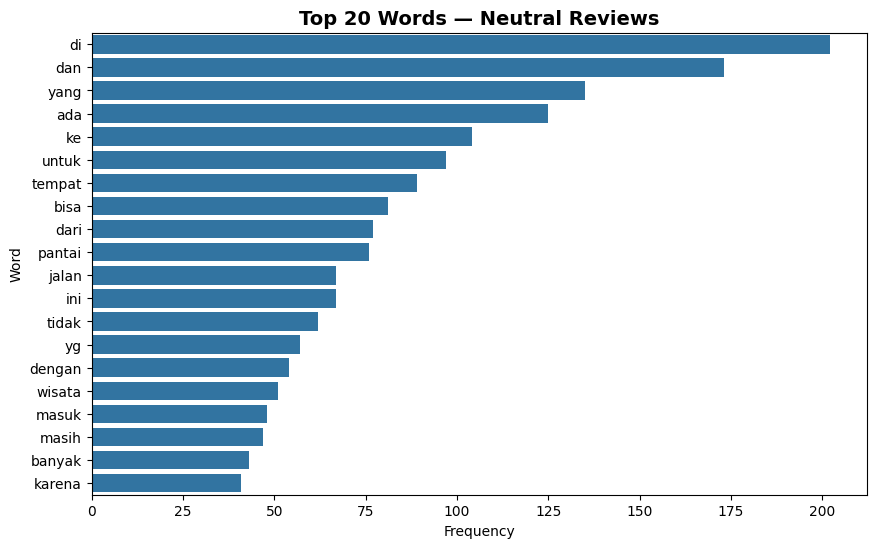

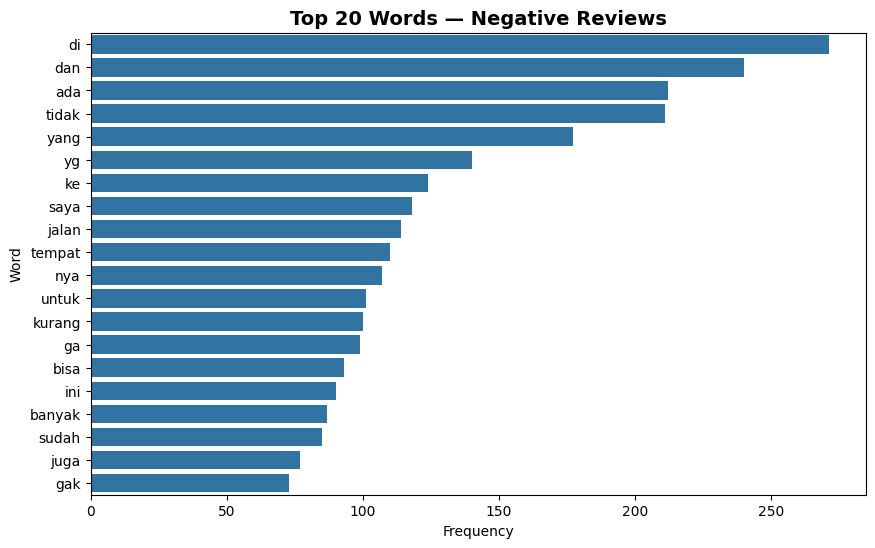

In [ ]:
for sentiment in ['positive', 'neutral', 'negative']:

    top_df = top_words_dict[sentiment]

    plt.figure(figsize=(10,6))

    sns.barplot(
        data=top_df,
        x='Frequency',
        y='Word'
    )

    plt.title(
        f"Top 20 Words — {sentiment.capitalize()} Reviews",
        fontsize=14,
        fontweight='bold'
    )

    plt.xlabel("Frequency")
    plt.ylabel("Word")

    plt.show()

### Emoji Frequency Analysis


=== TOP EMOJI: POSITIVE ===


,Emoji,Frequency
0,👍,202
1,😍,56
2,🙏,41
3,🏻,37
4,🥰,35
5,🤩,32
6,😁,29
7,✨,28
8,❤,25
9,🌊,23



=== TOP EMOJI: NEUTRAL ===


,Emoji,Frequency
0,🙏,5
1,🏻,5
2,😭,5
3,😁,5
4,🤣,5
5,🤤,4
6,😬,4
7,😅,3
8,😂,2
9,👍,2



=== TOP EMOJI: NEGATIVE ===


,Emoji,Frequency
0,🤣,16
1,🙏,14
2,😭,10
3,👎,7
4,🤮,7
5,😂,5
6,😁,4
7,🏻,4
8,🤢,4
9,😌,4


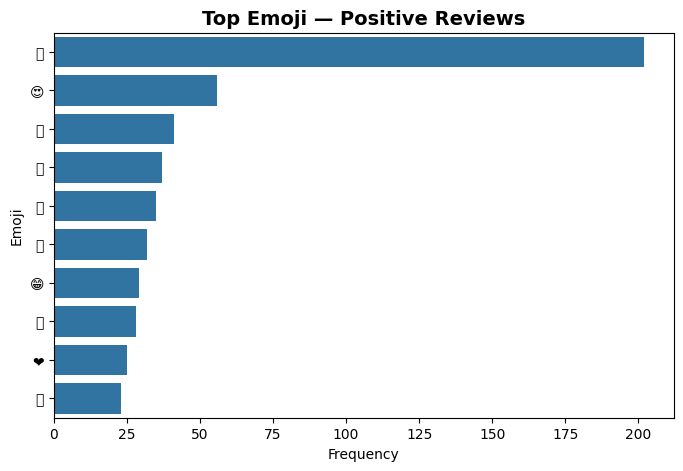

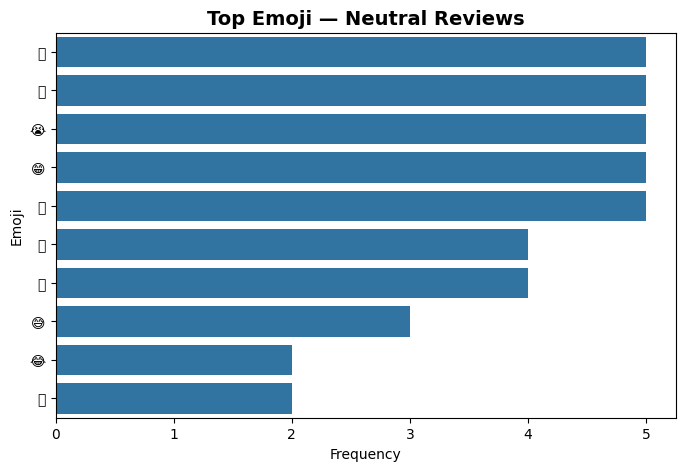

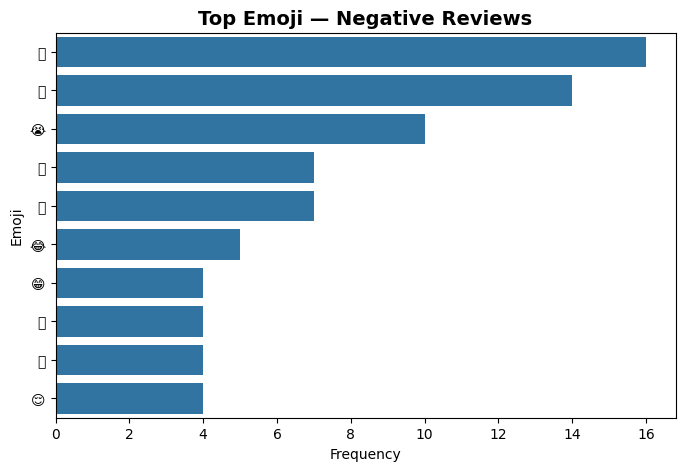

In [ ]:
from collections import Counter
import emoji

def extract_emojis(text):

    return [
        char for char in str(text)
        if char in emoji.EMOJI_DATA
    ]



emoji_results = {}

for sentiment in ['positive', 'neutral', 'negative']:

    texts = df_labeled[
        df_labeled['sentiment'] == sentiment
    ]['review_text']

    emojis_all = []

    for text in texts:
        emojis_all.extend(
            extract_emojis(text)
        )

    emoji_counter = Counter(emojis_all)

    emoji_df = pd.DataFrame(
        emoji_counter.most_common(10),
        columns=['Emoji', 'Frequency']
    )

    emoji_results[sentiment] = emoji_df

    print(f"\n=== TOP EMOJI: {sentiment.upper()} ===")

    display(emoji_df)

# EMOJI VISUALIZATION


for sentiment in ['positive', 'neutral', 'negative']:

    emoji_df = emoji_results[sentiment]

    if len(emoji_df) == 0:
        continue

    plt.figure(figsize=(8,5))

    sns.barplot(
        data=emoji_df,
        x='Frequency',
        y='Emoji'
    )

    plt.title(
        f"Top Emoji — {sentiment.capitalize()} Reviews",
        fontsize=14,
        fontweight='bold'
    )

    plt.xlabel("Frequency")
    plt.ylabel("Emoji")

    plt.show()

### Imbalance Ratio

In [ ]:
print("=== IMBALANCE ANALYSIS ===")

label_counts = (
    df_labeled['sentiment']
    .value_counts()
)

print("\nLabel Counts:")
print(label_counts)


majority_class = label_counts.max()
minority_class = label_counts.min()

imbalance_ratio = (
    majority_class / minority_class
)

print(f"\nMajority Class Count : {majority_class}")
print(f"Minority Class Count : {minority_class}")

print(f"\nImbalance Ratio : {imbalance_ratio:.2f}")

=== IMBALANCE ANALYSIS ===

Label Counts:
sentiment
positive    3731
negative     605
neutral      577
Name: count, dtype: int64

Majority Class Count : 3731
Minority Class Count : 577

Imbalance Ratio : 6.47


In [ ]:
print("=== EDA SUMMARY ===\n")

dominant_sentiment = (
    df_labeled['sentiment']
    .value_counts()
    .idxmax()
)

print(f"Dominant Sentiment : {dominant_sentiment}")

print(f"Imbalance Ratio    : {imbalance_ratio:.2f}")

print("\nMain Findings:")

print("- Positive sentiment dominates tourism reviews.")
print("- Review lengths vary across sentiment classes.")
print("- Emoji usage appears frequently in informal reviews.")
print("- Dataset shows characteristics of informal Indonesian text.")
print("- Macro F1-score is appropriate due to class imbalance.")

=== EDA SUMMARY ===

Dominant Sentiment : positive
Imbalance Ratio    : 6.47

Main Findings:
- Positive sentiment dominates tourism reviews.
- Review lengths vary across sentiment classes.
- Emoji usage appears frequently in informal reviews.
- Dataset shows characteristics of informal Indonesian text.
- Macro F1-score is appropriate due to class imbalance.


## Preprocessing

### Raw Text Exploration

In [ ]:
matplotlib.rcParams['figure.dpi'] = 120

# Load dataset berlabel
base_path = '/content/drive/MyDrive/Data TA/'
df_labeled = pd.read_csv(base_path + 'df_labeled_majority_voting_2021_2025.csv')

print(f"Dataset shape: {df_labeled.shape}")
print(f"Kolom: {df_labeled.columns.tolist()}")
display(df_labeled.head(3))

# ── 1. Cek karakter unik / noise pattern ──────────────────
print("\n" + "="*60)
print("SAMPLE TEKS MENTAH (per sentimen)")
print("="*60)
for sentiment in ['positive', 'neutral', 'negative']:
    sample = df_labeled[df_labeled['sentiment'] == sentiment]['review_text'].sample(5, random_state=42)
    print(f"\n── {sentiment.upper()} ──")
    for i, text in enumerate(sample, 1):
        print(f"  [{i}] {text[:120]}")

# ── 2. Deteksi emoji dalam korpus ──────────────────────────
print("\n" + "="*60)
print("ANALISIS EMOJI DALAM KORPUS")
print("="*60)

all_emojis = []
emoji_per_sentiment = {}

for sentiment in ['positive', 'neutral', 'negative']:
    texts = df_labeled[df_labeled['sentiment'] == sentiment]['review_text']
    emojis_found = []
    for text in texts:
        if isinstance(text, str):
            emojis_found.extend([char for char in text if char in emoji.EMOJI_DATA])
    emoji_per_sentiment[sentiment] = emojis_found
    all_emojis.extend(emojis_found)

emoji_freq = Counter(all_emojis)
print(f"Total token emoji dalam korpus: {len(all_emojis)}")
print(f"Jumlah review mengandung emoji: {df_labeled['review_text'].apply(lambda x: any(c in emoji.EMOJI_DATA for c in str(x))).sum()}")
print(f"\nTop-30 emoji terbanyak:")
for em, count in emoji_freq.most_common(30):
    print(f"  {em}  →  {count}x")

# Proporsi review dengan emoji per sentimen
print("\nProporsi review berisi emoji per sentimen:")
for sent, emojis in emoji_per_sentiment.items():
    n_reviews = len(df_labeled[df_labeled['sentiment'] == sent])
    n_with_emoji = df_labeled[df_labeled['sentiment'] == sent]['review_text'].apply(
        lambda x: any(c in emoji.EMOJI_DATA for c in str(x))
    ).sum()
    print(f"  {sent}: {n_with_emoji}/{n_reviews} ({n_with_emoji/n_reviews*100:.1f}%)")

# ── 3. Deteksi URL, mention, hashtag ──────────────────────
print("\n" + "="*60)
print("DETEKSI NOISE PATTERNS")
print("="*60)

patterns = {
    'URL'      : r'https?://\S+|www\.\S+',
    'Mention'  : r'@\w+',
    'Hashtag'  : r'#\w+',
    'Angka saja': r'^\d+$',
    'Capslock dominan': r'[A-Z]{4,}',
    'Pengulangan karakter': r'(.)\1{2,}',
}
for pattern_name, pattern in patterns.items():
    count = df_labeled['review_text'].str.contains(pattern, regex=True, na=False).sum()
    print(f"  {pattern_name}: {count} review")

# ── 4. Deteksi kata non-standar / slang ──────────────────
print("\n" + "="*60)
print("TOP-100 KATA PALING SERING (setelah lowercase, untuk identifikasi slang)")
print("="*60)

all_words = []
for text in df_labeled['review_text'].dropna():
    words = re.sub(r'[^a-zA-Z\s]', ' ', text.lower()).split()
    all_words.extend(words)

word_freq = Counter(all_words)
# Filter kata pendek (< 2 karakter) dan angka
word_freq_filtered = {w: c for w, c in word_freq.items() if len(w) >= 2 and not w.isdigit()}
word_freq_sorted = sorted(word_freq_filtered.items(), key=lambda x: -x[1])

print("Top-100 kata (identifikasi mana yang perlu normalisasi):")
for i, (word, count) in enumerate(word_freq_sorted[:100], 1):
    print(f"  {i:3}. {word:<20} {count}")

# ── 5. Simpan daftar kata untuk analisis manual ───────────
# Export ke CSV agar bisa dilihat lebih mudah
df_words = pd.DataFrame(word_freq_sorted[:500], columns=['kata', 'frekuensi'])
df_words.to_csv(base_path + 'word_frequency_raw.csv', index=False)
print("\n✓ Daftar 500 kata terbanyak disimpan ke word_frequency_raw.csv")
print("  → Buka file ini, identifikasi kata slang/singkatan yang perlu dinormalisasi")

Dataset shape: (4913, 2)
Kolom: ['review_text', 'sentiment']


,review_text,sentiment
0,Ikannya nyamber terus,positive
1,Kebun kopi dengan pemandangan yang indah,positive
2,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",neutral



SAMPLE TEKS MENTAH (per sentimen)

── POSITIVE ──
  [1] Cukup luas dan nyaman buat anak-anak. Jajanannya jg komplit.
  [2] view nya indah
  [3] Terletak di kelurahan Pandean.
Tempat yg cocok untuk menikmati sunset di di sore hari 🤩
  [4] Harga affordable layanan ramah cm untuk usia di atas 6thn yg antar ga bs tunggu di dlm pdhl dulu boleh tunggu di dlm
  [5] Kami ke Gunung Masjid berangkat pagi sekali krn kl kita kesiangan berangkatnya.Panasnya bukan main wkt kita pendakian.Da

── NEUTRAL ──
  [1] Merupakan pusat penelitian dengan produk utama kopi dan kakao. Hasil olahan kopi dan kakao dapat dibeli di outlet Puslit
  [2] Peternak ayam ekor lidi
  [3] Pantai indah dibalik bukit.. indahh dan masih alami. kesana harus mendaki bukit dan menuruninya
deburan ombak begitu ter
  [4] Di atas bibir pantai , dan di apit kebun kopi dan pemakaman
  [5] Tempat nya nya nyaman masih asri, tp sayang banyak sampah nya.

── NEGATIVE ──
  [1] Tempat nya enak buat camping rame², paling susah cari air ber

### Build a Corpus-Based NORM_DICT

In [ ]:
# ============================================================
# CELL 5B — BUILD SEMI-AUTOMATIC NORM_DICT
# ============================================================

print("="*70)
print("BUILD CORPUS-DRIVEN NORMALIZATION DICTIONARY")
print("="*70)

# ============================================================
# 1. LOAD WORD FREQUENCY HASIL CELL 5A
# ============================================================

df_words = pd.read_csv(base_path + 'word_frequency_raw.csv')

print(f"Jumlah kata unik hasil eksplorasi: {len(df_words):,}")

display(df_words.head(20))

# ============================================================
# 2. DETEKSI KANDIDAT KATA NON-STANDAR
# ============================================================
# Heuristik:
# - kata pendek slang
# - singkatan
# - karakter berulang
# - typo informal
# - code-switching umum
# ============================================================

def detect_candidate_slang(word):

    # karakter berulang
    repeated = bool(re.search(r'(.)\1{2,}', word))

    # singkatan pendek
    short_form = len(word) <= 4

    # tidak full alfabet formal
    informal_pattern = bool(re.search(r'[0-9]', word))

    return repeated or short_form or informal_pattern

df_words['candidate_slang'] = df_words['kata'].apply(detect_candidate_slang)

candidate_words = df_words[
    df_words['candidate_slang'] == True
].copy()

print(f"\nJumlah kandidat slang/non-standar: {len(candidate_words)}")

display(candidate_words.head(50))

# ============================================================
# 3. MANUAL VALIDATION TABLE
# ============================================================
# Peneliti melakukan validasi manual terhadap candidate slang
# untuk memastikan tidak terjadi over-normalization.
# ============================================================

print("\n" + "="*70)
print("TOP CANDIDATE WORDS UNTUK VALIDASI MANUAL")
print("="*70)

display(
    candidate_words[
        ['kata', 'frekuensi']
    ].sort_values(
        by='frekuensi',
        ascending=False
    ).head(100)
)

# ============================================================
# 4. FINAL CORPUS-DRIVEN NORM DICTIONARY
# ============================================================
# Dibangun berdasarkan hasil validasi manual candidate words.
# HANYA kata yang benar-benar muncul dalam korpus dimasukkan.
# ============================================================

NORM_DICT = {

    # ========================================================
    # NEGATION
    # ========================================================
    "gak"       : "tidak",
    "ga"        : "tidak",
    "gk"        : "tidak",
    "nggak"     : "tidak",
    "ngga"      : "tidak",
    "enggak"    : "tidak",
    "tdk"       : "tidak",
    "tak"       : "tidak",
    "ndak"      : "tidak",

    # ========================================================
    # INTENSIFIER
    # ========================================================
    "bgt"       : "banget",
    "bngt"      : "banget",
    "sgt"       : "sangat",
    "sngt"      : "sangat",

    # ========================================================
    # INFORMAL PRONOUN
    # ========================================================
    "sy"        : "saya",
    "gw"        : "saya",
    "gue"       : "saya",
    "km"        : "kamu",
    "lu"        : "kamu",

    # ========================================================
    # INFORMAL CONNECTOR
    # ========================================================
    "yg"        : "yang",
    "dgn"       : "dengan",
    "krn"       : "karena",
    "utk"       : "untuk",
    "dr"        : "dari",
    "tp"        : "tapi",
    "tpi"       : "tapi",

    # ========================================================
    # TOURISM DOMAIN
    # ========================================================
    "tmpt"      : "tempat",
    "tmpat"     : "tempat",
    "wc"        : "toilet",
    "view"      : "pemandangan",
    "spot"      : "lokasi foto",

    # ========================================================
    # ENGLISH CODE-SWITCHING
    # ========================================================
    "worth it"  : "sepadan",
    "recommended": "direkomendasikan",
    "nice"      : "bagus",
    "good"      : "bagus",
    "bad"       : "buruk",
    "crowded"   : "ramai",
    "clean"     : "bersih",
    "dirty"     : "kotor",
}

print("\nJumlah final NORM_DICT:", len(NORM_DICT))

# ============================================================
# 5. VALIDASI COVERAGE KAMUS
# ============================================================

korpus_words = set(df_words['kata'].tolist())
dict_words   = set(NORM_DICT.keys())

matched_words = dict_words.intersection(korpus_words)

coverage = len(matched_words) / len(dict_words) * 100

print("\n" + "="*70)
print("NORM_DICT COVERAGE")
print("="*70)

print(f"Kata dalam NORM_DICT      : {len(dict_words)}")
print(f"Ditemukan dalam korpus    : {len(matched_words)}")
print(f"Coverage                  : {coverage:.2f}%")

print("\nMatched words:")
print(sorted(matched_words))

# ============================================================
# 6. EXPORT UNTUK REPRODUCIBILITY
# ============================================================

df_norm = pd.DataFrame({
    'non_standard': list(NORM_DICT.keys()),
    'normalized'  : list(NORM_DICT.values())
})

df_norm.to_csv(
    base_path + 'corpus_driven_norm_dict.csv',
    index=False
)

print("\n✓ NORM_DICT berhasil disimpan")
print("→ corpus_driven_norm_dict.csv")

BUILD CORPUS-DRIVEN NORMALIZATION DICTIONARY
Jumlah kata unik hasil eksplorasi: 500


,kata,frekuensi
0,dan,2364
1,yang,1718
2,di,1685
3,untuk,1127
4,ada,1063
5,tempat,1042
6,pantai,954
7,bagus,921
8,nya,790
9,yg,777



Jumlah kandidat slang/non-standar: 157


,kata,frekuensi,candidate_slang
0,dan,2364,True
1,yang,1718,True
2,di,1685,True
4,ada,1063,True
8,nya,790,True
9,yg,777,True
10,ke,763,True
11,ini,739,True
12,bisa,721,True
14,juga,669,True



TOP CANDIDATE WORDS UNTUK VALIDASI MANUAL


,kata,frekuensi
0,dan,2364
1,yang,1718
2,di,1685
4,ada,1063
8,nya,790
9,yg,777
10,ke,763
11,ini,739
12,bisa,721
14,juga,669



Jumlah final NORM_DICT: 38

NORM_DICT COVERAGE
Kata dalam NORM_DICT      : 38
Ditemukan dalam korpus    : 17
Coverage                  : 44.74%

Matched words:
['bgt', 'dgn', 'dr', 'ga', 'gak', 'gk', 'krn', 'ngga', 'nggak', 'recommended', 'spot', 'tak', 'tdk', 'tp', 'utk', 'view', 'yg']

✓ NORM_DICT berhasil disimpan
→ corpus_driven_norm_dict.csv


### Preprocessing Function

In [ ]:
# ============================================================
# CELL 5C — FUNGSI PREPROCESSING
# ============================================================

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Inisialisasi Sastrawi
stop_factory    = StopWordRemoverFactory()
stemmer_factory = StemmerFactory()
stopword_remover = stop_factory.create_stop_word_remover()
stemmer          = stemmer_factory.create_stemmer()

# Tambahkan stopword custom (domain pariwisata — tidak berkontribusi pada sentimen)
# custom_stopwords_to_add = {
#     'ya', 'yah', 'deh', 'sih', 'nih', 'lho', 'dong', 'kok',
#     'wah', 'ah', 'oh', 'eh', 'hmm', 'hm', 'hehe', 'haha',
#     'aja', 'ajah', 'banget',  # 'banget' kadang stopword, tapi hati-hati
# }
# CATATAN: 'banget' adalah intensifier sentimen, pertimbangkan untuk TIDAK dimasukkan
# ke stopword jika ingin menjaga sinyal intensitas sentimen

def normalize_repeated_chars(text: str) -> str:
    """
    Normalisasi pengulangan karakter lebih dari 2x.
    Contoh: 'bagussss' → 'bagus', 'mantappp' → 'mantap'
    Justifikasi: Pengulangan karakter adalah penanda ekspresivitas fonetis
    dalam tulisan informal, namun tidak mengubah makna leksikal kata.
    """
    return re.sub(r'(.)\1{2,}', r'\1\1', text)
    # Pertahankan 2 karakter (bukan 1) karena ada kata valid dengan double char
    # Contoh: 'aa' valid (Aa = nama), 'oo' kadang valid
    # Kalau mau lebih agresif ganti r'\1' (1 karakter)

def apply_norm_dict(text: str, norm_dict: dict) -> str:
    """
    Terapkan kamus normalisasi dengan word-boundary matching.
    Menggunakan word boundary (\b) untuk menghindari partial replacement.
    Contoh tanpa \b: 'tidak' → mengubah 'ketidakhadiran' jadi 'ketidakhadiran' (salah)
    """
    words = text.split()
    normalized = []
    for word in words:
        # Cek exact match terlebih dahulu
        if word in norm_dict:
            normalized.append(norm_dict[word])
        else:
            normalized.append(word)
    return ' '.join(normalized)

def handle_emoji(text: str, mode: str = 'remove') -> str:
    """
    Dua mode penanganan emoji:

    - 'remove'
        Menghapus seluruh emoji dari teks.

    - 'keep'
        Mempertahankan emoji asli dalam teks.

    Justifikasi Akademik:
    Emoji pada ulasan wisata sering mengandung sinyal sentimen eksplisit,
    seperti 😍 (kekaguman), 😡 (kemarahan), atau 🔥 (antusiasme).

    Pada model berbasis transformer seperti IndoBERTweet, mempertahankan
    emoji asli lebih sesuai dibanding mengubahnya menjadi deskripsi teks,
    karena model telah dipretrain pada distribusi teks media sosial yang
    secara alami mengandung emoji.

    Oleh karena itu, penelitian ini mempertahankan emoji dalam bentuk
    original Unicode untuk menjaga distribusi linguistik alami korpus.
    """

    if mode == 'remove':
        return emoji.replace_emoji(text, replace='')

    elif mode == 'keep':
        return text

    else:
        raise ValueError(
            f"mode harus 'remove' atau 'keep', bukan '{mode}'"
        )

def preprocess(text: str,
               emoji_mode: str = 'remove',
               use_stemming: bool = False,
               remove_stopwords: bool = True) -> str:
    """
    Fungsi preprocessing utama dengan parameter yang configurable.

    Args:
        text           : teks input
        emoji_mode     : 'remove' atau 'keep'
        use_stemming   : True/False — default False untuk menjaga kompatibilitas BERT
        remove_stopwords: True/False — default True

    Returns:
        str: teks yang sudah dipreprocess

    Pipeline urutan langkah:
    1. Validasi input
    2. Handle emoji (sebelum lowercase agar emoji terdeteksi dengan benar)
    3. Lowercase
    4. Remove URL, mention, hashtag
    5. Normalisasi pengulangan karakter
    6. Terapkan NORM_DICT
    7. Remove karakter non-alfanumerik
    8. Stopword removal (opsional)
    9. Stemming (opsional)
    10. Trim whitespace
    """
    # ── Step 1: Validasi ──────────────────────────────────
    if not isinstance(text, str) or text.strip() == '':
        return ''

    # ── Step 2: Handle emoji ──────────────────────────────
    text = handle_emoji(text, mode=emoji_mode)

    # ── Step 3: Lowercase ─────────────────────────────────
    text = text.lower()

    # ── Step 4: Remove URL, mention, hashtag, angka ───────
    text = re.sub(r'https?://\S+|www\.\S+', '', text)     # URL
    text = re.sub(r'@\w+', '', text)                       # mention
    text = re.sub(r'#\w+', '', text)                       # hashtag
    # Pertahankan angka? Untuk ulasan wisata, angka seperti "5 bintang",
    # "100 ribu", bisa informatif. Kita hapus angka standalone saja.
    text = re.sub(r'\b\d+\b', '', text)

    # ── Step 5: Normalisasi pengulangan karakter ──────────
    text = normalize_repeated_chars(text)

    # ── Step 6: Terapkan NORM_DICT ────────────────────────
    text = apply_norm_dict(text, NORM_DICT)

    # ── Step 7: Remove karakter non-alfanumerik ───────────
    if emoji_mode == 'keep':
        # Pertahankan emoji Unicode
        # Hapus simbol aneh selain huruf, angka, spasi, dan emoji
        text = re.sub(
            r'[^\w\s\U0001F300-\U0001FAFF]',
            ' ',
            text
        )
    else:
        # Untuk mode remove, emoji sudah dihapus
        text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # ── Step 8: Stopword removal ──────────────────────────
    if remove_stopwords:
        text = stopword_remover.remove(text)

    # ── Step 9: Stemming (opsional) ───────────────────────
    # PERINGATAN: Untuk IndoBERTweet, stemming TIDAK disarankan karena
    # model menggunakan subword tokenization (WordPiece/BPE) yang sudah
    # menangani morfologi kata. Stemming agresif dapat merusak
    # representasi subword yang dioptimalkan selama pretraining.
    # Hanya aktifkan untuk TF-IDF + LR baseline.
    if use_stemming:
        text = stemmer.stem(text)

    # ── Step 10: Trim whitespace berlebih ─────────────────
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# ── TEST FUNGSI ──────────────────────────────────────────
print("="*70)
print("TEST PREPROCESSING")
print("="*70)

test_cases = [
    "Tempatnya kereennnn bgt!! 😍😍 Worth it banget dikunjungi, ga nyesel deh",
    "parkir susah bgt, toilet kotor, tdk recommended 😤😤",
    "View nya bagussss, spot foto cakep, pelayanan oke tapi crowded bgt",
    "Wahana rusak tp ga diganti2, tiket mahal gak sesuai fasilitas",
    "Mantul!!! 🔥🔥 Wajib kesini kalo liburan ke jawa",
    "biasa aja sih, ga ada yg spesial, lumayan lah buat foto2",
]

print(f"\n{'Teks Asli':<60} | {'No Emoji':<50} | {'Keep Emoji'}")
print("-"*160)
for text in test_cases:
    no_emoji   = preprocess(text, emoji_mode='remove', use_stemming=False)
    keep_emoji = preprocess(text, emoji_mode='keep',   use_stemming=False)
    print(f"\nASLI   : {text}")
    print(f"NO EMJ : {no_emoji}")
    print(f"KEEP   : {keep_emoji}")
    print()

TEST PREPROCESSING

Teks Asli                                                    | No Emoji                                           | Keep Emoji
----------------------------------------------------------------------------------------------------------------------------------------------------------------

ASLI   : Tempatnya kereennnn bgt!! 😍😍 Worth it banget dikunjungi, ga nyesel deh
NO EMJ : tempatnya kereenn bgt worth it banget dikunjungi nyesel deh
KEEP   : tempatnya kereenn bgt 😍😍 worth it banget dikunjungi nyesel deh


ASLI   : parkir susah bgt, toilet kotor, tdk recommended 😤😤
NO EMJ : parkir susah bgt toilet kotor direkomendasikan
KEEP   : parkir susah bgt toilet kotor direkomendasikan 😤😤


ASLI   : View nya bagussss, spot foto cakep, pelayanan oke tapi crowded bgt
NO EMJ : pemandangan baguss lokasi foto foto cakep pelayanan oke ramai banget
KEEP   : pemandangan baguss lokasi foto foto cakep pelayanan oke ramai banget


ASLI   : Wahana rusak tp ga diganti2, tiket mahal gak ses

### Apply to Dataset

Menerapkan preprocessing ke seluruh dataset...
Total baris: 4913


100%|██████████| 4913/4913 [00:00<00:00, 7880.84it/s]



✓ Preprocessing selesai


,review_text,text_no_emoji,text_keep_emoji,sentiment
0,Ikannya nyamber terus,ikannya nyamber terus,ikannya nyamber terus,positive
1,Kebun kopi dengan pemandangan yang indah,kebun kopi pemandangan indah,kebun kopi pemandangan indah,positive
2,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,neutral
3,Yg suka berpetualangan silahkan ke pantai sumenggung...tp klw musim hujan jln nya becak...😂,suka berpetualangan silahkan pantai sumenggung tp klw musim hujan jln nya becak,suka berpetualangan silahkan pantai sumenggung tp klw musim hujan jln nya becak 😂,neutral
4,Jalannya becek,jalannya becek,jalannya becek,negative



VALIDASI KUALITAS PREPROCESSING

Teks kosong setelah preprocessing:
  text_no_emoji   : 2 baris
  text_keep_emoji : 0 baris

Statistik panjang teks (jumlah kata):
Versi                    Mean   Median    Min    Max
--------------------------------------------------
Original                 19.1     10.0      1    439
No Emoji                 15.2      8.0      0    342
Keep Emoji               15.3      8.0      1    342

Review dengan < 2 kata setelah preprocessing: 130
Contoh (perlu diputuskan: drop atau pertahankan):


,review_text,text_no_emoji,sentiment
54,Bersih,bersih,positive
79,Eksotissss,eksotiss,positive
80,Sepi,sepi,neutral
89,Memancing,memancing,neutral
107,Indahx,indahx,positive
133,Sejuk,sejuk,positive
168,Memancing,memancing,neutral
242,Menyenangkan,menyenangkan,positive
262,Indah,indah,positive
263,Ngangenin,ngangenin,positive


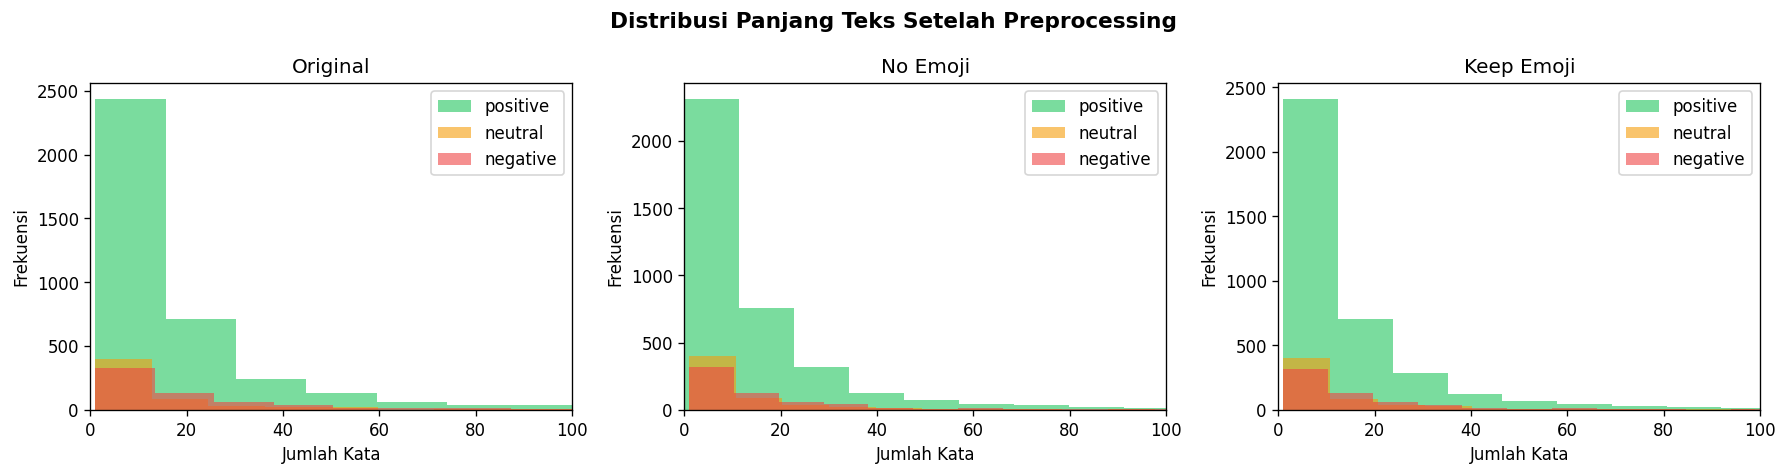

In [ ]:
# ============================================================
# CELL 5D — APPLY PREPROCESSING KE DATASET
# ============================================================
from tqdm import tqdm
tqdm.pandas()

print("Menerapkan preprocessing ke seluruh dataset...")
print(f"Total baris: {len(df_labeled)}")

# ── Terapkan dua versi ────────────────────────────────────
df_labeled['text_no_emoji'] = df_labeled['review_text'].progress_apply(
    lambda x: preprocess(x, emoji_mode='remove', use_stemming=False)
)
df_labeled['text_keep_emoji'] = df_labeled['review_text'].progress_apply(
    lambda x: preprocess(x, emoji_mode='keep', use_stemming=False)
)

print("\n✓ Preprocessing selesai")
display(df_labeled[['review_text', 'text_no_emoji', 'text_keep_emoji', 'sentiment']].head(5))

# ── Validasi kualitas hasil preprocessing ─────────────────
print("\n" + "="*60)
print("VALIDASI KUALITAS PREPROCESSING")
print("="*60)

# 1. Cek teks kosong setelah preprocessing
empty_no_emoji   = (df_labeled['text_no_emoji']   == '').sum()
empty_keep_emoji = (df_labeled['text_keep_emoji'] == '').sum()
print(f"\nTeks kosong setelah preprocessing:")
print(f"  text_no_emoji   : {empty_no_emoji} baris")
print(f"  text_keep_emoji : {empty_keep_emoji} baris")

# 2. Statistik panjang teks sebelum vs sesudah
df_labeled['len_original']  = df_labeled['review_text'].str.split().str.len()
df_labeled['len_no_emoji']  = df_labeled['text_no_emoji'].str.split().str.len()
df_labeled['len_keep_emoji']= df_labeled['text_keep_emoji'].str.split().str.len()

print(f"\nStatistik panjang teks (jumlah kata):")
print(f"{'Versi':<20} {'Mean':>8} {'Median':>8} {'Min':>6} {'Max':>6}")
print("-"*50)
for col, label in [('len_original','Original'), ('len_no_emoji','No Emoji'), ('len_keep_emoji','Keep Emoji')]:
    s = df_labeled[col]
    print(f"{label:<20} {s.mean():>8.1f} {s.median():>8.1f} {s.min():>6} {s.max():>6}")

# 3. Cek apakah ada teks terlalu pendek (< 2 kata) setelah preprocessing
too_short = df_labeled[df_labeled['len_no_emoji'] < 2]
print(f"\nReview dengan < 2 kata setelah preprocessing: {len(too_short)}")
if len(too_short) > 0:
    print("Contoh (perlu diputuskan: drop atau pertahankan):")
    display(too_short[['review_text', 'text_no_emoji', 'sentiment']].head(10))

# 4. Distribusi panjang teks setelah preprocessing (visualisasi)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribusi Panjang Teks Setelah Preprocessing', fontsize=13, fontweight='bold')

for ax, (col, label) in zip(axes, [
    ('len_original',  'Original'),
    ('len_no_emoji',  'No Emoji'),
    ('len_keep_emoji','Keep Emoji'),
]):
    for sentiment, color in [('positive','#22c55e'), ('neutral','#f59e0b'), ('negative','#ef4444')]:
        data = df_labeled[df_labeled['sentiment'] == sentiment][col]
        ax.hist(data, bins=30, alpha=0.6, label=sentiment, color=color)
    ax.set_title(label)
    ax.set_xlabel('Jumlah Kata')
    ax.set_ylabel('Frekuensi')
    ax.legend()
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Drop Empty Text & Save Decision

In [ ]:
# ============================================================
# CELL 5E — KEPUTUSAN FINAL & SIMPAN DATASET PREPROCESSING
# ============================================================

# ── Drop teks kosong / terlalu pendek ─────────────────────
# Threshold: minimal 2 kata setelah preprocessing
MIN_WORDS = 2

df_final = df_labeled[
    (df_labeled['text_no_emoji'].str.split().str.len() >= MIN_WORDS) &
    (df_labeled['text_keep_emoji'].str.split().str.len() >= MIN_WORDS)
].copy()

n_dropped = len(df_labeled) - len(df_final)
print(f"Baris di-drop (< {MIN_WORDS} kata): {n_dropped}")
print(f"Dataset final: {len(df_final)} baris")

# Pastikan distribusi sentimen tidak berubah signifikan
print("\nDistribusi sentimen setelah drop:")
print(df_final['sentiment'].value_counts(normalize=True).mul(100).round(2))

# ── Simpan 2 versi dataset preprocessing ─────────────────
# Versi 1: tanpa emoji (untuk eksperimen skenario A)
df_no_emoji = df_final[['text_no_emoji', 'sentiment']].rename(
    columns={'text_no_emoji': 'review_text'}
)
df_no_emoji.to_csv(base_path + 'df_preprocessed_no_emoji.csv', index=False)

# Versi 2: keep emoji (untuk eksperimen skenario B)
df_keep_emoji = df_final[['text_keep_emoji', 'sentiment']].rename(
    columns={'text_keep_emoji': 'review_text'}
)
df_keep_emoji.to_csv(base_path + 'df_preprocessed_keep_emoji.csv', index=False)

# Versi lengkap (untuk referensi dan analisis lanjutan)
cols_to_save = ['review_text', 'text_no_emoji', 'text_keep_emoji', 'sentiment']
df_final[cols_to_save].to_csv(base_path + 'df_preprocessed_full.csv', index=False)

print("\n✓ Dataset tersimpan:")
print(f"  → df_preprocessed_no_emoji.csv   ({len(df_no_emoji)} baris)")
print(f"  → df_preprocessed_keep_emoji.csv ({len(df_keep_emoji)} baris)")
print(f"  → df_preprocessed_full.csv       ({len(df_final)} baris)")

# ── Summary untuk laporan ─────────────────────────────────
print("\n" + "="*60)
print("RINGKASAN FASE 5 — PREPROCESSING")
print("="*60)
print(f"Dataset input (df_labeled)     : {len(df_labeled)} baris")
print(f"Baris di-drop (teks terlalu pendek) : {n_dropped} baris")
print(f"Dataset final untuk modeling   : {len(df_final)} baris")
print(f"\nDua versi teks yang dihasilkan:")
print(f"  [A] text_no_emoji   → df_preprocessed_no_emoji.csv")
print(f"  [B] text_keep_emoji → df_preprocessed_keep_emoji.csv")

Baris di-drop (< 2 kata): 130
Dataset final: 4783 baris

Distribusi sentimen setelah drop:
sentiment
positive    75.96
negative    12.44
neutral     11.60
Name: proportion, dtype: float64

✓ Dataset tersimpan:
  → df_preprocessed_no_emoji.csv   (4783 baris)
  → df_preprocessed_keep_emoji.csv (4783 baris)
  → df_preprocessed_full.csv       (4783 baris)

RINGKASAN FASE 5 — PREPROCESSING
Dataset input (df_labeled)     : 4913 baris
Baris di-drop (teks terlalu pendek) : 130 baris
Dataset final untuk modeling   : 4783 baris

Dua versi teks yang dihasilkan:
  [A] text_no_emoji   → df_preprocessed_no_emoji.csv
  [B] text_keep_emoji → df_preprocessed_keep_emoji.csv


#### Load Preprocessed Data

In [ ]:
# ============================================================
# LOAD DATASET HASIL PREPROCESSING (FASE 5E)
# Source: Google Drive
# ============================================================

base_path = '/content/drive/MyDrive/Data TA/'

# ── Load dataset no emoji ─────────────────────────────────
df_no_emoji = pd.read_csv(
    base_path + 'df_preprocessed_no_emoji.csv'
)

# ── Load dataset keep emoji ───────────────────────────────
df_keep_emoji = pd.read_csv(
    base_path + 'df_preprocessed_keep_emoji.csv'
)

# ── Load dataset full preprocessing ───────────────────────
df_final = pd.read_csv(
    base_path + 'df_preprocessed_full.csv'
)

# ============================================================
# VALIDASI HASIL LOAD
# ============================================================

print("="*60)
print("LOAD PREPROCESSING DATASET BERHASIL")
print("="*60)

print(f"\ndf_no_emoji   : {df_no_emoji.shape}")
print(f"df_keep_emoji : {df_keep_emoji.shape}")
print(f"df_final       : {df_final.shape}")

print("\nKolom dataset:")

print(f"\ndf_no_emoji:")
print(df_no_emoji.columns.tolist())

print(f"\ndf_keep_emoji:")
print(df_keep_emoji.columns.tolist())

print(f"\ndf_final:")
print(df_final.columns.tolist())

# ============================================================
# SAMPLE DATA
# ============================================================

print("\n" + "="*60)
print("SAMPLE DATA")
print("="*60)

print("\n[NO EMOJI]")
display(df_no_emoji.head(3))

print("\n[KEEP EMOJI]")
display(df_keep_emoji.head(3))

print("\n[FULL DATASET]")
display(df_final.head(3))

LOAD PREPROCESSING DATASET BERHASIL

df_no_emoji   : (4783, 2)
df_keep_emoji : (4783, 2)
df_final       : (4783, 4)

Kolom dataset:

df_no_emoji:
['review_text', 'sentiment']

df_keep_emoji:
['review_text', 'sentiment']

df_final:
['review_text', 'text_no_emoji', 'text_keep_emoji', 'sentiment']

SAMPLE DATA

[NO EMOJI]


,review_text,sentiment
0,ikannya nyamber terus,positive
1,kebun kopi pemandangan indah,positive
2,pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,neutral



[KEEP EMOJI]


,review_text,sentiment
0,ikannya nyamber terus,positive
1,kebun kopi pemandangan indah,positive
2,pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,neutral



[FULL DATASET]


,review_text,text_no_emoji,text_keep_emoji,sentiment
0,Ikannya nyamber terus,ikannya nyamber terus,ikannya nyamber terus,positive
1,Kebun kopi dengan pemandangan yang indah,kebun kopi pemandangan indah,kebun kopi pemandangan indah,positive
2,"Pengunjung tidak boleh membuang sampah sembarangan, sampah harus dibawa saat pengunjung keluar kawasan. Jika melanggar, pengunjung akan dikenakan denda oleh pihak pengelola.",pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,pengunjung boleh membuang sampah sembarangan sampah dibawa pengunjung keluar kawasan melanggar pengunjung dikenakan denda pihak pengelola,neutral


In [ ]:
import pandas as pd

base_path = '/content/drive/MyDrive/Data TA/'

df_final = pd.read_csv(
    base_path + 'df_preprocessed_full.csv'
)

NEGATIONS = [
    'tidak',
    'bukan',
    'jangan',
    'kurang',
    'ga',
    'gak'
]

TEXT_COL = 'text_no_emoji'

total_reviews = len(df_final)

print("="*60)
print("NEGATION ANALYSIS")
print("="*60)

for word in NEGATIONS:

    count = df_final[TEXT_COL].astype(str).str.contains(
        fr'\b{word}\b',
        case=False,
        regex=True,
        na=False
    ).sum()

    pct = count / total_reviews * 100

    print(
        f"{word:<10} : {count:>5} review ({pct:.2f}%)"
    )

NEGATION ANALYSIS
tidak      :   276 review (5.77%)
bukan      :    56 review (1.17%)
jangan     :   109 review (2.28%)
kurang     :   213 review (4.45%)
ga         :     7 review (0.15%)
gak        :     5 review (0.10%)


In [ ]:
negations = [
    'tidak',
    'bukan',
    'jangan',
    'kurang'
]

for word in negations:

    sample = df_final[
        df_final['text_no_emoji'].str.contains(
            fr'\b{word}\b',
            regex=True,
            case=False,
            na=False
        )
    ][['review_text', 'text_no_emoji']].head(5)

    print(f"\n===== {word.upper()} =====")
    display(sample)


===== TIDAK =====


,review_text,text_no_emoji
13,"Lokasinya nyaman, teduh, buat sante di pinggir Pante akses mudah karena tidak terlalu banyak pengunjung.",lokasinya nyaman teduh buat sante pinggir pante akses mudah tidak terlalu banyak pengunjung
18,"Pantai kecil ini berada di samping kiri jalan menuju pantai Ngudel. Lumayan bagus. Tidak ada tiket dan tidak ada yang jaga. Jadi cukup parkir dan turun sekitar 10 meter dari jalan desa langsung ketemu tkp,",pantai kecil berada samping kiri jalan menuju pantai ngudel lumayan bagus tiket tidak ada yang jaga jadi cukup parkir turun meter jalan desa langsung ketemu tkp
30,"Tempat bagus tapiiii....ini tdk diperuntukkan untk berwisata nggih,kl wisata atau menginap ke pantai sblhnya saja 🙏👍👍",tempat bagus tapii tidak diperuntukkan untk berwisata nggih kl wisata menginap pantai sblhnya
74,"Sepi, jd seperti private beach. Tapi gak bs main air, ombaknya kebetulan pas ganas. Perlu pengelolaan yg lebih agar bs menarik pengunjung.",sepi jd private beach tidak bs main air ombaknya kebetulan pas ganas perlu pengelolaan lebih bs menarik pengunjung
95,"kalo kesana harus siap fisik karena jalanannya sangat wowww. meskipun ada tangga tangganya tapi karena udah lama, tangganya berantakan banget dan ga beraturan. pake pakaian yang nyaman dan ga ribet buat hiking tipis tipis, pantainya cakep banget aslii no debatt. tapi pp naik turunnya itu capekkk bangettt",kalo kesana siap fisik jalanannya sangat woww meskipun tangga tangganya karena udah lama tangganya berantakan banget tidak beraturan pake pakaian nyaman tidak ribet buat hiking tipis tipis pantainya cakep banget aslii no debatt pp naik turunnya capekk bangett



===== BUKAN =====


,review_text,text_no_emoji
144,"punglinya tolong ditertibkan, sediakan juga tempat sampah dengan harga segitu, masih banyak sampah di sekitar apalagi di pasir pantai. pantai saya akui bagus sekali jika pengelolaannya di maintenance. dan, catatan penting; kalo nurut sama arah jalan gmaps ini bakal dituntun ke arah gunung belakang, gambar terakhir. berakhir tersesat dan harus puter balik (bukan jalan raya umumnya), mending kalo mau kesana arahkan ke maps watu ulo, dan belok ke gapura papuma sebelum watu ulo",punglinya ditertibkan sediakan tempat sampah harga segitu banyak sampah sekitar pasir pantai pantai akui bagus sekali pengelolaannya di maintenance catatan penting kalo nurut sama arah jalan gmaps bakal dituntun arah gunung belakang gambar terakhir berakhir tersesat harus puter balik bukan jalan raya umumnya mending kalo mau kesana arahkan maps watu ulo belok gapura papuma watu ulo
156,"hal pertama yg ingin saya coba adalah hot chocolate. karena temanya disini chocolate dan saya tertarik untuk mencobanya. namun pada saat saya datang, minuman chocolatenya katanya kosong. kemudian saya tanya milkshake strawberry juga kosong. pas pengen coba cemilan2 lainnya (contoh tahu walik) juga kosong. setelahnya yg jaga di kasir nawarin tea2an. lah kalo tau dr awal banyak yg kosong ngapain buka? tutup aja sekalian, ga niat buka banget. ngapain ditawarin menu yg bukan menu utamanya. tutup aja udah. kita mah jauh2 mau nyobain chocolatenya, bukan mau coba lemon tea, jasmine tea dll. klo mau teh mah saya ga kesana jauh2. akhirnya dg terpaksa pesen nih jus sirsak (capek jauh2 dateng, masa langsung balik?) yg bikin kaget adalah pas dateng tuh jus pake gelas plastik kek teh poci 🤪 kirain pake gelas yg proper. klo pake gelas plastik mah mending saya beli dipinggiran, ga ke caffe begini. udah nunggu pesenan setengah jam, ga worth it pula. bad experience ever! ga bakal dateng lagi. baca nih buat yg mau berkunjung kesini",pertama ingin coba hot chocolate temanya disini chocolate tertarik mencobanya pada datang minuman chocolatenya katanya kosong kemudian tanya milkshake strawberry kosong pas pengen coba cemilan2 lainnya contoh tahu walik kosong setelahnya jaga kasir nawarin tea2an lah kalo tau awal banyak kosong ngapain buka tutup aja sekalian niat buka banget ngapain ditawarin menu bukan menu utamanya tutup aja udah mah jauh2 mau nyobain chocolatenya bukan mau coba lemon tea jasmine tea klo mau teh mah saya kesana jauh2 akhirnya dg terpaksa pesen nih jus sirsak capek jauh2 dateng masa langsung balik bikin kaget pas dateng tuh jus pake gelas plastik kek teh poci kirain pake gelas proper klo pake gelas plastik mah mending saya beli dipinggiran ke caffe begini udah nunggu pesenan setengah jam worth it buruk experience ever tidak bakal dateng baca nih buat mau berkunjung kesini
184,"Udah lima kali mungkin ke pulau merah dan ngak bosen apalagi terakhir kesini sekalian liat sunset juga, padahal pas bukan weekend tapi tetep rame",udah lima kali mungkin pulau merah ngak bosen terakhir kesini sekalian liat sunset padahal pas bukan weekend tetep rame
250,"🌿 Pantai Alas Purwo: Ketika Laut Bertemu Hutan Purba\n\nTerletak di ujung timur Pulau Jawa, Pantai Alas Purwo adalah perwujudan keindahan alam liar yang nyaris tak tersentuh. Berada di dalam kawasan Taman Nasional Alas Purwo, pantai ini bukan sekadar destinasi wisata, melainkan bagian dari legenda dan misteri yang menyatu dengan kekayaan flora-fauna dan gelombang Samudra Hindia yang megah.\n\n🏝️ Pesona Alam yang Masih Perawan\n\nPantai Alas Purwo menyuguhkan hamparan pasir putih kecokelatan, ombak besar yang menggulung sempurna, dan latar hutan tropis yang lebat. Suasana di sini tenang, nyaris tak terdengar riuh kendaraan atau keramaian, hanya debur ombak dan desiran angin laut yang bersenandung.\n\nBeberapa pantai di dalam kawasan Alas Purwo yang paling terkenal antara lain:\n\nPantai Plengkung (G-Land): Surga para peselancar dunia.\n\nPantai Pancur: Pantai eksotis dengan mata air tawar yang mengalir ke la


===== JANGAN =====


,review_text,text_no_emoji
171,Tempatnya sebelum Tiket masuk Pulau Merah belok ke kiri. HTM 2 orang dewasa 1 anak kecil dan mobil kena Rp. 25.000. Tempatnya enak teduh banyak warung dan terdapat Mushola. Dengan pantai pasir putih dan view langsung pulau merah. Jika air surut banyak ikan dan gurita di sela-sela karang. Dibuat camping dengan keluarga juga cocok. Malam ada penerangan dari tempat wisata di titik-titik tertentu. Sangat nyaman toilet musholla juga di buka 24 jam dan jangan lupa beri sumbangan untuk listrik dan air musholla agar dapat mengalir terus.,tempatnya tiket masuk pulau merah belok kiri htm orang dewasa anak kecil mobil kena rp tempatnya enak teduh banyak warung terdapat mushola pantai pasir putih pemandangan langsung pulau merah air surut banyak ikan gurita sela sela karang dibuat camping keluarga cocok malam penerangan tempat wisata titik titik tertentu sangat nyaman toilet musholla di buka jam jangan lupa beri sumbangan listrik air musholla dapat mengalir terus
192,"Serius ini cakep banget. Gak kalah sama destinasi wisata lain. Cuma butuh perjuangan banget buat ke sini. Pertama mesti naik perahu. Ikuti arahan dari pemandu. Serius ke sini saat ombak tinggi. Tapi karena pemandunya sangat baik dalam mengarahkan. Alhamdulillah aman.\nPakai baju yang nyaman karena untuk dapat pemandangan terbaiknya, kalian harus naik tangga tinggi banget. Kebayar sih semuanya pas di atas. Trs jangan lupa turun ke pantainya. Walau gak bisa buat berenang, pemandangannya bagus buat foto-foto.",serius cakep banget kalah sama destinasi wisata cuma butuh perjuangan banget buat sini pertama mesti naik perahu ikuti arahan pemandu serius sini ombak tinggi pemandunya sangat baik mengarahkan alhamdulillah aman pakai baju nyaman karena untuk pemandangan terbaiknya kalian naik tangga tinggi banget kebayar sih semuanya pas atas trs jangan lupa turun pantainya tidak buat berenang pemandangannya bagus buat foto foto
202,"Pas sampai di Pantai Mustika nanti akan ada resto / kafe. Ada tulisan informasi Pulau Bedil. Jangan datang terlalu siang, semakin ramai",pas di pantai mustika akan resto kafe tulisan informasi pulau bedil jangan datang terlalu siang semakin ramai
250,"🌿 Pantai Alas Purwo: Ketika Laut Bertemu Hutan Purba\n\nTerletak di ujung timur Pulau Jawa, Pantai Alas Purwo adalah perwujudan keindahan alam liar yang nyaris tak tersentuh. Berada di dalam kawasan Taman Nasional Alas Purwo, pantai ini bukan sekadar destinasi wisata, melainkan bagian dari legenda dan misteri yang menyatu dengan kekayaan flora-fauna dan gelombang Samudra Hindia yang megah.\n\n🏝️ Pesona Alam yang Masih Perawan\n\nPantai Alas Purwo menyuguhkan hamparan pasir putih kecokelatan, ombak besar yang menggulung sempurna, dan latar hutan tropis yang lebat. Suasana di sini tenang, nyaris tak terdengar riuh kendaraan atau keramaian, hanya debur ombak dan desiran angin laut yang bersenandung.\n\nBeberapa pantai di dalam kawasan Alas Purwo yang paling terkenal antara lain:\n\nPantai Plengkung (G-Land): Surga para peselancar dunia.\n\nPantai Pancur: Pantai eksotis dengan mata air tawar yang mengalir ke laut.\n\nPantai Trianggulasi: Cocok untuk piknik alam dan foto lanskap.\n\nPantai Ngagelan: Tempat konservasi penyu langka.\n\n🌳 Hutan dan Misteri yang Menyelimuti\n\nAlas Purwo dikenal luas sebagai hutan tertua di Pulau Jawa, dan kerap dikaitkan dengan aura mistis serta spiritualitas. Masyarakat lokal percaya bahwa kawasan ini adalah tempat “bersemayamnya” para leluhur dan makhluk halus, yang membuat suasananya terasa sakral namun menenangkan.\n\nBagi pecinta satwa liar, hutan ini adalah rumah bagi banteng jawa, kijang, macan tutul, burung merak, dan banyak spesies langka lainnya. Terdapat pula Savana Sadengan, tempat wisatawan bisa menyaksikan hewan liar berkeliaran bebas seperti di Afrika kecil.\n\n🌅 Aktivitas yang Bisa Dilakukan\n\nSurfing di G-Land: Dianggap sebagai salah satu ombak terbaik di dunia untuk peselancar profesional.\n\nCamping dan trekking: Nikmati malam di teng


===== KURANG =====


,review_text,text_no_emoji
116,View bagus fasilitas pendukung kurang\njalan ke pantai hanya bisa di lalui roda 2,pemandangan bagus fasilitas pendukung kurang jalan pantai bisa lalui roda
123,Bagus Buangett.. Saya Suka tempatnya..\nSejukk dan masih terawat..\nTempatnya agak sepi kurang pengunjung,bagus buangett suka tempatnya sejukk masih terawat tempatnya sepi kurang pengunjung
146,Wisata biasa saja bayar dobel menejemen kurang bagus cukup sekali saja kesini,wisata biasa bayar dobel menejemen kurang bagus cukup sekali kesini
162,"Pantai nya bagus sayang sekali akses jalan kurang baik & ekstreme, harus nya bisa dikelola jadi objek wisata yg potensial 👍",pantai nya bagus sayang sekali akses jalan kurang baik ekstreme nya dikelola jadi objek wisata potensial
198,"Pernah buat acara disini bersama teman-teman gereja. Ada seperti pendopo yang cukup besar, karena waktu itu mendadak mau pinjamnya jadi untuk listrik belum tersedia tapi tempat bersih. Disini memang sering digunakan kegiatan keagamaan karena ada beberapa tempat yang biasa buat gathering dan beberapa tempat ibadah.\nBanyak pendopo kecilnya jadi bisa piknik di pendopo sama keluarga atau teman.\nAkses jalannya juga mudah. Terakhir kesana sepi banget pantainya, dan kurang terawat lagi.\nSemoga semakin membaik dan bisa jadi penghasilan warga sekitar.",pernah buat acara disini bersama teman teman gereja seperti pendopo cukup besar waktu mendadak mau pinjamnya jadi listrik tersedia tempat bersih disini memang sering digunakan kegiatan keagamaan ada beberapa tempat biasa buat gathering beberapa tempat ibadah banyak pendopo kecilnya jadi piknik pendopo sama keluarga teman akses jalannya mudah terakhir kesana sepi banget pantainya kurang terawat semoga semakin membaik bisa jadi penghasilan warga


### Stratified Split 80/10/10

In [ ]:
# ============================================================
# CELL 5F — STRATIFIED SPLIT 80 / 10 / 10
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# ── Label encoding ────────────────────────────────────────
le = LabelEncoder()
y_all = le.fit_transform(df_final['sentiment'])

print("Label mapping:")
for label, encoded in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {label} → {encoded}")

# ── Split menggunakan text_no_emoji sebagai base index ────
# Kedua versi (no_emoji & keep_emoji) menggunakan INDEX yang SAMA
# Ini krusial untuk memastikan eksperimen emoji benar-benar controlled
X_idx = df_final.index.values  # gunakan index sebagai identifier

X_train_idx, X_temp_idx, y_train, y_temp = train_test_split(
    X_idx, y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

X_val_idx, X_test_idx, y_val, y_test = train_test_split(
    X_temp_idx, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(f"\nUkuran split:")
print(f"  Train : {len(X_train_idx)} ({len(X_train_idx)/len(df_final)*100:.1f}%)")
print(f"  Val   : {len(X_val_idx)}  ({len(X_val_idx)/len(df_final)*100:.1f}%)")
print(f"  Test  : {len(X_test_idx)}  ({len(X_test_idx)/len(df_final)*100:.1f}%)")

# ── Verifikasi distribusi tiap split ──────────────────────
print("\nVerifikasi distribusi sentimen per split:")
for split_name, y_split in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(y_split, return_counts=True)
    print(f"\n  {split_name}:")
    for label_enc, count in zip(unique, counts):
        label_name = le.inverse_transform([label_enc])[0]
        pct = count / len(y_split) * 100
        print(f"    {label_name:<12}: {count:>4} ({pct:.1f}%)")

# ── Buat fungsi get_split() untuk digunakan di fase modeling ──
def get_split(df_source: pd.DataFrame, text_col: str):
    """
    Ambil split train/val/test dari dataframe dengan kolom text tertentu.
    Gunakan fungsi ini di fase modeling untuk konsistensi.

    Args:
        df_source: dataframe yang sudah preprocessed (df_final)
        text_col : nama kolom teks ('text_no_emoji' atau 'text_keep_emoji')

    Returns:
        (X_train, X_val, X_test, y_train, y_val, y_test)
    """
    X_train = df_source.loc[X_train_idx, text_col].values
    X_val   = df_source.loc[X_val_idx,   text_col].values
    X_test  = df_source.loc[X_test_idx,  text_col].values
    return X_train, X_val, X_test, y_train, y_val, y_test

# ── Test fungsi ───────────────────────────────────────────
X_tr, X_v, X_te, y_tr, y_v, y_te = get_split(df_final, 'text_no_emoji')
print(f"\n✓ get_split() berfungsi:")
print(f"  Contoh teks train[0]: {X_tr[0][:80]}")
print(f"  Label train[0]: {le.inverse_transform([y_tr[0]])[0]}")

# ── Simpan index split untuk reproducibility ──────────────
# np.save(base_path + 'split_train_idx.npy', X_train_idx)
# np.save(base_path + 'split_val_idx.npy',   X_val_idx)
# np.save(base_path + 'split_test_idx.npy',  X_test_idx)

# print("\n✓ Index split disimpan untuk reproducibility:")
# print("  → split_train_idx.npy")
# print("  → split_val_idx.npy")
# print("  → split_test_idx.npy")

Label mapping:
  negative → 0
  neutral → 1
  positive → 2

Ukuran split:
  Train : 3826 (80.0%)
  Val   : 478  (10.0%)
  Test  : 479  (10.0%)

Verifikasi distribusi sentimen per split:

  Train:
    negative    :  476 (12.4%)
    neutral     :  444 (11.6%)
    positive    : 2906 (76.0%)

  Val:
    negative    :   59 (12.3%)
    neutral     :   56 (11.7%)
    positive    :  363 (75.9%)

  Test:
    negative    :   60 (12.5%)
    neutral     :   55 (11.5%)
    positive    :  364 (76.0%)

✓ get_split() berfungsi:
  Contoh teks train[0]: recommend sekali kirang wow lihat foto mah ternyata jauh expektasi jalan tnah li
  Label train[0]: negative


### Imbalance Analysis & Handling Strategy

CLASS WEIGHT ANALYSIS

Distribusi training set:
  negative    :  476 sampel | weight = 2.6793
  neutral     :  444 sampel | weight = 2.8724
  positive    : 2906 sampel | weight = 0.4389

Class weight dict (untuk sklearn LR):
  {np.int64(0): np.float64(2.679271708683473), np.int64(1): np.float64(2.8723723723723724), np.int64(2): np.float64(0.4388621243404451)}

Class weight tensor (untuk PyTorch CrossEntropyLoss):
  tensor([2.6793, 2.8724, 0.4389])


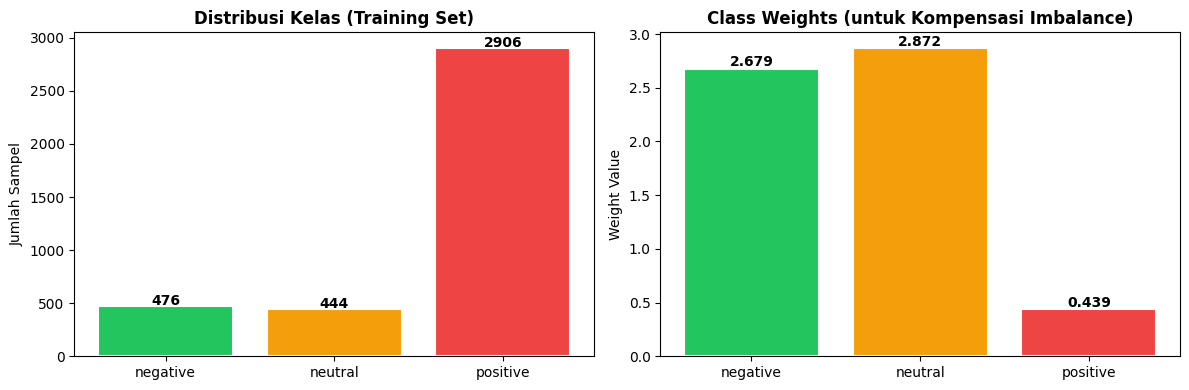


RINGKASAN FASE 5 — SIAP UNTUK FASE 6 (MODELING)
Variabel yang tersedia untuk fase berikutnya:
  df_final              → DataFrame lengkap
  get_split(df, col)    → Fungsi split konsisten
  le                    → LabelEncoder (fitted)
  class_weight_dict     → Untuk sklearn (LR)
  class_weight_tensor   → Untuk PyTorch (BERT)
  X_train/val/test_idx  → Index split (numpy array)


In [ ]:
# ============================================================
# CELL 5G — ANALISIS IMBALANCE & STRATEGI PENANGANAN
# ============================================================
from sklearn.utils.class_weight import compute_class_weight

# ── Hitung class weights ──────────────────────────────────
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Konversi ke dict untuk sklearn
class_weight_dict = dict(zip(np.unique(y_train), class_weights_array))

# Konversi ke tensor untuk PyTorch (BERT)
import torch
class_weight_tensor = torch.tensor(class_weights_array, dtype=torch.float)

print("="*60)
print("CLASS WEIGHT ANALYSIS")
print("="*60)
print(f"\nDistribusi training set:")
for enc, name in zip(range(len(le.classes_)), le.classes_):
    count = (y_train == enc).sum()
    weight = class_weight_dict[enc]
    print(f"  {name:<12}: {count:>4} sampel | weight = {weight:.4f}")

print(f"\nClass weight dict (untuk sklearn LR):")
print(f"  {class_weight_dict}")

print(f"\nClass weight tensor (untuk PyTorch CrossEntropyLoss):")
print(f"  {class_weight_tensor}")

# ── Visualisasi imbalance ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Distribusi asli
labels = le.classes_
counts = [( y_train == le.transform([l])[0]).sum() for l in labels]
colors = ['#22c55e', '#f59e0b', '#ef4444']
axes[0].bar(labels, counts, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Distribusi Kelas (Training Set)', fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
for i, (label, count) in enumerate(zip(labels, counts)):
    axes[0].text(i, count + 10, str(count), ha='center', fontweight='bold')

# Plot 2: Class weights
weights = [class_weight_dict[le.transform([l])[0]] for l in labels]
axes[1].bar(labels, weights, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('Class Weights (untuk Kompensasi Imbalance)', fontweight='bold')
axes[1].set_ylabel('Weight Value')
for i, (label, w) in enumerate(zip(labels, weights)):
    axes[1].text(i, w + 0.02, f'{w:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("RINGKASAN FASE 5 — SIAP UNTUK FASE 6 (MODELING)")
print("="*60)
print("Variabel yang tersedia untuk fase berikutnya:")
print("  df_final              → DataFrame lengkap")
print("  get_split(df, col)    → Fungsi split konsisten")
print("  le                    → LabelEncoder (fitted)")
print("  class_weight_dict     → Untuk sklearn (LR)")
print("  class_weight_tensor   → Untuk PyTorch (BERT)")
print("  X_train/val/test_idx  → Index split (numpy array)")

## Baseline Models

### Setup & Evaluation Function

In [ ]:

warnings.filterwarnings('ignore')

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score
)

# Pastikan GPU tersedia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ── Wadah hasil semua run ─────────────────────────────────
all_results = []   # list of dict, diisi tiap run selesai

# ── Fungsi evaluasi utama ─────────────────────────────────
def evaluate_and_log(y_true, y_pred, run_name, emoji_mode,
                     model_type, freeze_mode='—', dropout='—'):
    """
    Hitung semua metrik, tampilkan confusion matrix,
    dan simpan hasil ke all_results untuk tabel akhir.
    """
    acc     = accuracy_score(y_true, y_pred)
    mac_f1  = f1_score(y_true, y_pred, average='macro',    zero_division=0)
    mac_p   = precision_score(y_true, y_pred, average='macro', zero_division=0)
    mac_r   = recall_score(y_true, y_pred, average='macro',    zero_division=0)

    # F1 per kelas
    f1_per_class = f1_score(y_true, y_pred, average=None, zero_division=0)

    print(f"\n{'='*65}")
    print(f"  HASIL: {run_name}")
    print(f"{'='*65}")
    print(classification_report(
        y_true, y_pred,
        target_names=le.classes_,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=le.classes_,
                yticklabels=le.classes_,
                cmap='Blues', linewidths=0.5)
    plt.title(f'Confusion Matrix\n{run_name}', fontweight='bold')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

    # Simpan ke log
    result = {
        'run'        : run_name,
        'model_type' : model_type,
        'emoji_mode' : emoji_mode,
        'freeze'     : freeze_mode,
        'dropout'    : dropout,
        'accuracy'   : round(acc,    4),
        'macro_f1'   : round(mac_f1, 4),
        'macro_p'    : round(mac_p,  4),
        'macro_r'    : round(mac_r,  4),
        'f1_negative': round(f1_per_class[le.transform(['negative'])[0]], 4),
        'f1_neutral' : round(f1_per_class[le.transform(['neutral'])[0]],  4),
        'f1_positive': round(f1_per_class[le.transform(['positive'])[0]], 4),
    }
    all_results.append(result)
    print(f"  ✓ Tersimpan ke all_results (total: {len(all_results)} run)\n")
    return result

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


### Baseline 1: TF-IDF + LogReg

╔══════════════════════════════════════════════════════╗
║         BASELINE 1: TF-IDF + LOGISTIC REGRESSION    ║
╚══════════════════════════════════════════════════════╝

───────────────────────────────────────────────────────
  Run 1: TF-IDF + LR [No Emoji]
───────────────────────────────────────────────────────
  Training pada 3826 sampel...
  Val Macro F1: 0.6505

  HASIL: TF-IDF + LR [No Emoji]
              precision    recall  f1-score   support

    negative       0.60      0.78      0.68        60
     neutral       0.48      0.65      0.55        55
    positive       0.95      0.85      0.90       364

    accuracy                           0.82       479
   macro avg       0.68      0.76      0.71       479
weighted avg       0.86      0.82      0.83       479



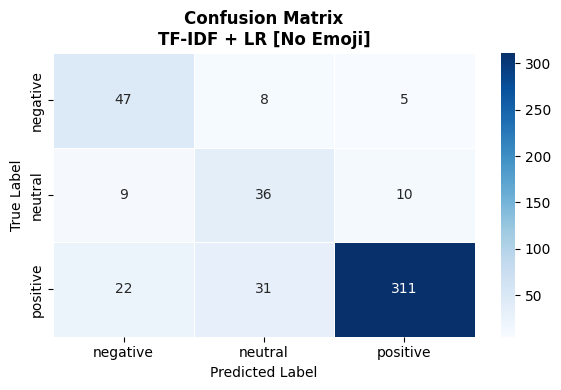

  ✓ Tersimpan ke all_results (total: 1 run)

  ✓ Model disimpan: tfidf_lr_no_emoji.pkl

  Top-10 fitur per kelas (No Emoji):
    negative: kurang, kotor, tidak, terawat, mahal, terbengkalai, buruk, ada, jalannya, jelek
    neutral: curug, pernah, sejarah, hutan, aja, mancing, tersedia, sendiri, lumayan bagus, kegiatan
    positive: bagus, indah, bersih, cocok, mantap, asri, sangat, pemandangan, sejuk, nyaman

───────────────────────────────────────────────────────
  Run 2: TF-IDF + LR [Keep Emoji]
───────────────────────────────────────────────────────
  Training pada 3826 sampel...
  Val Macro F1: 0.6511

  HASIL: TF-IDF + LR [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.60      0.80      0.69        60
     neutral       0.49      0.65      0.56        55
    positive       0.96      0.85      0.90       364

    accuracy                           0.82       479
   macro avg       0.68      0.77      0.72       479
weighted avg       0.86   

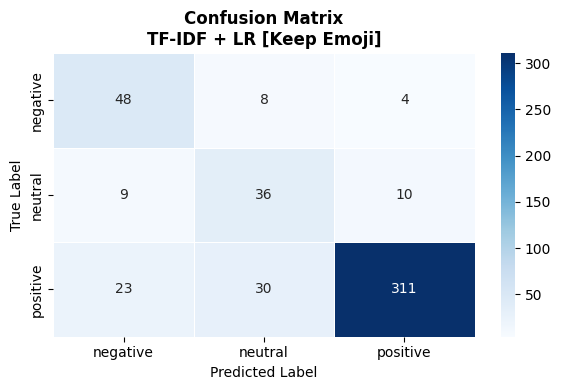

  ✓ Tersimpan ke all_results (total: 2 run)

  ✓ Model disimpan: tfidf_lr_keep_emoji.pkl

  Top-10 fitur per kelas (Keep Emoji):
    negative: kurang, kotor, tidak, terawat, mahal, terbengkalai, buruk, jalannya, ada, jelek
    neutral: curug, pernah, sejarah, aja, hutan, mancing, tersedia, sendiri, lumayan bagus, acara
    positive: bagus, indah, bersih, cocok, mantap, asri, sangat, pemandangan, sejuk, nyaman


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

print("╔══════════════════════════════════════════════════════╗")
print("║         BASELINE 1: TF-IDF + LOGISTIC REGRESSION    ║")
print("╚══════════════════════════════════════════════════════╝")

# Konfigurasi pipeline sklearn
TFIDF_CONFIG = {
    'max_features' : 15000,
    'ngram_range'  : (1, 2),
    'sublinear_tf' : True,       # log(1+tf) agar tidak didominasi kata sangat sering
    'min_df'       : 2,          # abaikan kata yang hanya muncul 1x (noise)
    'analyzer'     : 'word',
    'strip_accents' : 'unicode',
}

LR_CONFIG = {
    'C'            : 1.0,        # regularisasi default (bisa di-tune nanti)
    'max_iter'     : 1000,
    'class_weight' : 'balanced', # kompensasi imbalance
    'random_state' : 42,
    'solver'       : 'lbfgs',
    'multi_class'  : 'multinomial',
}

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 1'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 2'),
]:
    print(f"\n{'─'*55}")
    print(f"  {run_num}: TF-IDF + LR [{emoji_mode}]")
    print(f"{'─'*55}")

    # Ambil split konsisten via get_split()
    X_train, X_val, X_test, y_tr, y_v, y_te = get_split(df_final, text_col)

    # Build pipeline
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_CONFIG)),
        ('clf',   LogisticRegression(**LR_CONFIG)),
    ])

    # Training
    print(f"  Training pada {len(X_train)} sampel...")
    pipe.fit(X_train, y_tr)

    # Validasi (untuk monitoring)
    y_val_pred = pipe.predict(X_val)
    val_f1 = f1_score(y_v, y_val_pred, average='macro', zero_division=0)
    print(f"  Val Macro F1: {val_f1:.4f}")

    # Evaluasi pada test set
    y_test_pred = pipe.predict(X_test)

    evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_test_pred,
        run_name    = f"TF-IDF + LR [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'TF-IDF + LR',
        freeze_mode = '—',
        dropout     = '—',
    )

    # Simpan model
    # import joblib
    # fname = f"tfidf_lr_{'no_emoji' if emoji_mode == 'No Emoji' else 'keep_emoji'}.pkl"
    # joblib.dump(pipe, base_path + fname)
    # print(f"  ✓ Model disimpan: {fname}")

    # # Analisis feature importance (top TF-IDF per kelas)
    # print(f"\n  Top-10 fitur per kelas ({emoji_mode}):")
    # tfidf_vectorizer = pipe.named_steps['tfidf']
    # lr_model         = pipe.named_steps['clf']
    # feature_names    = np.array(tfidf_vectorizer.get_feature_names_out())

    # for i, class_name in enumerate(le.classes_):
    #     top_idx = np.argsort(lr_model.coef_[i])[-10:][::-1]
    #     top_words = feature_names[top_idx]
    #     print(f"    {class_name}: {', '.join(top_words)}")

### Tokenizer & Sentiment Dataset

In [ ]:

from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

MODEL_NAME = "indolem/indobertweet-base-uncased"
MAX_LEN    = 128
BATCH_SIZE = 32

# ── Load tokenizer ─────────────────────────────────────────
print(f"Loading tokenizer: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"✓ Tokenizer loaded | Vocab size: {tokenizer.vocab_size}")

# Test tokenisasi
test_text = "tempatnya keren banget pemandangan bagus"
tokens = tokenizer(test_text, return_tensors='pt')
print(f"\nContoh tokenisasi:")
print(f"  Input : '{test_text}'")
print(f"  Tokens: {tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])}")
print(f"  Length: {tokens['input_ids'].shape[1]} token")

# ── Dataset class untuk sentimen ──────────────────────────
class SentimentDataset(Dataset):
    """
    PyTorch Dataset untuk klasifikasi sentimen single-label.
    Berbeda dari kode ABSA lama yang menggunakan [SEP] trick,
    class ini hanya menerima review_text tunggal sebagai input
    karena task kita adalah pure sentiment classification
    tanpa konteks aspek.
    """
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text  = str(self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            text,
            padding         = 'max_length',
            truncation      = True,
            max_length      = self.max_len,
            return_tensors  = 'pt',
        )
        return {
            'input_ids'      : encoding['input_ids'].squeeze(0),       # (max_len,)
            'attention_mask' : encoding['attention_mask'].squeeze(0),  # (max_len,)
            'labels'         : torch.tensor(label, dtype=torch.long),
        }

def make_dataloaders(text_col: str, batch_size: int = BATCH_SIZE):
    """
    Buat train/val/test DataLoader dari kolom teks tertentu.
    Gunakan fungsi ini untuk setiap run BERT agar konsisten.

    Args:
        text_col   : 'text_no_emoji' atau 'text_keep_emoji'
        batch_size : default 32

    Returns:
        (train_loader, val_loader, test_loader)
    """
    X_train, X_val, X_test, y_tr, y_v, y_te = get_split(df_final, text_col)

    train_ds = SentimentDataset(X_train, y_tr, tokenizer)
    val_ds   = SentimentDataset(X_val,   y_v,  tokenizer)
    test_ds  = SentimentDataset(X_test,  y_te, tokenizer)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size*2, shuffle=False,
                              num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size*2, shuffle=False,
                              num_workers=2, pin_memory=True)

    print(f"DataLoader [{text_col}]:")
    print(f"  Train: {len(train_ds)} sampel | {len(train_loader)} batch")
    print(f"  Val  : {len(val_ds)} sampel | {len(val_loader)} batch")
    print(f"  Test : {len(test_ds)} sampel | {len(test_loader)} batch")

    return train_loader, val_loader, test_loader, y_te

# Test
train_loader, val_loader, test_loader, _ = make_dataloaders('text_no_emoji')
batch = next(iter(train_loader))
print(f"\nContoh batch:")
print(f"  input_ids shape     : {batch['input_ids'].shape}")
print(f"  attention_mask shape: {batch['attention_mask'].shape}")
print(f"  labels shape        : {batch['labels'].shape}")

Loading tokenizer: indolem/indobertweet-base-uncased


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

✓ Tokenizer loaded | Vocab size: 31923

Contoh tokenisasi:
  Input : 'tempatnya keren banget pemandangan bagus'
  Tokens: ['[CLS]', 'tempatnya', 'keren', 'banget', 'pemandangan', 'bagus', '[SEP]']
  Length: 7 token
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

Contoh batch:
  input_ids shape     : torch.Size([32, 128])
  attention_mask shape: torch.Size([32, 128])
  labels shape        : torch.Size([32])


### Ttraining Loop & Inference Function

In [ ]:
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
import time, copy

NUM_LABELS    = len(le.classes_)   # 3
NUM_EPOCHS    = 5
LR            = 2e-5
WARMUP_RATIO  = 0.1
WEIGHT_DECAY  = 0.01
PATIENCE      = 2                  # early stopping

def build_model(freeze_mode='none', dropout_rate=None):
    """
    Load IndoBERTweet dan konfigurasikan sesuai skenario eksperimen.

    Args:
        freeze_mode  : 'none'  → full fine-tuning
                       'all'   → freeze semua layer BERT (baseline)
                       'first6'→ freeze 6 layer pertama
        dropout_rate : None → gunakan default dari pretrained config
                       float → override classifier dropout

    Returns:
        model siap training (sudah di device)
    """
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels          = NUM_LABELS,
        ignore_mismatched_sizes = True,
    )

    # Override dropout jika diminta
    if dropout_rate is not None:
        model.classifier.dropout = torch.nn.Dropout(dropout_rate)
        print(f"  Dropout classifier diset ke: {dropout_rate}")

    # ── Konfigurasi freeze ─────────────────────────────────
    if freeze_mode == 'all':
        # Freeze SEMUA parameter BERT, hanya classifier yang trainable
        # Justifikasi: mengukur kualitas representasi pretrained tanpa
        # modifikasi apapun (probing setup)
        for name, param in model.named_parameters():
            if 'classifier' not in name:
                param.requires_grad = False
        print("  Freeze mode: ALL BERT layers frozen (hanya classifier trainable)")

    elif freeze_mode == 'first6':
        # Freeze 6 layer encoder pertama dari 12 layer total
        # Justifikasi: layer-layer awal BERT encode fitur linguistik umum
        # (sintaks, morfologi) yang sudah optimal dari pretraining,
        # sementara layer atas encode fitur task-specific yang perlu diadaptasi
        # (Jawahar et al., 2019 — What Does BERT Learn About the Structure of Language?)
        for name, param in model.named_parameters():
            # Freeze embedding + layer 0–5
            if 'embeddings' in name:
                param.requires_grad = False
            elif 'encoder.layer.' in name:
                layer_num = int(name.split('encoder.layer.')[1].split('.')[0])
                if layer_num < 6:
                    param.requires_grad = False
        print("  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)")

    else:  # 'none'
        print("  Freeze mode: FULL fine-tuning (semua layer trainable)")

    # Hitung parameter trainable
    trainable   = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total       = sum(p.numel() for p in model.parameters())
    print(f"  Trainable params: {trainable:,} / {total:,} ({trainable/total*100:.1f}%)")

    return model.to(device)


def train_bert(model, train_loader, val_loader,
               run_name, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    """
    Training loop dengan:
    - Weighted CrossEntropyLoss (imbalance handling)
    - AdamW optimizer dengan weight decay
    - Linear warmup + linear decay scheduler
    - Early stopping berdasarkan val loss
    - Simpan best model checkpoint

    Returns:
        best_model : model dengan val loss terbaik
        history    : dict berisi train_loss, val_loss per epoch
    """
    # Loss dengan class weight
    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weight_tensor.to(device)
    )

    # Optimizer — hanya parameter yang requires_grad
    optimizer = AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr           = LR,
        weight_decay = WEIGHT_DECAY,
        eps          = 1e-8,
    )

    # Scheduler: linear warmup kemudian linear decay
    total_steps  = len(train_loader) * num_epochs
    warmup_steps = int(total_steps * WARMUP_RATIO)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps   = warmup_steps,
        num_training_steps = total_steps,
    )

    history       = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_val_loss = float('inf')
    best_model    = None
    no_improve    = 0

    for epoch in range(num_epochs):
        t0 = time.time()

        # ── TRAINING ──────────────────────────────────────
        model.train()
        total_train_loss = 0

        for batch in train_loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss    = criterion(outputs.logits, labels)

            loss.backward()
            # Gradient clipping: mencegah exploding gradient yang umum
            # terjadi pada fine-tuning transformer dengan lr tinggi
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            scheduler.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)

        # ── VALIDASI ──────────────────────────────────────
        model.eval()
        total_val_loss = 0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for batch in val_loader:
                input_ids      = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels         = batch['labels'].to(device)

                outputs  = model(input_ids=input_ids, attention_mask=attention_mask)
                loss     = criterion(outputs.logits, labels)
                preds    = torch.argmax(outputs.logits, dim=1)

                total_val_loss += loss.item()
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        avg_val_loss = total_val_loss / len(val_loader)
        val_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
        elapsed = time.time() - t0

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_f1'].append(val_f1)

        print(f"  Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | "
              f"Val F1: {val_f1:.4f} | "
              f"Time: {elapsed:.1f}s")

        # ── Early stopping & best model checkpoint ────────
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_model    = copy.deepcopy(model)
            no_improve    = 0
            print(f"    ✓ Val loss membaik → simpan checkpoint")
        else:
            no_improve += 1
            print(f"    ✗ Tidak ada perbaikan ({no_improve}/{patience})")
            if no_improve >= patience:
                print(f"  ⚡ Early stopping di epoch {epoch+1}")
                break

    return best_model, history


def predict_bert(model, test_loader):
    """
    Inferensi pada test set, return numpy array prediksi.
    """
    model.eval()
    all_preds = []
    with torch.no_grad():
        for batch in test_loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds   = torch.argmax(outputs.logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
    return np.array(all_preds)


def plot_training_history(history, run_name):
    """Visualisasi loss dan F1 selama training."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f'Training History — {run_name}', fontweight='bold')

    epochs = range(1, len(history['train_loss']) + 1)

    axes[0].plot(epochs, history['train_loss'], 'b-o', label='Train Loss')
    axes[0].plot(epochs, history['val_loss'],   'r-o', label='Val Loss')
    axes[0].set_title('Loss per Epoch')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, history['val_f1'], 'g-o', label='Val Macro F1')
    axes[1].set_title('Validation Macro F1 per Epoch')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Macro F1')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

print("✓ Semua fungsi BERT siap digunakan")
print("  → build_model(), train_bert(), predict_bert(), plot_training_history()")

✓ Semua fungsi BERT siap digunakan
  → build_model(), train_bert(), predict_bert(), plot_training_history()


### Baseline 2: Frozen IndoBERTWeet


───────────────────────────────────────────────────────
  Run 3: Frozen IndoBERTweet [No Emoji]
───────────────────────────────────────────────────────


pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: ALL BERT layers frozen (hanya classifier trainable)
  Trainable params: 2,307 / 110,560,515 (0.0%)
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training...
  Epoch 1/5 | Train Loss: 1.1131 | Val Loss: 1.1110 | Val F1: 0.3292 | Time: 32.5s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 1.1044 | Val Loss: 1.0959 | Val F1: 0.3485 | Time: 28.9s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 1.0844 | Val Loss: 1.0857 | Val F1: 0.3726 | Time: 30.2s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 4/5 | Train Loss: 1.0896 | Val Loss: 1.0800 | Val F1: 0.3687 | Time: 28.8s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 5/5 | Train Loss: 1.0837 | Val Loss: 1.0781 | Val F1: 0.3764 | Time: 28.9s
    ✓ Val loss membaik → simpan checkpoint


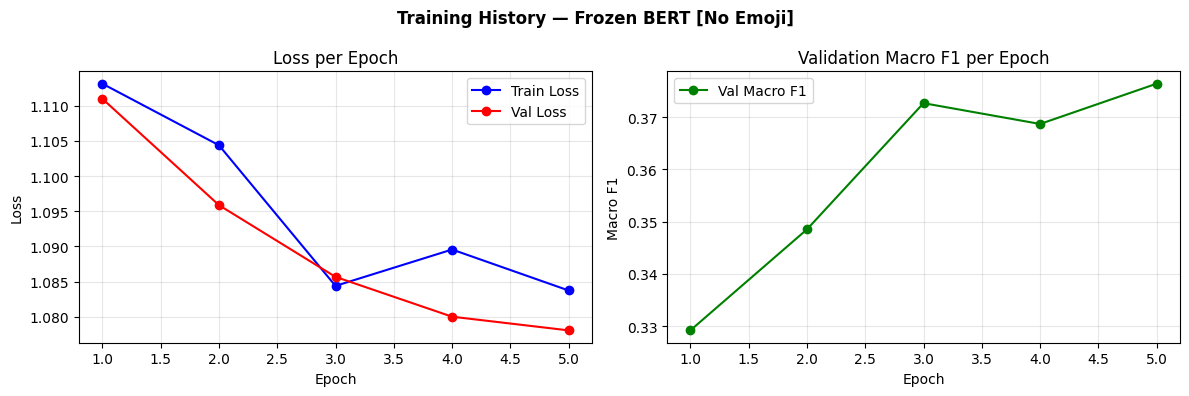


  HASIL: Frozen IndoBERTweet [No Emoji]
              precision    recall  f1-score   support

    negative       0.10      0.22      0.14        60
     neutral       0.26      0.25      0.26        55
    positive       0.80      0.66      0.72       364

    accuracy                           0.56       479
   macro avg       0.39      0.38      0.37       479
weighted avg       0.65      0.56      0.59       479



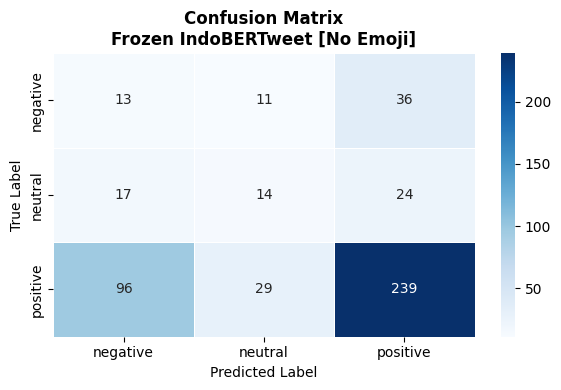

  ✓ Tersimpan ke all_results (total: 3 run)

  ✓ GPU cache cleared

───────────────────────────────────────────────────────
  Run 4: Frozen IndoBERTweet [Keep Emoji]
───────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: ALL BERT layers frozen (hanya classifier trainable)
  Trainable params: 2,307 / 110,560,515 (0.0%)
DataLoader [text_keep_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training...
  Epoch 1/5 | Train Loss: 1.1013 | Val Loss: 1.0920 | Val F1: 0.2945 | Time: 29.4s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 1.0861 | Val Loss: 1.0778 | Val F1: 0.3308 | Time: 28.8s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 1.0759 | Val Loss: 1.0685 | Val F1: 0.3635 | Time: 28.8s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 4/5 | Train Loss: 1.0699 | Val Loss: 1.0630 | Val F1: 0.3807 | Time: 29.0s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 5/5 | Train Loss: 1.0681 | Val Loss: 1.0612 | Val F1: 0.3888 | Time: 28.8s
    ✓ Val loss membaik → simpan checkpoint


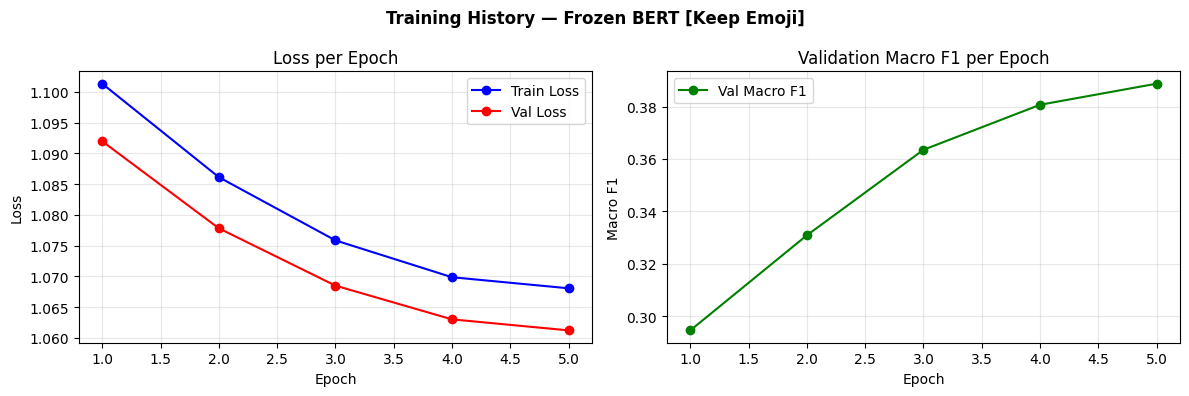


  HASIL: Frozen IndoBERTweet [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.18      0.53      0.27        60
     neutral       0.22      0.24      0.23        55
    positive       0.82      0.55      0.65       364

    accuracy                           0.51       479
   macro avg       0.41      0.44      0.38       479
weighted avg       0.67      0.51      0.56       479



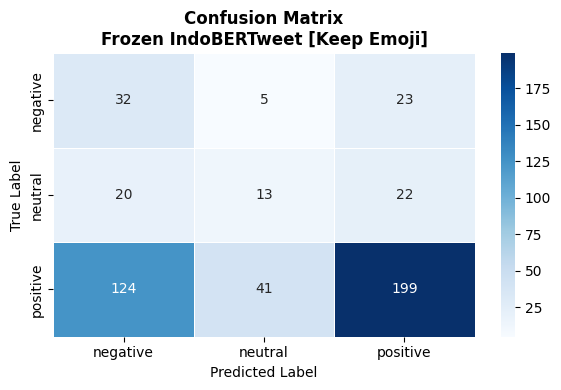

  ✓ Tersimpan ke all_results (total: 4 run)

  ✓ GPU cache cleared


In [ ]:

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 3'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 4'),
]:
    print(f"\n{'─'*55}")
    print(f"  {run_num}: Frozen IndoBERTweet [{emoji_mode}]")
    print(f"{'─'*55}")

    # Build model dengan semua layer di-freeze
    model = build_model(freeze_mode='all', dropout_rate=None)

    # Buat dataloader
    train_loader, val_loader, test_loader, y_te = make_dataloaders(text_col)

    # Training (hanya classifier head yang berubah)
    print(f"\n  Mulai training...")
    best_model, history = train_bert(
        model        = model,
        train_loader = train_loader,
        val_loader   = val_loader,
        run_name     = f"Frozen BERT [{emoji_mode}]",
    )

    # Plot history
    plot_training_history(history, f"Frozen BERT [{emoji_mode}]")

    # Evaluasi pada test set
    y_pred = predict_bert(best_model, test_loader)
    evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_pred,
        run_name    = f"Frozen IndoBERTweet [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'Frozen BERT (Baseline)',
        freeze_mode = 'All layers',
        dropout     = 'default',
    )

    # Simpan model
    # save_path = base_path + f"frozen_bert_{'no_emoji' if emoji_mode == 'No Emoji' else 'keep_emoji'}.pt"
    # torch.save(best_model.state_dict(), save_path)
    # print(f"  ✓ Model disimpan: {save_path}")

    # Bersihkan memori GPU
    del model, best_model
    torch.cuda.empty_cache()
    print(f"  ✓ GPU cache cleared")

### Result Preview


PREVIEW HASIL FASE 6 — BASELINE MODELS


,run,model_type,emoji_mode,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive
0,TF-IDF + LR [No Emoji],TF-IDF + LR,No Emoji,0.8225,0.7122,0.6812,0.5538,0.9014
1,TF-IDF + LR [Keep Emoji],TF-IDF + LR,Keep Emoji,0.8246,0.7155,0.6857,0.5581,0.9028
2,Frozen IndoBERTweet [No Emoji],Frozen BERT (Baseline),No Emoji,0.5553,0.3725,0.1398,0.2569,0.7210
3,Frozen IndoBERTweet [Keep Emoji],Frozen BERT (Baseline),Keep Emoji,0.5094,0.3846,0.2712,0.2281,0.6546


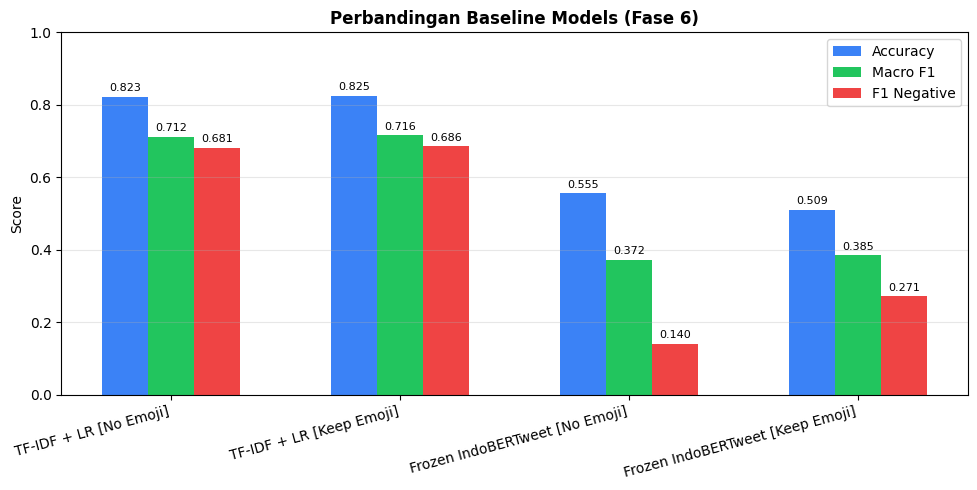

In [ ]:
print("\n" + "="*70)
print("PREVIEW HASIL FASE 6 — BASELINE MODELS")
print("="*70)

df_results_fase6 = pd.DataFrame(all_results)
display(df_results_fase6[[
    'run', 'model_type', 'emoji_mode',
    'accuracy', 'macro_f1', 'f1_negative', 'f1_neutral', 'f1_positive'
]])

# Visualisasi perbandingan 4 run
fig, ax = plt.subplots(figsize=(10, 5))
x     = np.arange(len(df_results_fase6))
width = 0.2

bars1 = ax.bar(x - width,   df_results_fase6['accuracy'],   width, label='Accuracy',  color='#3b82f6')
bars2 = ax.bar(x,           df_results_fase6['macro_f1'],   width, label='Macro F1',  color='#22c55e')
bars3 = ax.bar(x + width,   df_results_fase6['f1_negative'],width, label='F1 Negative',color='#ef4444')

ax.set_xticks(x)
ax.set_xticklabels(df_results_fase6['run'], rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_title('Perbandingan Baseline Models (Fase 6)', fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.0)
ax.grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()



## IndoBERTweet Fine-Tuning

### Full Fine-Tuning IndoBERTWeet


────────────────────────────────────────────────────────────
  Run 5: Full Fine-Tuning [No Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: FULL fine-tuning (semua layer trainable)
  Trainable params: 110,560,515 / 110,560,515 (100.0%)
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training full fine-tuning...
  Epoch 1/5 | Train Loss: 0.8979 | Val Loss: 0.6232 | Val F1: 0.6944 | Time: 80.6s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.5282 | Val Loss: 0.6343 | Val F1: 0.7189 | Time: 79.4s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 3/5 | Train Loss: 0.3776 | Val Loss: 0.6679 | Val F1: 0.7391 | Time: 79.1s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 3


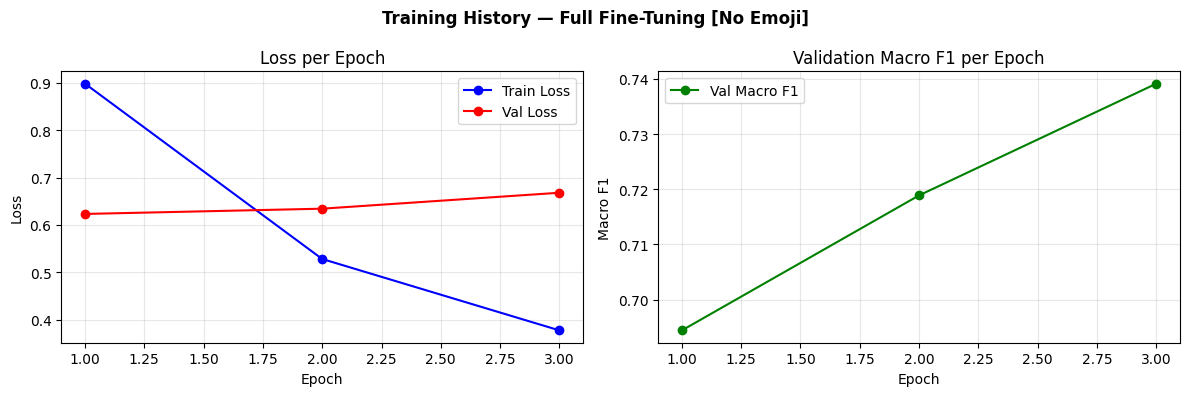


  HASIL: Full FT IndoBERTweet [No Emoji]
              precision    recall  f1-score   support

    negative       0.62      0.80      0.70        60
     neutral       0.60      0.67      0.63        55
    positive       0.95      0.88      0.92       364

    accuracy                           0.85       479
   macro avg       0.72      0.79      0.75       479
weighted avg       0.87      0.85      0.86       479



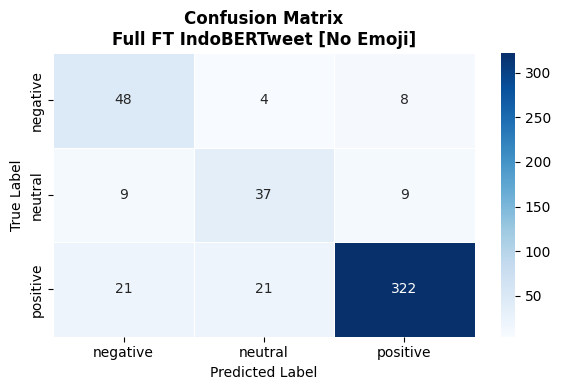

  ✓ Tersimpan ke all_results (total: 5 run)

  ✓ Model disimpan: full_ft_no_emoji.pt
  ✓ GPU cache cleared


────────────────────────────────────────────────────────────
  Run 6: Full Fine-Tuning [Keep Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: FULL fine-tuning (semua layer trainable)
  Trainable params: 110,560,515 / 110,560,515 (100.0%)
DataLoader [text_keep_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training full fine-tuning...
  Epoch 1/5 | Train Loss: 0.9252 | Val Loss: 0.6508 | Val F1: 0.6876 | Time: 79.5s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.5503 | Val Loss: 0.6421 | Val F1: 0.6694 | Time: 79.0s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.3950 | Val Loss: 0.7137 | Val F1: 0.7404 | Time: 79.1s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.3091 | Val Loss: 0.7426 | Val F1: 0.7403 | Time: 79.0s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


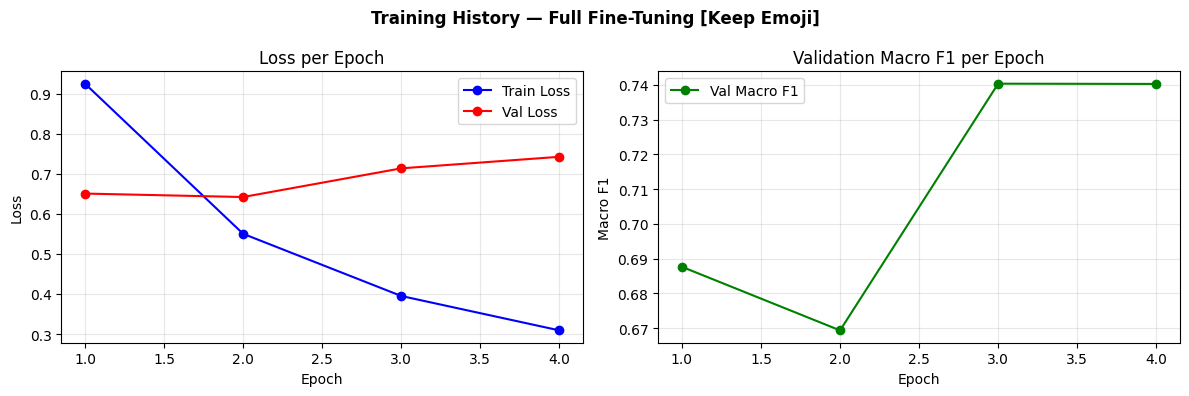


  HASIL: Full FT IndoBERTweet [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.58      0.90      0.71        60
     neutral       0.49      0.71      0.58        55
    positive       0.98      0.83      0.90       364

    accuracy                           0.82       479
   macro avg       0.69      0.81      0.73       479
weighted avg       0.88      0.82      0.84       479



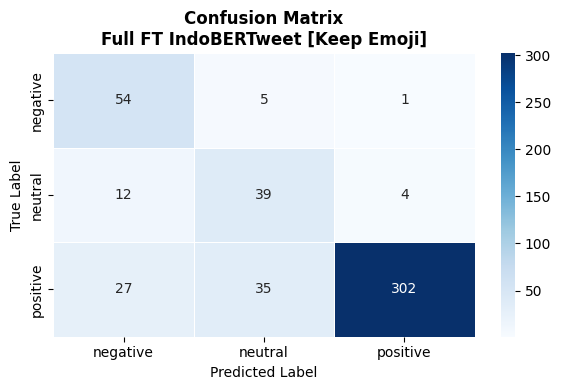

  ✓ Tersimpan ke all_results (total: 6 run)

  ✓ Model disimpan: full_ft_keep_emoji.pt
  ✓ GPU cache cleared

✓ Skenario A selesai — Run 5 & 6 tersimpan di all_results


In [ ]:
# ============================================================
# CELL 7A — SKENARIO A: FULL FINE-TUNING
# Run 5: No Emoji | Run 6: Keep Emoji
# Semua 12 layer BERT + classifier head dilatih
# ============================================================

saved_models_7A = {}  # simpan referensi model untuk perbandingan akhir

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 5'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 6'),
]:
    print(f"\n{'─'*60}")
    print(f"  {run_num}: Full Fine-Tuning [{emoji_mode}]")
    print(f"{'─'*60}")

    # Build model: freeze_mode='none' → semua layer trainable
    model = build_model(freeze_mode='none', dropout_rate=None)

    # Buat DataLoader untuk skenario emoji ini
    train_loader, val_loader, test_loader, y_te = make_dataloaders(text_col)

    # Training dengan loop reusable dari Cell 6D
    print(f"\n  Mulai training full fine-tuning...")
    best_model, history = train_bert(
        model        = model,
        train_loader = train_loader,
        val_loader   = val_loader,
        run_name     = f"Full FT [{emoji_mode}]",
        num_epochs   = NUM_EPOCHS,
        patience     = PATIENCE,
    )

    # Visualisasi training history
    plot_training_history(history, f"Full Fine-Tuning [{emoji_mode}]")

    # Prediksi & evaluasi pada test set
    y_pred = predict_bert(best_model, test_loader)
    result = evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_pred,
        run_name    = f"Full FT IndoBERTweet [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'Full Fine-Tuning',
        freeze_mode = 'None',
        dropout     = 'default',
    )

    # Simpan model checkpoint
    fname = f"full_ft_{'no_emoji' if emoji_mode=='No Emoji' else 'keep_emoji'}.pt"
    torch.save(best_model.state_dict(), base_path + fname)
    print(f"  ✓ Model disimpan: {fname}")

    saved_models_7A[emoji_mode] = best_model

    # Bersihkan VRAM sebelum run berikutnya
    del model
    torch.cuda.empty_cache()
    print(f"  ✓ GPU cache cleared\n")

print("✓ Skenario A selesai — Run 5 & 6 tersimpan di all_results")

### Frozen 6 Layers


────────────────────────────────────────────────────────────
  Run 7: Frozen-6 IndoBERTweet [No Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6...
  Epoch 1/5 | Train Loss: 0.9386 | Val Loss: 0.6369 | Val F1: 0.6892 | Time: 47.8s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.6011 | Val Loss: 0.6111 | Val F1: 0.7162 | Time: 49.2s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.4814 | Val Loss: 0.6495 | Val F1: 0.7106 | Time: 50.7s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.4189 | Val Loss: 0.7069 | Val F1: 0.7383 | Time: 51.6s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


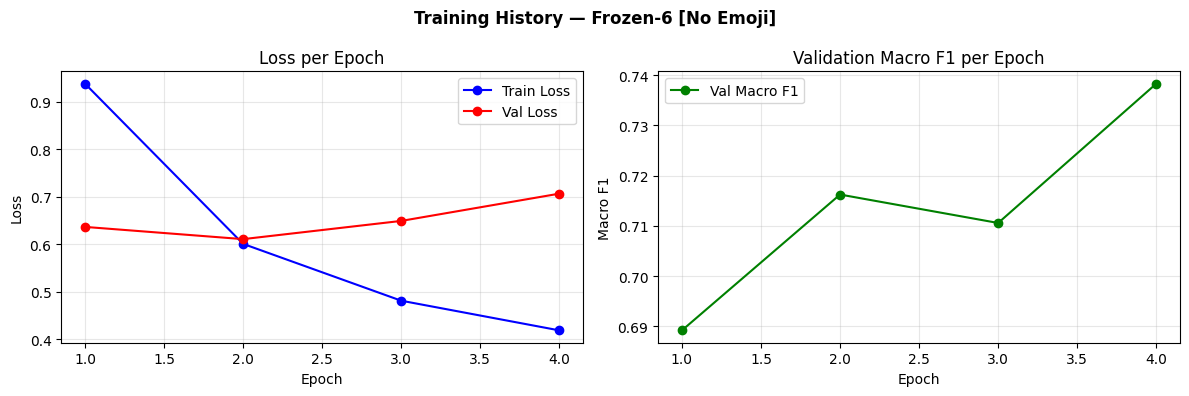


  HASIL: Frozen-6 IndoBERTweet [No Emoji]
              precision    recall  f1-score   support

    negative       0.72      0.78      0.75        60
     neutral       0.56      0.75      0.64        55
    positive       0.94      0.88      0.91       364

    accuracy                           0.86       479
   macro avg       0.74      0.80      0.77       479
weighted avg       0.87      0.86      0.86       479



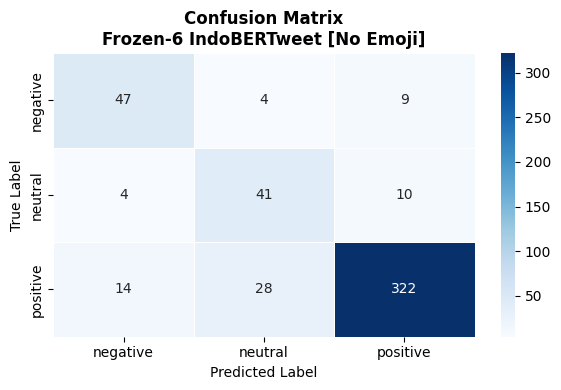

  ✓ Tersimpan ke all_results (total: 7 run)

  ✓ Model disimpan: frozen6_no_emoji.pt
  ✓ GPU cache cleared


────────────────────────────────────────────────────────────
  Run 8: Frozen-6 IndoBERTweet [Keep Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_keep_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6...
  Epoch 1/5 | Train Loss: 0.9406 | Val Loss: 0.6662 | Val F1: 0.6436 | Time: 51.7s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.6079 | Val Loss: 0.6506 | Val F1: 0.7022 | Time: 53.1s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.5034 | Val Loss: 0.7018 | Val F1: 0.7085 | Time: 53.0s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.4323 | Val Loss: 0.6894 | Val F1: 0.7168 | Time: 53.4s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


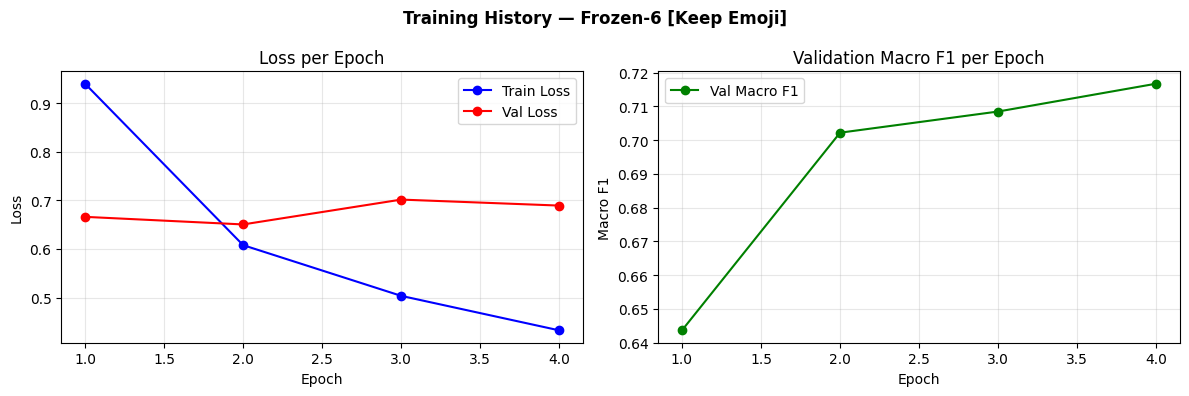


  HASIL: Frozen-6 IndoBERTweet [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.59      0.78      0.67        60
     neutral       0.56      0.58      0.57        55
    positive       0.94      0.88      0.91       364

    accuracy                           0.84       479
   macro avg       0.70      0.75      0.72       479
weighted avg       0.85      0.84      0.84       479



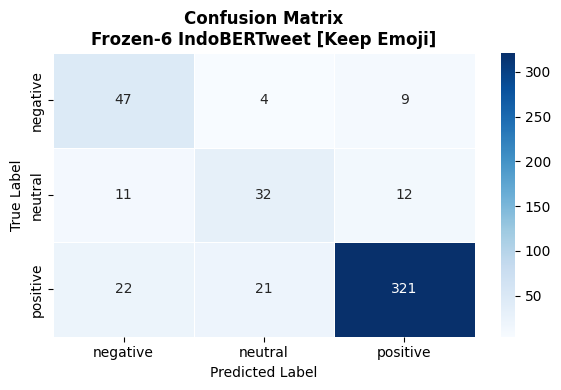

  ✓ Tersimpan ke all_results (total: 8 run)

  ✓ Model disimpan: frozen6_keep_emoji.pt
  ✓ GPU cache cleared

✓ Skenario B selesai — Run 7 & 8 tersimpan di all_results


In [ ]:
# ============================================================
# CELL 7B — SKENARIO B: FROZEN 6 LAYERS
# Run 7: No Emoji | Run 8: Keep Emoji
# Layer 0–5 + embeddings frozen, layer 6–11 + classifier trainable
# ============================================================

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 7'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 8'),
]:
    print(f"\n{'─'*60}")
    print(f"  {run_num}: Frozen-6 IndoBERTweet [{emoji_mode}]")
    print(f"{'─'*60}")

    # Build model: freeze_mode='first6'
    model = build_model(freeze_mode='first6', dropout_rate=None)

    # DataLoader
    train_loader, val_loader, test_loader, y_te = make_dataloaders(text_col)

    # Training
    print(f"\n  Mulai training frozen-6...")
    best_model, history = train_bert(
        model        = model,
        train_loader = train_loader,
        val_loader   = val_loader,
        run_name     = f"Frozen-6 [{emoji_mode}]",
        num_epochs   = NUM_EPOCHS,
        patience     = PATIENCE,
    )

    plot_training_history(history, f"Frozen-6 [{emoji_mode}]")

    y_pred = predict_bert(best_model, test_loader)
    evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_pred,
        run_name    = f"Frozen-6 IndoBERTweet [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'Frozen-6',
        freeze_mode = '6 layers (0–5)',
        dropout     = 'default',
    )

    fname = f"frozen6_{'no_emoji' if emoji_mode=='No Emoji' else 'keep_emoji'}.pt"
    torch.save(best_model.state_dict(), base_path + fname)
    print(f"  ✓ Model disimpan: {fname}")

    del model
    torch.cuda.empty_cache()
    print(f"  ✓ GPU cache cleared\n")

print("✓ Skenario B selesai — Run 7 & 8 tersimpan di all_results")

### Frozen 6 Layers + Dropout 0.1


────────────────────────────────────────────────────────────
  Run 9: Frozen-6 + Dropout 0.1 [No Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Dropout classifier diset ke: 0.1
  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6 + dropout 0.1...
  Epoch 1/5 | Train Loss: 0.9199 | Val Loss: 0.6960 | Val F1: 0.6600 | Time: 54.0s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.5858 | Val Loss: 0.6287 | Val F1: 0.7155 | Time: 52.8s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.4913 | Val Loss: 0.6699 | Val F1: 0.7102 | Time: 53.4s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.4133 | Val Loss: 0.7238 | Val F1: 0.7115 | Time: 53.2s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


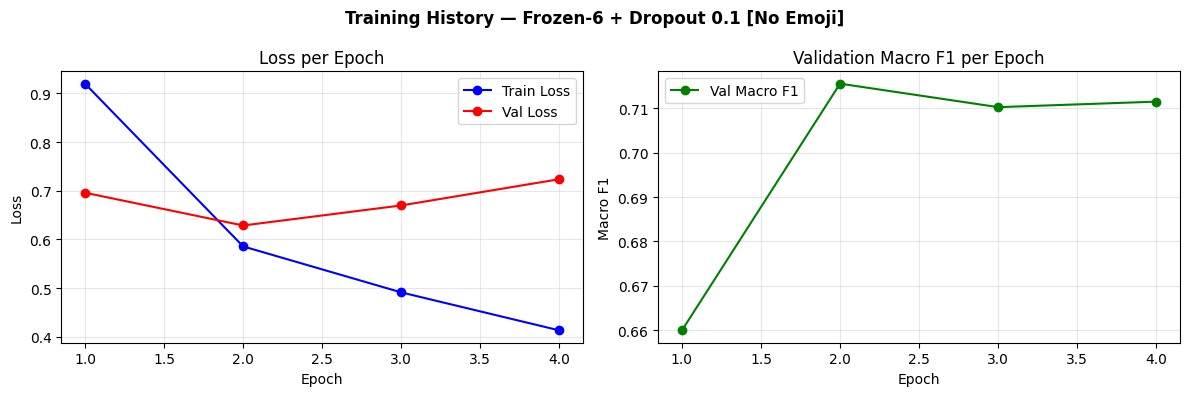


  HASIL: Frozen-6+Dropout IndoBERTweet [No Emoji]
              precision    recall  f1-score   support

    negative       0.72      0.77      0.74        60
     neutral       0.59      0.73      0.65        55
    positive       0.94      0.90      0.92       364

    accuracy                           0.86       479
   macro avg       0.75      0.80      0.77       479
weighted avg       0.87      0.86      0.86       479



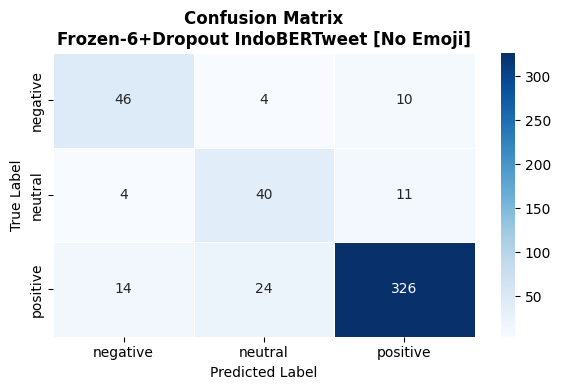

  ✓ Tersimpan ke all_results (total: 9 run)

  🏆 Model terbaik baru! Macro F1 = 0.7698
  ✓ Model disimpan: frozen6_dropout_no_emoji.pt
  ✓ GPU cache cleared


────────────────────────────────────────────────────────────
  Run 10: Frozen-6 + Dropout 0.1 [Keep Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Dropout classifier diset ke: 0.1
  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_keep_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6 + dropout 0.1...
  Epoch 1/5 | Train Loss: 0.9331 | Val Loss: 0.6428 | Val F1: 0.6578 | Time: 53.7s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.5928 | Val Loss: 0.6368 | Val F1: 0.6968 | Time: 53.0s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.4965 | Val Loss: 0.6710 | Val F1: 0.7341 | Time: 53.3s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.4316 | Val Loss: 0.7151 | Val F1: 0.7348 | Time: 53.0s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


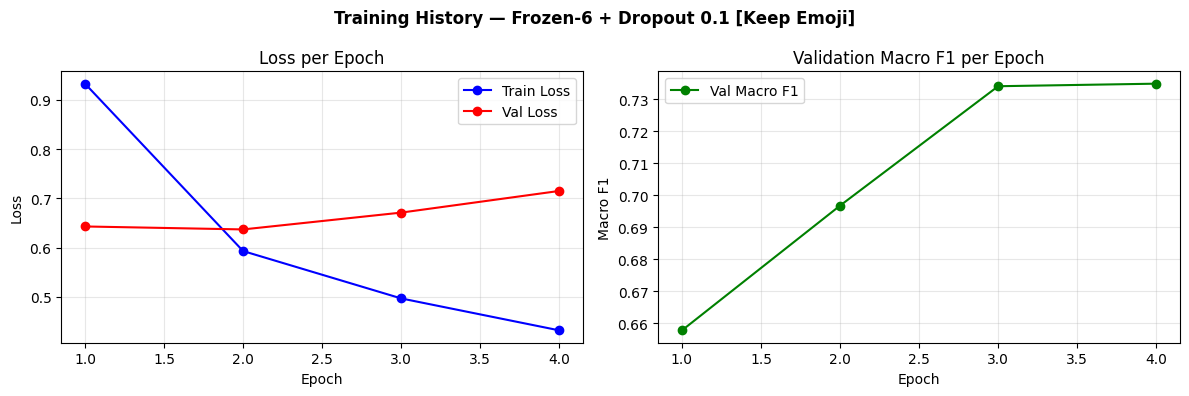


  HASIL: Frozen-6+Dropout IndoBERTweet [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.64      0.82      0.72        60
     neutral       0.49      0.69      0.58        55
    positive       0.95      0.85      0.90       364

    accuracy                           0.83       479
   macro avg       0.69      0.79      0.73       479
weighted avg       0.86      0.83      0.84       479



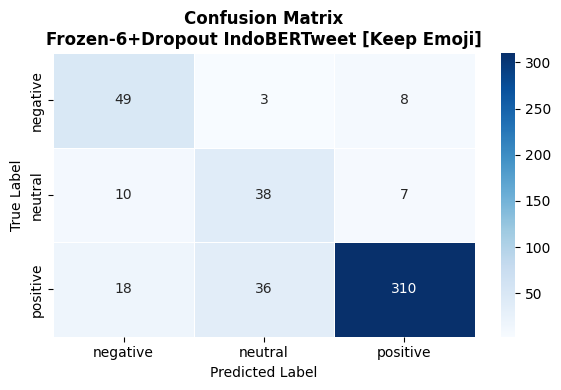

  ✓ Tersimpan ke all_results (total: 10 run)

  ✓ Model disimpan: frozen6_dropout_keep_emoji.pt
  ✓ GPU cache cleared

✓ Skenario C selesai — Run 9 & 10 tersimpan di all_results


In [ ]:
# ============================================================
# CELL 7C — SKENARIO C: FROZEN 6 LAYERS + DROPOUT 0.1
# Run 9: No Emoji | Run 10: Keep Emoji
# ============================================================

saved_best_model = None        # untuk simpan model terbaik keseluruhan
saved_best_f1    = 0.0

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 9'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 10'),
]:
    print(f"\n{'─'*60}")
    print(f"  {run_num}: Frozen-6 + Dropout 0.1 [{emoji_mode}]")
    print(f"{'─'*60}")

    # Build model: freeze 6 layer + override dropout = 0.1
    model = build_model(freeze_mode='first6', dropout_rate=0.1)

    train_loader, val_loader, test_loader, y_te = make_dataloaders(text_col)

    print(f"\n  Mulai training frozen-6 + dropout 0.1...")
    best_model, history = train_bert(
        model        = model,
        train_loader = train_loader,
        val_loader   = val_loader,
        run_name     = f"Frozen-6+DO [{emoji_mode}]",
        num_epochs   = NUM_EPOCHS,
        patience     = PATIENCE,
    )

    plot_training_history(history, f"Frozen-6 + Dropout 0.1 [{emoji_mode}]")

    y_pred = predict_bert(best_model, test_loader)
    result = evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_pred,
        run_name    = f"Frozen-6+Dropout IndoBERTweet [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'Frozen-6 + Dropout',
        freeze_mode = '6 layers (0–5)',
        dropout     = '0.1',
    )

    # Track model terbaik keseluruhan
    if result['macro_f1'] > saved_best_f1:
        saved_best_f1   = result['macro_f1']
        saved_best_model = best_model
        best_run_name   = result['run']
        print(f"  🏆 Model terbaik baru! Macro F1 = {saved_best_f1:.4f}")

    fname = f"frozen6_dropout_{'no_emoji' if emoji_mode=='No Emoji' else 'keep_emoji'}.pt"
    torch.save(best_model.state_dict(), base_path + fname)
    print(f"  ✓ Model disimpan: {fname}")

    del model
    torch.cuda.empty_cache()
    print(f"  ✓ GPU cache cleared\n")

print("✓ Skenario C selesai — Run 9 & 10 tersimpan di all_results")

### Frozen 6 Layer + Dropout 0.5


────────────────────────────────────────────────────────────
  Run 11: Frozen-6 + Dropout 0.5 [No Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Dropout classifier diset ke: 0.5
  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6 + dropout 0.5...
  Epoch 1/5 | Train Loss: 0.9208 | Val Loss: 0.6210 | Val F1: 0.7057 | Time: 54.4s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.5793 | Val Loss: 0.6652 | Val F1: 0.6929 | Time: 53.0s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 3/5 | Train Loss: 0.4881 | Val Loss: 0.6423 | Val F1: 0.7169 | Time: 53.6s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 3


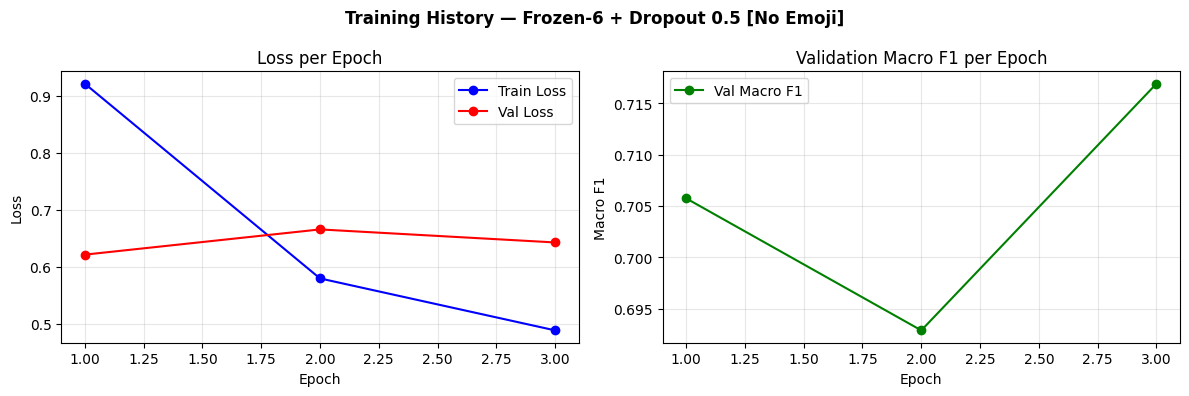


  HASIL: Frozen-6+Dropout IndoBERTweet [No Emoji]
              precision    recall  f1-score   support

    negative       0.61      0.77      0.68        60
     neutral       0.58      0.65      0.62        55
    positive       0.94      0.88      0.91       364

    accuracy                           0.84       479
   macro avg       0.71      0.77      0.73       479
weighted avg       0.86      0.84      0.85       479



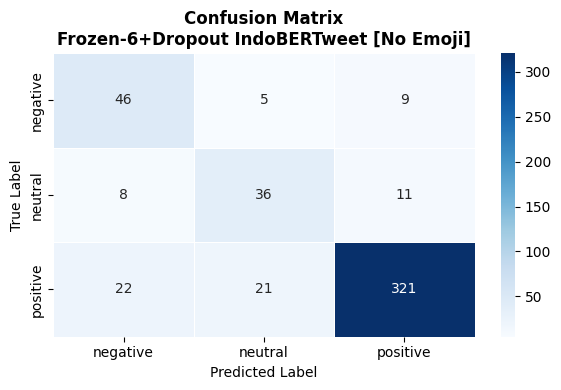

  ✓ Tersimpan ke all_results (total: 11 run)

  🏆 Model terbaik baru! Macro F1 = 0.7342
  ✓ Model disimpan: frozen6_dropout_no_emoji.pt
  ✓ GPU cache cleared


────────────────────────────────────────────────────────────
  Run 12: Frozen-6 + Dropout 0.5 [Keep Emoji]
────────────────────────────────────────────────────────────


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Dropout classifier diset ke: 0.5
  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
DataLoader [text_keep_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch

  Mulai training frozen-6 + dropout 0.5...
  Epoch 1/5 | Train Loss: 0.9363 | Val Loss: 0.6625 | Val F1: 0.7133 | Time: 53.6s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 2/5 | Train Loss: 0.6039 | Val Loss: 0.6612 | Val F1: 0.7110 | Time: 53.1s
    ✓ Val loss membaik → simpan checkpoint
  Epoch 3/5 | Train Loss: 0.4922 | Val Loss: 0.6978 | Val F1: 0.7220 | Time: 53.2s
    ✗ Tidak ada perbaikan (1/2)
  Epoch 4/5 | Train Loss: 0.4150 | Val Loss: 0.7268 | Val F1: 0.7115 | Time: 53.2s
    ✗ Tidak ada perbaikan (2/2)
  ⚡ Early stopping di epoch 4


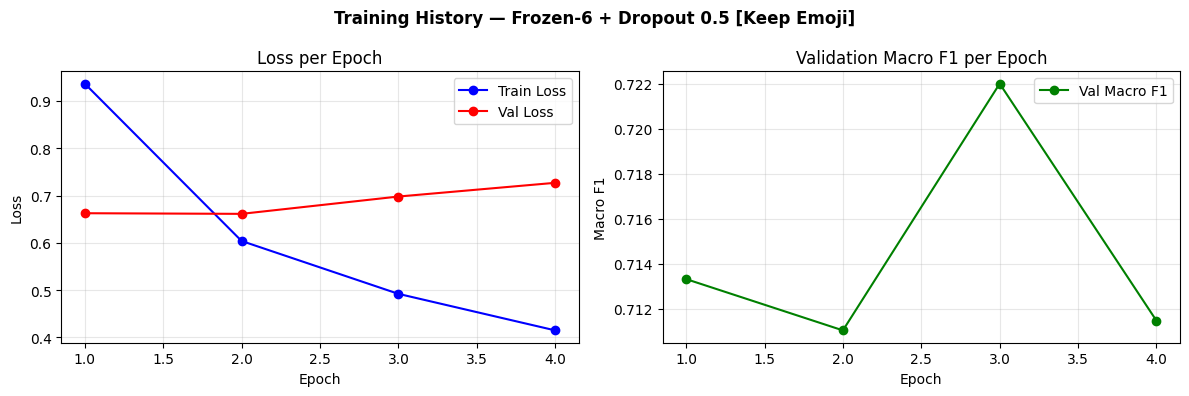


  HASIL: Frozen-6+Dropout IndoBERTweet [Keep Emoji]
              precision    recall  f1-score   support

    negative       0.63      0.78      0.70        60
     neutral       0.59      0.62      0.60        55
    positive       0.94      0.90      0.92       364

    accuracy                           0.85       479
   macro avg       0.72      0.77      0.74       479
weighted avg       0.86      0.85      0.85       479



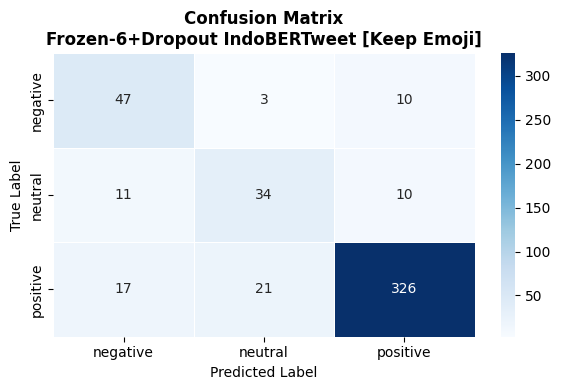

  ✓ Tersimpan ke all_results (total: 12 run)

  🏆 Model terbaik baru! Macro F1 = 0.7388
  ✓ Model disimpan: frozen6_dropout_keep_emoji.pt
  ✓ GPU cache cleared

✓ Skenario C selesai — Run 9 & 10 tersimpan di all_results


In [ ]:
# ============================================================
# CELL 7D — SKENARIO D: FROZEN 6 LAYERS + DROPOUT 0.5
# Run 11: No Emoji | Run 12: Keep Emoji
# ============================================================

saved_best_model = None        # untuk simpan model terbaik keseluruhan
saved_best_f1    = 0.0

for emoji_mode, text_col, run_num in [
    ('No Emoji',   'text_no_emoji',   'Run 11'),
    ('Keep Emoji', 'text_keep_emoji', 'Run 12'),
]:
    print(f"\n{'─'*60}")
    print(f"  {run_num}: Frozen-6 + Dropout 0.5 [{emoji_mode}]")
    print(f"{'─'*60}")

    # Build model: freeze 6 layer + override dropout = 0.5
    model = build_model(freeze_mode='first6', dropout_rate=0.5)

    train_loader, val_loader, test_loader, y_te = make_dataloaders(text_col)

    print(f"\n  Mulai training frozen-6 + dropout 0.5...")
    best_model, history = train_bert(
        model        = model,
        train_loader = train_loader,
        val_loader   = val_loader,
        run_name     = f"Frozen-6+DO [{emoji_mode}]",
        num_epochs   = NUM_EPOCHS,
        patience     = PATIENCE,
    )

    plot_training_history(history, f"Frozen-6 + Dropout 0.5 [{emoji_mode}]")

    y_pred = predict_bert(best_model, test_loader)
    result = evaluate_and_log(
        y_true      = y_te,
        y_pred      = y_pred,
        run_name    = f"Frozen-6+Dropout IndoBERTweet [{emoji_mode}]",
        emoji_mode  = emoji_mode,
        model_type  = 'Frozen-6 + Dropout',
        freeze_mode = '6 layers (0–5)',
        dropout     = '0.5',
    )

    # Track model terbaik keseluruhan
    if result['macro_f1'] > saved_best_f1:
        saved_best_f1   = result['macro_f1']
        saved_best_model = best_model
        best_run_name   = result['run']
        print(f"  🏆 Model terbaik baru! Macro F1 = {saved_best_f1:.4f}")

    fname = f"frozen6_dropout_{'no_emoji' if emoji_mode=='No Emoji' else 'keep_emoji'}.pt"
    torch.save(best_model.state_dict(), base_path + fname)
    print(f"  ✓ Model disimpan: {fname}")

    del model
    torch.cuda.empty_cache()
    print(f"  ✓ GPU cache cleared\n")

print("✓ Skenario C selesai — Run 11 & 12 tersimpan di all_results")

### final Comparison Table

,run,model_type,emoji_mode,freeze,dropout,accuracy,macro_f1,macro_p,macro_r,f1_negative,f1_neutral,f1_positive
0,TF-IDF + LR [No Emoji],TF-IDF + LR,No Emoji,—,—,0.8225,0.7122,0.6789,0.7641,0.6812,0.5538,0.9014
1,TF-IDF + LR [Keep Emoji],TF-IDF + LR,Keep Emoji,—,—,0.8246,0.7155,0.6811,0.7696,0.6857,0.5581,0.9028
2,Frozen IndoBERTweet [No Emoji],Frozen BERT (Baseline),No Emoji,All layers,default,0.5553,0.3725,0.3873,0.3759,0.1398,0.2569,0.7210
3,Frozen IndoBERTweet [Keep Emoji],Frozen BERT (Baseline),Keep Emoji,All layers,default,0.5094,0.3846,0.4059,0.4388,0.2712,0.2281,0.6546
4,Full FT IndoBERTweet [No Emoji],Full Fine-Tuning,No Emoji,None,default,0.8497,0.7481,0.7207,0.7858,0.6957,0.6325,0.9161
5,Full FT IndoBERTweet [Keep Emoji],Full Fine-Tuning,Keep Emoji,None,default,0.8246,0.7294,0.6860,0.8129,0.7059,0.5821,0.9001
6,Frozen-6 IndoBERTweet [No Emoji],Frozen-6,No Emoji,6 layers (0–5),default,0.8559,0.7687,0.7430,0.8045,0.7520,0.6406,0.9135
7,Frozen-6 IndoBERTweet [Keep Emoji],Frozen-6,Keep Emoji,6 layers (0–5),default,0.8351,0.7174,0.6958,0.7490,0.6714,0.5714,0.9093
8,Frozen-6+Dropout IndoBERTweet [No Emoji],Frozen-6 + Dropout,No Emoji,6 layers (0–5),0.1,0.8601,0.7698,0.7488,0.7965,0.7419,0.6504,0.9170
9,Frozen-6+Dropout IndoBERTweet [Keep Emoji],Frozen-6 + Dropout,Keep Emoji,6 layers (0–5),0.1,0.8288,0.7303,0.6946,0.7864,0.7153,0.5758,0.8999


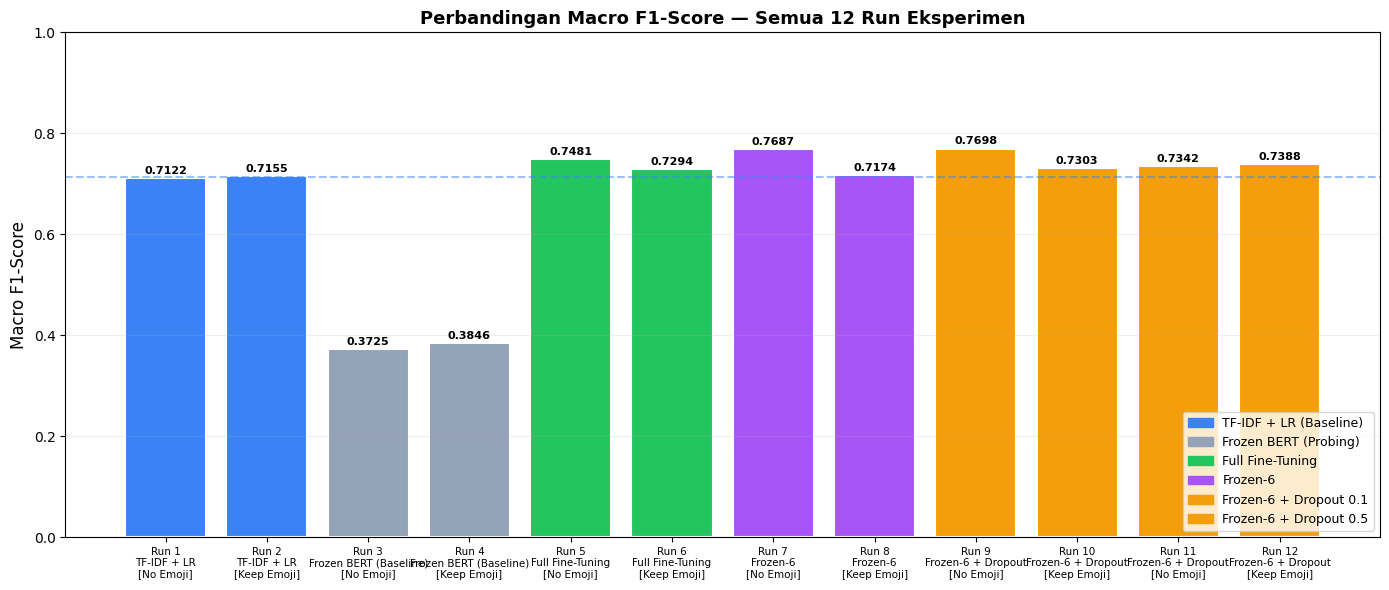

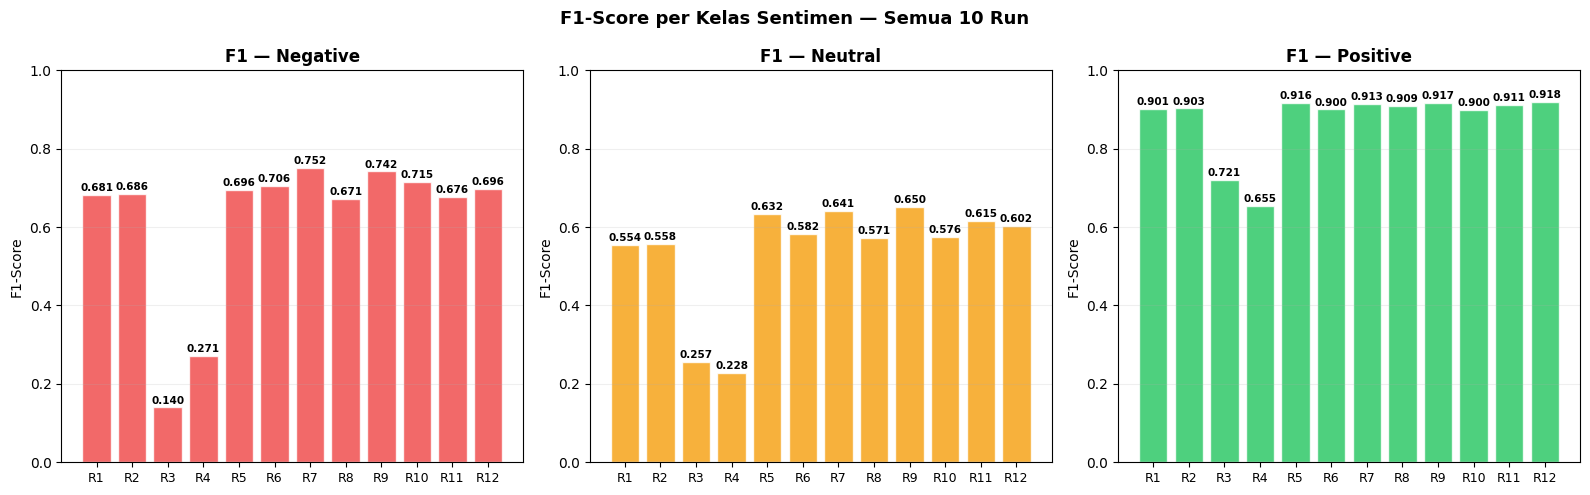

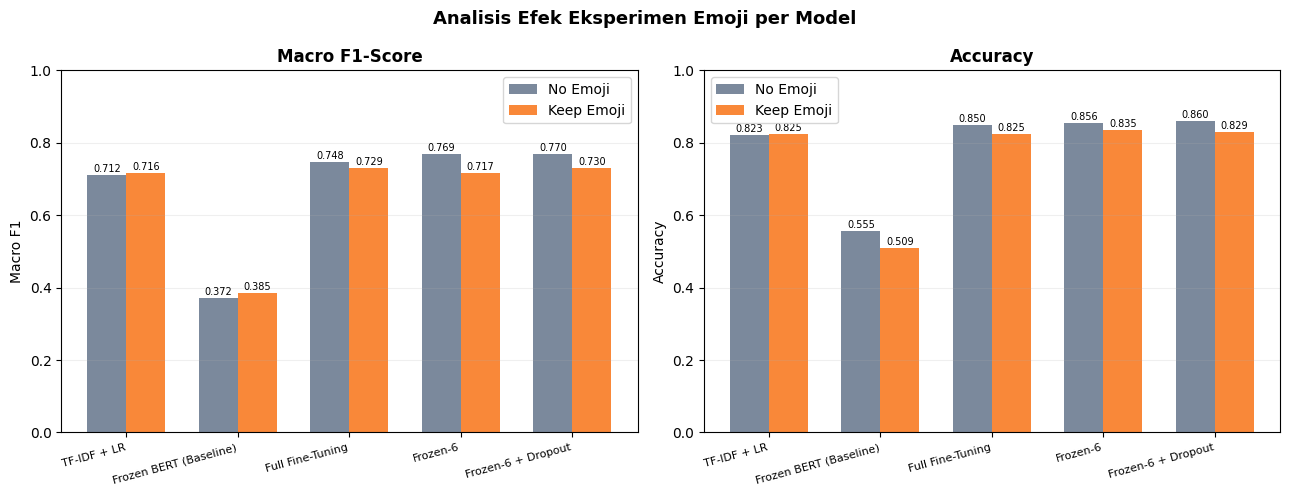


RINGKASAN ANALITIK HASIL EKSPERIMEN

🏆 Model terbaik : Frozen-6+Dropout IndoBERTweet [No Emoji]
   Macro F1       : 0.7698
   Accuracy       : 0.8601

⚠️  Model terlemah: Frozen IndoBERTweet [No Emoji]
   Macro F1       : 0.3725

📊 Rata-rata efek emoji:
   TF-IDF + LR                 : ↑ 0.0033 (Keep Emoji lebih baik)
   Frozen BERT (Baseline)      : ↑ 0.0121 (Keep Emoji lebih baik)
   Full Fine-Tuning            : ↓ 0.0187 (No Emoji lebih baik)
   Frozen-6                    : ↓ 0.0513 (No Emoji lebih baik)

📊 Perbandingan Full FT vs Frozen-6 (rata-rata emoji):
   Full Fine-Tuning        : 0.7388
   Frozen-6                : 0.7430
   Frozen-6 + Dropout 0.1  : 0.7433

✓ Semua 10 run selesai. Lanjut ke Fase 8 — Error Analysis


In [ ]:
# ============================================================
# CELL 7E — TABEL PERBANDINGAN FINAL (12 RUN)
# ============================================================
import matplotlib.patches as mpatches

df_all = pd.DataFrame(all_results)

# ── Tampilkan tabel lengkap ───────────────────────────────
display(
    df_all[[
        'run', 'model_type', 'emoji_mode', 'freeze', 'dropout',
        'accuracy', 'macro_f1', 'macro_p', 'macro_r',
        'f1_negative', 'f1_neutral', 'f1_positive'
    ]].round(4)
)

# ── Simpan ke CSV ─────────────────────────────────────────
# df_all.to_csv(base_path + 'hasil_semua_run.csv', index=False)
# print("\n✓ Hasil disimpan: hasil_semua_run.csv")

# ── Visualisasi 1: Bar Chart Macro F1 semua run ───────────
fig, ax = plt.subplots(figsize=(14, 6))

colors = []
for _, row in df_all.iterrows():
    if 'TF-IDF' in row['model_type']:
        colors.append('#3b82f6')   # biru: baseline klasik
    elif 'Frozen BERT' in row['model_type']:
        colors.append('#94a3b8')   # abu: frozen baseline
    elif 'Full' in row['model_type']:
        colors.append('#22c55e')   # hijau: full FT
    elif 'Dropout' in row['model_type']:
        colors.append('#f59e0b')   # kuning: frozen + dropout
    else:
        colors.append('#a855f7')   # ungu: frozen-6

bars = ax.bar(range(len(df_all)), df_all['macro_f1'], color=colors,
              edgecolor='white', linewidth=1.5)

ax.set_xticks(range(len(df_all)))
ax.set_xticklabels(
    [f"Run {i+1}\n{row['model_type']}\n[{row['emoji_mode']}]"
     for i, (_, row) in enumerate(df_all.iterrows())],
    rotation=0, fontsize=7.5
)
ax.set_ylabel('Macro F1-Score', fontsize=12)
ax.set_title('Perbandingan Macro F1-Score — Semua 12 Run Eksperimen', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.0)
ax.axhline(y=df_all[df_all['model_type']=='TF-IDF + LR']['macro_f1'].mean(),
           color='#3b82f6', linestyle='--', alpha=0.5, label='Rata-rata TF-IDF LR')
ax.grid(True, alpha=0.2, axis='y')

for bar, val in zip(bars, df_all['macro_f1']):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.008,
            f'{val:.4f}', ha='center', fontsize=8, fontweight='bold')

# Legend
patches = [
    mpatches.Patch(color='#3b82f6', label='TF-IDF + LR (Baseline)'),
    mpatches.Patch(color='#94a3b8', label='Frozen BERT (Probing)'),
    mpatches.Patch(color='#22c55e', label='Full Fine-Tuning'),
    mpatches.Patch(color='#a855f7', label='Frozen-6'),
    mpatches.Patch(color='#f59e0b', label='Frozen-6 + Dropout 0.1'),
    mpatches.Patch(color='#f59e0b', label='Frozen-6 + Dropout 0.5'),
]
ax.legend(handles=patches, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

# ── Visualisasi 2: F1 per Kelas semua run ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('F1-Score per Kelas Sentimen — Semua 10 Run', fontweight='bold', fontsize=13)

for ax, kelas, color in zip(axes,
    ['f1_negative', 'f1_neutral', 'f1_positive'],
    ['#ef4444',     '#f59e0b',    '#22c55e']):

    bars = ax.bar(range(len(df_all)), df_all[kelas], color=color,
                  alpha=0.8, edgecolor='white')
    ax.set_title(f'F1 — {kelas.replace("f1_","").capitalize()}', fontweight='bold')
    ax.set_xticks(range(len(df_all)))
    ax.set_xticklabels([f"R{i+1}" for i in range(len(df_all))], fontsize=9)
    ax.set_ylabel('F1-Score')
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.2, axis='y')
    for bar, val in zip(bars, df_all[kelas]):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.show()

# ── Visualisasi 3: Emoji Effect Analysis ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Analisis Efek Eksperimen Emoji per Model', fontweight='bold', fontsize=13)

model_types = df_all['model_type'].unique()
x = np.arange(len(model_types))
width = 0.35

for ax, metric, title in zip(axes,
    ['macro_f1', 'accuracy'],
    ['Macro F1-Score', 'Accuracy']):

    no_emoji_vals   = [df_all[(df_all['model_type']==m) & (df_all['emoji_mode']=='No Emoji')][metric].values[0]
                       for m in model_types]
    keep_emoji_vals = [df_all[(df_all['model_type']==m) & (df_all['emoji_mode']=='Keep Emoji')][metric].values[0]
                       for m in model_types]

    bars1 = ax.bar(x - width/2, no_emoji_vals,   width, label='No Emoji',   color='#64748b', alpha=0.85)
    bars2 = ax.bar(x + width/2, keep_emoji_vals, width, label='Keep Emoji', color='#f97316', alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(model_types, rotation=15, ha='right', fontsize=8)
    ax.set_ylabel(metric.replace('_', ' ').title())
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.legend()
    ax.grid(True, alpha=0.2, axis='y')

    for bar, val in zip(bars1, no_emoji_vals):
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.008,
                f'{val:.3f}', ha='center', fontsize=7)
    for bar, val in zip(bars2, keep_emoji_vals):
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.008,
                f'{val:.3f}', ha='center', fontsize=7)

plt.tight_layout()
plt.show()

# ── Ringkasan analitik ────────────────────────────────────
print("\n" + "="*65)
print("RINGKASAN ANALITIK HASIL EKSPERIMEN")
print("="*65)

best_run = df_all.loc[df_all['macro_f1'].idxmax()]
worst_run = df_all.loc[df_all['macro_f1'].idxmin()]

print(f"\n🏆 Model terbaik : {best_run['run']}")
print(f"   Macro F1       : {best_run['macro_f1']:.4f}")
print(f"   Accuracy       : {best_run['accuracy']:.4f}")

print(f"\n⚠️  Model terlemah: {worst_run['run']}")
print(f"   Macro F1       : {worst_run['macro_f1']:.4f}")

# Emoji effect
print(f"\n📊 Rata-rata efek emoji:")
for mtype in df_all['model_type'].unique():
    sub = df_all[df_all['model_type'] == mtype]
    if len(sub) == 2:
        no_e  = sub[sub['emoji_mode']=='No Emoji']['macro_f1'].values[0]
        keep_e= sub[sub['emoji_mode']=='Keep Emoji']['macro_f1'].values[0]
        delta = keep_e - no_e
        arah  = '↑' if delta > 0 else '↓'
        print(f"   {mtype:<28}: {arah} {abs(delta):.4f} "
              f"({'Keep Emoji lebih baik' if delta > 0 else 'No Emoji lebih baik'})")

print(f"\n📊 Perbandingan Full FT vs Frozen-6 (rata-rata emoji):")
full_avg = df_all[df_all['model_type']=='Full Fine-Tuning']['macro_f1'].mean()
f6_avg   = df_all[df_all['model_type']=='Frozen-6']['macro_f1'].mean()
f6do_avg = df_all[df_all['model_type']=='Frozen-6 + Dropout']['macro_f1'].mean()
print(f"   Full Fine-Tuning        : {full_avg:.4f}")
print(f"   Frozen-6                : {f6_avg:.4f}")
print(f"   Frozen-6 + Dropout 0.1  : {f6do_avg:.4f}")

print(f"\n✓ Semua 10 run selesai. Lanjut ke Fase 8 — Error Analysis")

## Error Analysis

### Load Best Model & Ekstrak Error

In [ ]:
# ============================================================
# Best model: Frozen-6 + Dropout 0.1, No Emoji
# ============================================================

# ── Konfigurasi best model ────────────────────────────────
BEST_MODEL_CONFIG = {
    'freeze_mode'  : 'first6',
    'dropout_rate' : 0.1,
    'emoji_mode'   : 'No Emoji',
    'text_col'     : 'text_no_emoji',
    'model_file'   : 'frozen6_dropout_no_emoji.pt',
    'run_name'     : 'Frozen-6 + Dropout 0.1 [No Emoji]',
}

print("="*60)
print("LOAD BEST MODEL")
print("="*60)
print(f"  Config : {BEST_MODEL_CONFIG['run_name']}")

# Load model
best_model = build_model(
    freeze_mode  = BEST_MODEL_CONFIG['freeze_mode'],
    dropout_rate = BEST_MODEL_CONFIG['dropout_rate'],
)
best_model.load_state_dict(
    torch.load(base_path + BEST_MODEL_CONFIG['model_file'],
               map_location=device)
)
best_model.eval()
print("  ✓ Model loaded dan dalam mode eval()")

# ── Buat DataLoader test set untuk best model ─────────────
_, _, test_loader, y_test_true = make_dataloaders(
    BEST_MODEL_CONFIG['text_col']
)

# ── Prediksi + kumpulkan probabilitas ─────────────────────
all_preds, all_probs, all_true = [], [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels']

        outputs = best_model(input_ids=input_ids,
                             attention_mask=attention_mask)
        probs   = torch.softmax(outputs.logits, dim=1)
        preds   = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_true.extend(labels.numpy())

y_pred = np.array(all_preds)
y_prob = np.array(all_probs)
y_true = np.array(all_true)

print(f"  Total test sampel : {len(y_true)}")
print(f"  Total prediksi benar: {(y_pred == y_true).sum()} ({(y_pred == y_true).mean()*100:.1f}%)")
print(f"  Total prediksi salah: {(y_pred != y_true).sum()} ({(y_pred != y_true).mean()*100:.1f}%)")

# ── Bangun DataFrame error ─────────────────────────────────
# Ambil teks asli dari df_final menggunakan test index
test_texts_raw      = df_final.loc[X_test_idx, 'review_text'].values
test_texts_processed= df_final.loc[X_test_idx, BEST_MODEL_CONFIG['text_col']].values

df_errors = pd.DataFrame({
    'review_asli'      : test_texts_raw,
    'review_processed' : test_texts_processed,
    'label_benar'      : le.inverse_transform(y_true),
    'label_prediksi'   : le.inverse_transform(y_pred),
    'prob_negative'    : y_prob[:, le.transform(['negative'])[0]],
    'prob_neutral'     : y_prob[:, le.transform(['neutral'])[0]],
    'prob_positive'    : y_prob[:, le.transform(['positive'])[0]],
    'confidence'       : y_prob.max(axis=1),
    'is_error'         : y_pred != y_true,
})

# Filter hanya yang salah
df_errors = df_errors[df_errors['is_error']].reset_index(drop=True)
print(f"\n  DataFrame error berhasil dibuat: {len(df_errors)} baris")
display(df_errors[['review_asli','label_benar','label_prediksi','confidence']].head(5))

LOAD BEST MODEL
  Config : Frozen-6 + Dropout 0.1 [No Emoji]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Dropout classifier diset ke: 0.1
  Freeze mode: 6 BERT layers frozen (layer 0–5 + embeddings)
  Trainable params: 43,120,131 / 110,560,515 (39.0%)
  ✓ Model loaded dan dalam mode eval()
DataLoader [text_no_emoji]:
  Train: 3826 sampel | 120 batch
  Val  : 478 sampel | 8 batch
  Test : 479 sampel | 8 batch
  Total test sampel : 479
  Total prediksi benar: 403 (84.1%)
  Total prediksi salah: 76 (15.9%)

  DataFrame error berhasil dibuat: 76 baris


,review_asli,label_benar,label_prediksi,confidence
0,"Tempat nya nya nyaman masih asri, tp sayang banyak sampah nya.",neutral,positive,0.846720
1,"Tempat faforit saya, lembah yang indah",positive,neutral,0.529365
2,"Spot gacor ikan keropak sama udang galah, Disamping spot ada warung nasi & kopi",positive,neutral,0.756571
3,"Air terjun nya belum mengalir, masih kering",neutral,positive,0.387814
4,Sebuah bangunan peninggalan Majapahit yg syarat akan sejarah dan budaya...\nSemoga tempat ini tetap awet terjaga dan lestari\n\nSalam rahayu,positive,neutral,0.490138


### Confussion Matrix Detail & Error Pattern

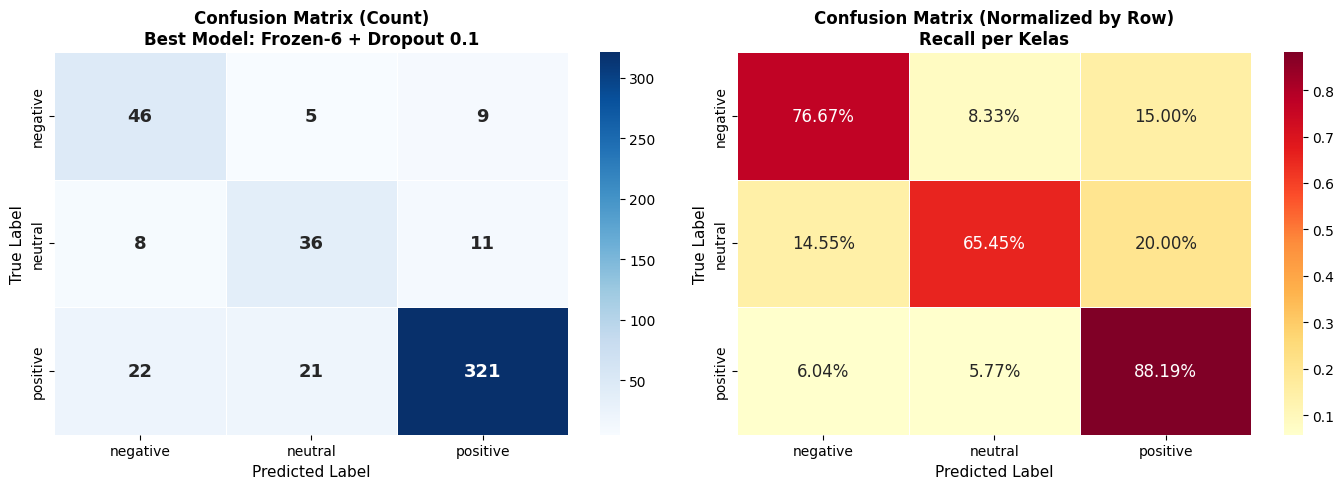


POLA ERROR — BREAKDOWN PER KONFUSI KELAS
  negative → neutral            : 5 kasus (6.6% dari total error)
  negative → positive           : 9 kasus (11.8% dari total error)
  neutral → negative            : 8 kasus (10.5% dari total error)
  neutral → positive            : 11 kasus (14.5% dari total error)
  positive → negative           : 22 kasus (28.9% dari total error)
  positive → neutral            : 21 kasus (27.6% dari total error)


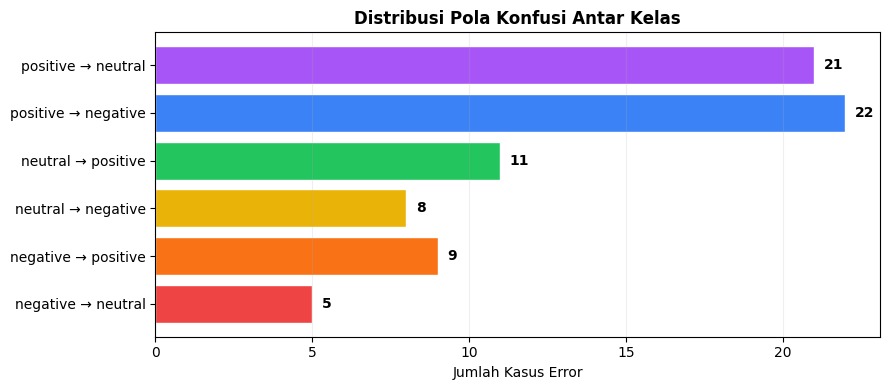

In [ ]:
# ── Confusion matrix ──────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm,
    index   = [f'True: {c}' for c in le.classes_],
    columns = [f'Pred: {c}' for c in le.classes_]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw counts
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=le.classes_, yticklabels=le.classes_,
            cmap='Blues', ax=axes[0], linewidths=0.5,
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix (Count)\nBest Model: Frozen-6 + Dropout 0.1',
                  fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)

# Plot 2: Normalized (row-wise = recall per kelas)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%',
            xticklabels=le.classes_, yticklabels=le.classes_,
            cmap='YlOrRd', ax=axes[1], linewidths=0.5,
            annot_kws={'size': 12})
axes[1].set_title('Confusion Matrix (Normalized by Row)\nRecall per Kelas',
                  fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)

plt.tight_layout()
plt.show()

# ── Analisis pola error ───────────────────────────────────
print("\n" + "="*60)
print("POLA ERROR — BREAKDOWN PER KONFUSI KELAS")
print("="*60)

error_patterns = {}
for true_label in le.classes_:
    for pred_label in le.classes_:
        if true_label == pred_label:
            continue
        subset = df_errors[
            (df_errors['label_benar'] == true_label) &
            (df_errors['label_prediksi'] == pred_label)
        ]
        if len(subset) > 0:
            key = f"{true_label} → {pred_label}"
            error_patterns[key] = len(subset)
            print(f"  {key:<30}: {len(subset)} kasus "
                  f"({len(subset)/len(df_errors)*100:.1f}% dari total error)")

# Visualisasi proporsi error pattern
fig, ax = plt.subplots(figsize=(9, 4))
patterns = list(error_patterns.keys())
counts   = list(error_patterns.values())
colors_ep = ['#ef4444','#f97316','#eab308','#22c55e','#3b82f6','#a855f7'][:len(patterns)]

bars = ax.barh(patterns, counts, color=colors_ep, edgecolor='white')
ax.set_xlabel('Jumlah Kasus Error')
ax.set_title('Distribusi Pola Konfusi Antar Kelas', fontweight='bold')
for bar, val in zip(bars, counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            str(val), va='center', fontweight='bold')
ax.grid(True, alpha=0.2, axis='x')
plt.tight_layout()
plt.show()

### Qualitative Error Categorization

DISTRIBUSI KATEGORI ERROR
  False Polar                   :   22 ( 28.9%) ██████████████
  Neutral Ambigu                :   17 ( 22.4%) ███████████
  Low Confidence / Ambigu       :   12 ( 15.8%) ███████
  Tidak Terklasifikasi          :    7 (  9.2%) ████
  Terlalu Pendek                :    6 (  7.9%) ███
  Slang / Informal              :    5 (  6.6%) ███
  Mixed Sentiment               :    4 (  5.3%) ██
  Sarkasme / Ironi              :    3 (  3.9%) █


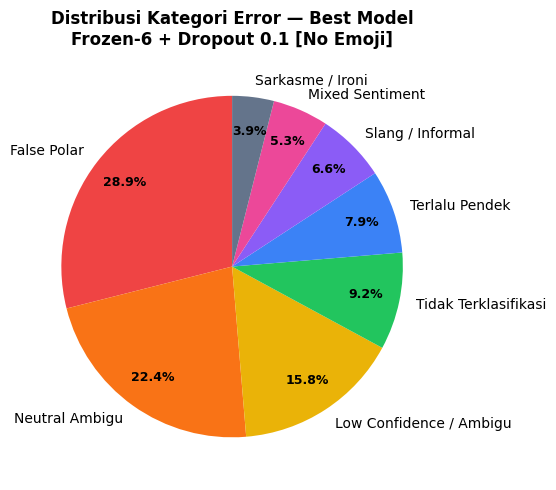

In [ ]:
# ── Aturan kategorisasi semi-otomatis ─────────────────────
# Berbasis heuristik linguistik, dilengkapi review manual

# Kata kunci sarkasme / ironi yang umum dalam ulasan wisata Indonesia
SARCASM_MARKERS = [
    'katanya', 'konon', 'padahal', 'ternyata', 'tapi sayang',
    'tapi sayangnya', 'tapi kok', 'wah bagus', 'luar biasa tapi',
    'mantap tapi', 'keren tapi', 'bagus sih tapi', 'oke sih tapi',
    'recommended tapi', 'worth it tapi', 'hmm', 'ya sudahlah',
    'alhamdulillah', 'syukurlah',
]

# Kata slang yang mungkin tidak ter-normalize sempurna
SLANG_MARKERS = [
    'wkwk', 'wkwkwk', 'haha', 'hehe', 'anjir', 'anjay', 'gila',
    'parah', 'gilak', 'goks', 'bro', 'sis', 'cuy', 'bray',
    'mantabs', 'kece', 'badai', 'epic', 'horror', 'ngeri',
    'zonk', 'php', 'zonked', 'modus',
]

# Negasi yang mungkin tidak tertangani preprocessing
NEGATION_MARKERS = [
    'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'jauh dari',
    'sama sekali tidak', 'tidak sama sekali', 'nol',
]

def categorize_error(row):
    """
    Kategorisasi error berdasarkan heuristik linguistik.
    Satu error bisa masuk ke beberapa kategori,
    prioritas: sarkasme > slang > ambigu > false_polar
    """
    text = str(row['review_asli']).lower()
    processed = str(row['review_processed']).lower()
    true_l = row['label_benar']
    pred_l = row['label_prediksi']
    conf   = row['confidence']
    wc     = len(text.split())

    categories = []

    # 1. Review terlalu pendek (< 5 kata asli)
    if wc < 5:
        categories.append('Terlalu Pendek')

    # 2. Sarkasme / ironi — ada sinyal positif tapi label negatif
    has_sarcasm = any(m in text for m in SARCASM_MARKERS)
    if has_sarcasm and true_l == 'negative' and pred_l == 'positive':
        categories.append('Sarkasme / Ironi')
    elif has_sarcasm:
        categories.append('Sarkasme / Ironi')

    # 3. Slang tidak ter-normalize
    has_slang = any(m in text for m in SLANG_MARKERS)
    if has_slang:
        categories.append('Slang / Informal')

    # 4. Mixed sentiment (ada sinyal positif DAN negatif)
    pos_words = ['bagus', 'keren', 'indah', 'nyaman', 'bersih', 'bagus']
    neg_words = ['kotor', 'jelek', 'buruk', 'mahal', 'sempit', 'susah']
    has_pos = any(w in processed for w in pos_words)
    has_neg = any(w in processed for w in neg_words)
    if has_pos and has_neg:
        categories.append('Mixed Sentiment')

    # 5. Low confidence — model sendiri tidak yakin
    if conf < 0.6:
        categories.append('Low Confidence / Ambigu')

    # 6. False Polar — prediksi berlawanan extrem (neg → pos atau pos → neg)
    if (true_l == 'negative' and pred_l == 'positive') or \
       (true_l == 'positive' and pred_l == 'negative'):
        categories.append('False Polar')

    # 7. Neutral misclassified — neutral paling sulit
    if true_l == 'neutral':
        categories.append('Neutral Ambigu')

    # Default jika tidak ada kategori
    if not categories:
        categories.append('Tidak Terklasifikasi')

    # Ambil kategori utama (prioritas pertama)
    priority = ['Sarkasme / Ironi', 'Mixed Sentiment', 'Slang / Informal',
                'Terlalu Pendek', 'False Polar', 'Neutral Ambigu',
                'Low Confidence / Ambigu', 'Tidak Terklasifikasi']
    main_cat = next((c for c in priority if c in categories), categories[0])

    return main_cat, ', '.join(categories)

# Terapkan kategorisasi
df_errors[['kategori_utama', 'semua_kategori']] = df_errors.apply(
    lambda row: pd.Series(categorize_error(row)), axis=1
)

# ── Distribusi kategori ───────────────────────────────────
print("="*60)
print("DISTRIBUSI KATEGORI ERROR")
print("="*60)
cat_dist = df_errors['kategori_utama'].value_counts()
for cat, cnt in cat_dist.items():
    pct = cnt / len(df_errors) * 100
    bar = '█' * int(pct / 2)
    print(f"  {cat:<30}: {cnt:>4} ({pct:>5.1f}%) {bar}")

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
colors_cat = ['#ef4444','#f97316','#eab308','#22c55e',
               '#3b82f6','#8b5cf6','#ec4899','#64748b']
wedges, texts, autotexts = ax.pie(
    cat_dist.values,
    labels    = cat_dist.index,
    autopct   = '%1.1f%%',
    colors    = colors_cat[:len(cat_dist)],
    startangle= 90,
    pctdistance=0.8,
)
for text in autotexts:
    text.set_fontsize(9)
    text.set_fontweight('bold')
ax.set_title('Distribusi Kategori Error — Best Model\nFrozen-6 + Dropout 0.1 [No Emoji]',
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Representative Example Documentation per Category

In [ ]:

print("="*70)
print("DOKUMENTASI ERROR REPRESENTATIF PER KATEGORI")
print("="*70)

N_CONTOH = 5   # contoh per kategori untuk laporan

for kategori in df_errors['kategori_utama'].value_counts().index:
    subset = df_errors[df_errors['kategori_utama'] == kategori]
    n_show = min(N_CONTOH, len(subset))

    print(f"\n{'─'*70}")
    print(f"  KATEGORI: {kategori.upper()}")
    print(f"  Total   : {len(subset)} kasus")
    print(f"{'─'*70}")

    # Urutkan berdasarkan confidence — yang paling "yakin tapi salah" paling informatif
    sample = subset.nlargest(n_show, 'confidence')

    for i, (_, row) in enumerate(sample.iterrows(), 1):
        print(f"\n  [{i}] Teks Asli: {row['review_asli'][:120]}")
        print(f"      Label Benar  : {row['label_benar'].upper()}")
        print(f"      Diprediksi   : {row['label_prediksi'].upper()}")
        print(f"      Confidence   : {row['confidence']:.3f}")
        print(f"      Prob [neg/neu/pos]: "
              f"{row['prob_negative']:.3f} / "
              f"{row['prob_neutral']:.3f} / "
              f"{row['prob_positive']:.3f}")
        print(f"      Semua kategori: {row['semua_kategori']}")

# ── Simpan DataFrame error untuk lampiran skripsi ─────────
# df_errors.to_csv(base_path + 'error_analysis_best_model.csv', index=False)
# print(f"\n\n✓ DataFrame error disimpan: error_analysis_best_model.csv")
# print(f"  Total error terdokumentasi: {len(df_errors)} baris")

# ── Summary statistik error ───────────────────────────────
print("\n" + "="*60)
print("SUMMARY STATISTIK ERROR")
print("="*60)
print(f"\nTotal test sampel    : {len(y_true)}")
print(f"Prediksi benar       : {(y_pred==y_true).sum()} ({(y_pred==y_true).mean()*100:.2f}%)")
print(f"Prediksi salah       : {len(df_errors)} ({len(df_errors)/len(y_true)*100:.2f}%)")
print(f"\nAverage confidence pada error : {df_errors['confidence'].mean():.3f}")
print(f"Average confidence pada benar : {y_prob.max(axis=1)[y_pred==y_true].mean():.3f}")
print(f"\nKelas paling sering salah:")
print(df_errors['label_benar'].value_counts().to_string())
print(f"\nKelas paling sering diprediksi salah menjadi:")
print(df_errors['label_prediksi'].value_counts().to_string())

DOKUMENTASI ERROR REPRESENTATIF PER KATEGORI

──────────────────────────────────────────────────────────────────────
  KATEGORI: FALSE POLAR
  Total   : 22 kasus
──────────────────────────────────────────────────────────────────────

  [1] Teks Asli: Akses mudah tp jalan setapak kurang terawat..udah mau ketutup rumput
      Label Benar  : POSITIVE
      Diprediksi   : NEGATIVE
      Confidence   : 0.909
      Prob [neg/neu/pos]: 0.909 / 0.055 / 0.036
      Semua kategori: False Polar

  [2] Teks Asli: Cuaca adem
Tempat tidak terawat
Htm 10.000
Jalan masuk sempit
Kurang recomended
      Label Benar  : NEGATIVE
      Diprediksi   : POSITIVE
      Confidence   : 0.864
      Prob [neg/neu/pos]: 0.113 / 0.023 / 0.864
      Semua kategori: False Polar

  [3] Teks Asli: Experience mainnya menyenangkan. Namun asap rokok dari ruangan pegawainya tembus sampai ke ruangan permainan, asap rokok
      Label Benar  : NEGATIVE
      Diprediksi   : POSITIVE
      Confidence   : 0.833
      Prob [neg/ne

## Prediction & Demo

### Restore

In [ ]:
# ============================================================
# CELL RESTORE — SEMUA DEPENDENSI INFERENSI
# ============================================================
# Yang di-restore:
#   [1] Library imports
#   [2] NORM_DICT (dari CSV yang sudah disimpan)
#   [3] Fungsi preprocessing (normalize, apply_norm, handle_emoji, preprocess)
#   [4] Tokenizer IndoBERTweet
#   [5] LabelEncoder
#   [6] Split index (untuk konsistensi evaluasi)
#   [7] Best model
#   [8] Konstanta (MAX_LEN, device, dll)
# ============================================================

import re, json, joblib
import numpy as np
import pandas as pd
import torch
import emoji
import warnings
warnings.filterwarnings('ignore')

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# ── Konstanta ─────────────────────────────────────────────
base_path  = '/content/drive/MyDrive/Data TA/'
MODEL_PATH = '/content/drive/MyDrive/Data TA/save best model/'
MODEL_NAME = "indolem/indobertweet-base-uncased"
MAX_LEN    = 128
device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# ──────────────────────────────────────────────────────────
# [2] LOAD NORM_DICT DARI CSV (corpus-driven, sudah disimpan)
# ──────────────────────────────────────────────────────────
df_norm   = pd.read_csv(base_path + 'corpus_driven_norm_dict.csv')
NORM_DICT = dict(zip(df_norm['non_standard'], df_norm['normalized']))
print(f"✓ [2] NORM_DICT loaded: {len(NORM_DICT)} entri")

# ──────────────────────────────────────────────────────────
# [3] FUNGSI PREPROCESSING
# ──────────────────────────────────────────────────────────
stop_factory     = StopWordRemoverFactory()
stemmer_factory  = StemmerFactory()
stopword_remover = stop_factory.create_stop_word_remover()
stemmer          = stemmer_factory.create_stemmer()

def normalize_repeated_chars(text: str) -> str:
    return re.sub(r'(.)\1{2,}', r'\1\1', text)

def apply_norm_dict(text: str, norm_dict: dict) -> str:
    words = text.split()
    return ' '.join([norm_dict.get(w, w) for w in words])

def handle_emoji(text: str, mode: str = 'remove') -> str:
    if mode == 'remove':
        return emoji.replace_emoji(text, replace='')
    elif mode == 'keep':
        return text
    else:
        raise ValueError(f"mode harus 'remove' atau 'keep'")

def preprocess(text: str,
               emoji_mode: str = 'remove',
               use_stemming: bool = False,
               remove_stopwords: bool = True) -> str:
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = handle_emoji(text, mode=emoji_mode)
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'\b\d+\b', '', text)
    text = normalize_repeated_chars(text)
    text = apply_norm_dict(text, NORM_DICT)
    if emoji_mode == 'keep':
        text = re.sub(r'[^\w\s\U0001F300-\U0001FAFF]', ' ', text)
    else:
        text = re.sub(r'[^a-z0-9\s]', ' ', text)
    if remove_stopwords:
        text = stopword_remover.remove(text)
    if use_stemming:
        text = stemmer.stem(text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("✓ [3] Fungsi preprocessing loaded")

# ──────────────────────────────────────────────────────────
# [4] TOKENIZER
# ──────────────────────────────────────────────────────────
# Coba load dari lokal dulu (lebih cepat), fallback ke HuggingFace
import os
tokenizer_local = MODEL_PATH + 'BEST_MODEL_tokenizer/'
if os.path.exists(tokenizer_local):
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_local)
    print(f"✓ [4] Tokenizer loaded dari lokal Drive")
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    print(f"✓ [4] Tokenizer loaded dari HuggingFace")

# ──────────────────────────────────────────────────────────
# [5] LABEL ENCODER
# ──────────────────────────────────────────────────────────
le = joblib.load(MODEL_PATH + 'BEST_MODEL_label_encoder.pkl')
print(f"✓ [5] LabelEncoder loaded | Kelas: {le.classes_.tolist()}")

# ──────────────────────────────────────────────────────────
# [6] SPLIT INDEX (untuk evaluasi konsisten)
# ──────────────────────────────────────────────────────────
X_train_idx = np.load(base_path + 'split_train_idx.npy')
X_val_idx   = np.load(base_path + 'split_val_idx.npy')
X_test_idx  = np.load(base_path + 'split_test_idx.npy')
print(f"✓ [6] Split index loaded | Test: {len(X_test_idx)} sampel")

# ──────────────────────────────────────────────────────────
# [7] BEST MODEL
# ──────────────────────────────────────────────────────────
# Load metadata dulu untuk tahu konfigurasi best model
with open(MODEL_PATH + 'BEST_MODEL_metadata.json', 'r') as f:
    meta = json.load(f)

best_config = meta['best_config']
print(f"\n  Best model config dari metadata:")
print(f"  Freeze   : {best_config['freeze_mode']}")
print(f"  Dropout  : {best_config['dropout']}")
print(f"  Emoji    : {best_config['emoji_mode']}")
print(f"  Macro F1 : {meta['performance']['macro_f1']}")

# Bangun arsitektur model dulu
best_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = len(le.classes_),
    ignore_mismatched_sizes = True,
)

# Set dropout sesuai config
if best_config['dropout'] not in [None, 'default']:
    best_model.classifier.dropout = torch.nn.Dropout(
        float(best_config['dropout'])
    )

# Freeze layers sesuai config
if best_config['freeze_mode'] == 'first6':
    for name, param in best_model.named_parameters():
        if 'embeddings' in name:
            param.requires_grad = False
        elif 'encoder.layer.' in name:
            layer_num = int(name.split('encoder.layer.')[1].split('.')[0])
            if layer_num < 6:
                param.requires_grad = False

# Load bobot
best_model.load_state_dict(
    torch.load(MODEL_PATH + 'BEST_MODEL_state_dict.pt',
               map_location=device)
)
best_model = best_model.to(device)
best_model.eval()
print(f"✓ [7] Best model loaded & eval mode")

# ──────────────────────────────────────────────────────────
# [8] LOAD df_final UNTUK KEPERLUAN EVALUASI
# ──────────────────────────────────────────────────────────
df_final = pd.read_csv(base_path + 'df_preprocessed_full.csv')
print(f"✓ [8] df_final loaded: {df_final.shape}")

print("\n" + "="*50)
print("✓ SEMUA DEPENDENSI BERHASIL DI-RESTORE")
print("  Siap menjalankan predict_single() & demo")
print("="*50)

Device: cuda
✓ [2] NORM_DICT loaded: 38 entri
✓ [3] Fungsi preprocessing loaded
✓ [4] Tokenizer loaded dari lokal Drive
✓ [5] LabelEncoder loaded | Kelas: ['negative', 'neutral', 'positive']
✓ [6] Split index loaded | Test: 479 sampel

  Best model config dari metadata:
  Freeze   : first6
  Dropout  : 0.1
  Emoji    : no_emoji
  Macro F1 : 0.7698


pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

✓ [7] Best model loaded & eval mode
✓ [8] df_final loaded: (4783, 4)

✓ SEMUA DEPENDENSI BERHASIL DI-RESTORE
  Siap menjalankan predict_single() & demo


### Predict_Single Function

In [ ]:
# ============================================================
# CELL 11A — FUNGSI INFERENSI
# ============================================================

def predict_single(text_input: str,
                   model=best_model,
                   verbose: bool = True) -> dict:
    model.eval()
    processed = preprocess(text_input, emoji_mode='remove', use_stemming=False)
    if verbose:
        print(f"  Input    : {text_input[:100]}")
        print(f"  Processed: {processed[:100]}")

    encoding = tokenizer(
        processed,
        padding='max_length',
        truncation=True,
        max_length=MAX_LEN,
        return_tensors='pt',
    )
    input_ids      = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        outputs = best_model(input_ids=input_ids, attention_mask=attention_mask)
        probs   = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]

    pred_idx   = probs.argmax()
    pred_label = le.inverse_transform([pred_idx])[0]
    confidence = float(probs[pred_idx])
    prob_dict  = {cls: float(probs[le.transform([cls])[0]]) for cls in le.classes_}

    if verbose:
        print(f"\n  {'─'*40}")
        print(f"  Prediksi   : {pred_label.upper()}")
        print(f"  Confidence : {confidence:.4f} ({confidence*100:.1f}%)")
        print(f"  Probabilitas:")
        for cls, prob in sorted(prob_dict.items(), key=lambda x: -x[1]):
            bar = '█' * int(prob * 30)
            print(f"    {cls:<12}: {prob:.4f}  {bar}")

    return {
        'label'         : pred_label,
        'confidence'    : confidence,
        'probabilities' : prob_dict,
        'processed_text': processed,
    }

def predict_batch(texts: list, model=best_model) -> pd.DataFrame:
    results = []
    for text in texts:
        res = predict_single(text, model=model, verbose=False)
        res['original_text'] = text
        results.append(res)
    df_pred = pd.DataFrame(results)
    df_pred['prob_negative'] = df_pred['probabilities'].apply(lambda x: x['negative'])
    df_pred['prob_neutral']  = df_pred['probabilities'].apply(lambda x: x['neutral'])
    df_pred['prob_positive'] = df_pred['probabilities'].apply(lambda x: x['positive'])
    return df_pred.drop(columns=['probabilities'])

print("✓ predict_single() dan predict_batch() siap")

✓ predict_single() dan predict_batch() siap


### Training History Visualization

TABEL HASIL SEMUA EKSPERIMEN


,run,model_type,emoji_mode,freeze,dropout,accuracy,macro_f1,macro_p,macro_r,f1_negative,f1_neutral,f1_positive
0,TF-IDF + LR [No Emoji],TF-IDF + LR,No Emoji,—,—,0.8225,0.7122,0.6789,0.7641,0.6812,0.5538,0.9014
1,TF-IDF + LR [Keep Emoji],TF-IDF + LR,Keep Emoji,—,—,0.8246,0.7155,0.6811,0.7696,0.6857,0.5581,0.9028
2,Frozen IndoBERTweet [No Emoji],Frozen BERT (Baseline),No Emoji,All layers,default,0.5553,0.3725,0.3873,0.3759,0.1398,0.2569,0.7210
3,Frozen IndoBERTweet [Keep Emoji],Frozen BERT (Baseline),Keep Emoji,All layers,default,0.5094,0.3846,0.4059,0.4388,0.2712,0.2281,0.6546
4,Full FT IndoBERTweet [No Emoji],Full Fine-Tuning,No Emoji,NaN,default,0.8497,0.7481,0.7207,0.7858,0.6957,0.6325,0.9161
5,Full FT IndoBERTweet [Keep Emoji],Full Fine-Tuning,Keep Emoji,NaN,default,0.8246,0.7294,0.6860,0.8129,0.7059,0.5821,0.9001
6,Frozen-6 IndoBERTweet [No Emoji],Frozen-6,No Emoji,6 layers (0–5),default,0.8559,0.7687,0.7430,0.8045,0.7520,0.6406,0.9135
7,Frozen-6 IndoBERTweet [Keep Emoji],Frozen-6,Keep Emoji,6 layers (0–5),default,0.8351,0.7174,0.6958,0.7490,0.6714,0.5714,0.9093
8,Frozen-6+Dropout IndoBERTweet [No Emoji],Frozen-6 + Dropout,No Emoji,6 layers (0–5),0.1,0.8601,0.7698,0.7488,0.7965,0.7419,0.6504,0.9170
9,Frozen-6+Dropout IndoBERTweet [Keep Emoji],Frozen-6 + Dropout,Keep Emoji,6 layers (0–5),0.1,0.8288,0.7303,0.6946,0.7864,0.7153,0.5758,0.8999



🏆 Best run (otomatis dari CSV): Frozen-6+Dropout IndoBERTweet [No Emoji]
   Macro F1 : 0.7698


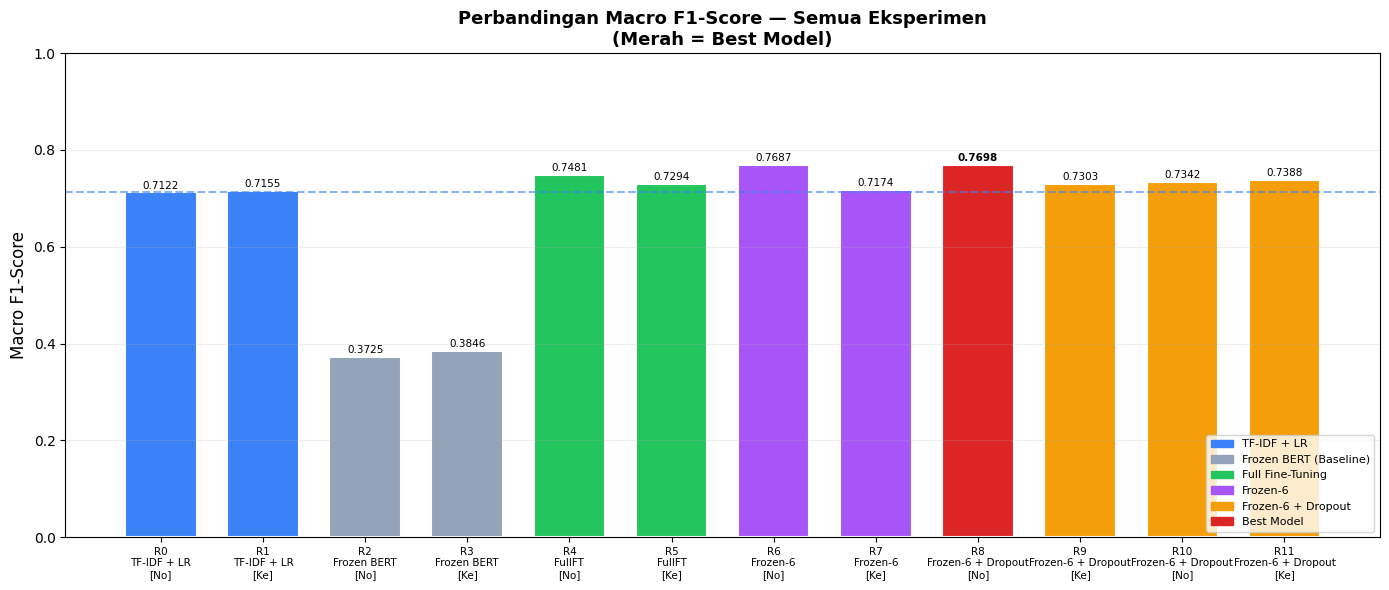

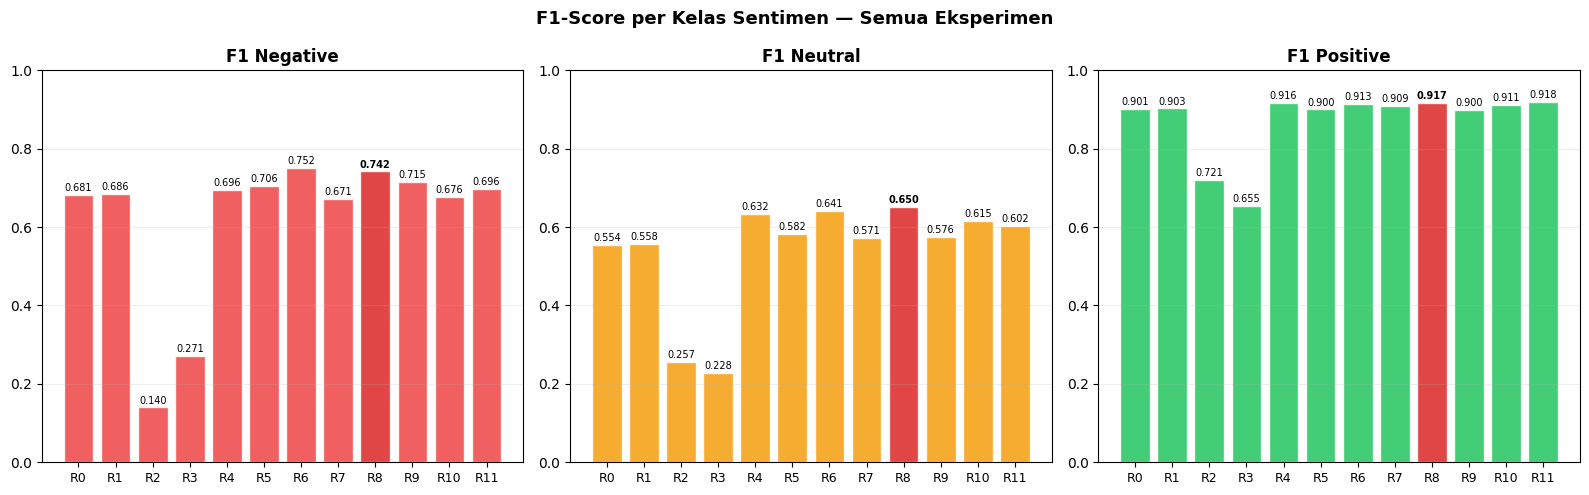

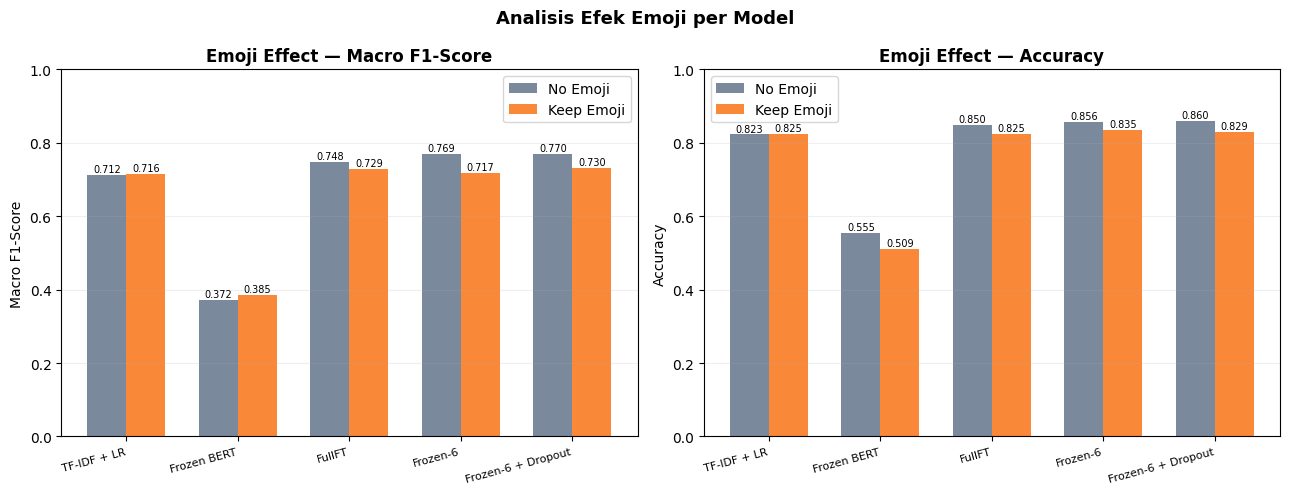


✓ Semua visualisasi selesai
✓ Best model: Frozen-6+Dropout IndoBERTweet [No Emoji] | Macro F1: 0.7698


In [ ]:
# ============================================================
# Membaca dari hasil_semua_run_FINAL.csv, bukan hardcode angka
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Load tabel hasil semua run ────────────────────────────
df_all = pd.read_csv(MODEL_PATH + 'hasil_semua_run_FINAL.csv')

print("="*60)
print("TABEL HASIL SEMUA EKSPERIMEN")
print("="*60)
display(df_all)

# ──────────────────────────────────────────────────────────
# histories_manual — Semi-otomatis dari df_all
# Bukan hardcode, melainkan dibaca langsung dari CSV hasil
# ──────────────────────────────────────────────────────────
histories_manual = {
    row['run']: {
        'model_type' : row['model_type'],
        'emoji_mode' : row['emoji_mode'],
        'freeze'     : row['freeze'],
        'dropout'    : row['dropout'],
        'accuracy'   : row['accuracy'],
        'macro_f1'   : row['macro_f1'],
        'macro_p'    : row['macro_p'],
        'macro_r'    : row['macro_r'],
        'f1_negative': row['f1_negative'],
        'f1_neutral' : row['f1_neutral'],
        'f1_positive': row['f1_positive'],
    }
    for _, row in df_all.iterrows()
}

# Identifikasi best model secara otomatis
best_run_name = df_all.loc[df_all['macro_f1'].idxmax(), 'run']
best_row      = df_all.loc[df_all['macro_f1'].idxmax()]
print(f"\n🏆 Best run (otomatis dari CSV): {best_run_name}")
print(f"   Macro F1 : {best_row['macro_f1']:.4f}")

# ──────────────────────────────────────────────────────────
# VISUALISASI 1: Macro F1 semua run dengan highlight best
# ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

color_map = {
    'TF-IDF + LR'        : '#3b82f6',
    'Frozen BERT (Baseline)': '#94a3b8',
    'Full Fine-Tuning'   : '#22c55e',
    'Frozen-6'           : '#a855f7',
    'Frozen-6 + Dropout' : '#f59e0b',
}

bar_colors = [
    color_map.get(row['model_type'], '#64748b')
    for _, row in df_all.iterrows()
]

# Highlight best model
best_idx_pos = df_all['macro_f1'].idxmax()
bar_colors[best_idx_pos] = '#dc2626'

bars = ax.bar(range(len(df_all)), df_all['macro_f1'],
              color=bar_colors, edgecolor='white', linewidth=1.5, width=0.7)

# Garis baseline TF-IDF rata-rata
tfidf_mean = df_all[df_all['model_type']=='TF-IDF + LR']['macro_f1'].mean()
ax.axhline(y=tfidf_mean, color='#3b82f6', linestyle='--',
           alpha=0.6, linewidth=1.5, label=f'TF-IDF+LR avg ({tfidf_mean:.4f})')

ax.set_xticks(range(len(df_all)))
ax.set_xticklabels(
    [f"R{i}\n{row['model_type'].replace(' Fine-Tuning','FT').replace(' (Baseline)','')}\n[{row['emoji_mode'][:2]}]"
     for i, (_, row) in enumerate(df_all.iterrows())],
    fontsize=7.5
)
ax.set_ylabel('Macro F1-Score', fontsize=12)
ax.set_title('Perbandingan Macro F1-Score — Semua Eksperimen\n(Merah = Best Model)',
             fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.0)
ax.grid(True, alpha=0.2, axis='y')

for i, (bar, val) in enumerate(zip(bars, df_all['macro_f1'])):
    weight = 'bold' if i == best_idx_pos else 'normal'
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.008,
            f'{val:.4f}', ha='center', fontsize=7.5, fontweight=weight)

patches = [mpatches.Patch(color=v, label=k) for k, v in color_map.items()]
patches.append(mpatches.Patch(color='#dc2626', label='Best Model'))
ax.legend(handles=patches, loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

# ──────────────────────────────────────────────────────────
# VISUALISASI 2: F1 per kelas — grouped bar
# ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('F1-Score per Kelas Sentimen — Semua Eksperimen',
             fontweight='bold', fontsize=13)

kelas_info = [
    ('f1_negative', 'F1 Negative', '#ef4444'),
    ('f1_neutral',  'F1 Neutral',  '#f59e0b'),
    ('f1_positive', 'F1 Positive', '#22c55e'),
]
for ax, (col, title, color) in zip(axes, kelas_info):
    bar_c = [color] * len(df_all)
    bar_c[best_idx_pos] = '#dc2626'
    ax.bar(range(len(df_all)), df_all[col], color=bar_c,
           alpha=0.85, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xticks(range(len(df_all)))
    ax.set_xticklabels([f"R{i}" for i in range(len(df_all))], fontsize=9)
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.2, axis='y')
    for i, (bar, val) in enumerate(
        zip(ax.patches, df_all[col])
    ):
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.01,
                f'{val:.3f}', ha='center', fontsize=7,
                fontweight='bold' if i == best_idx_pos else 'normal')

plt.tight_layout()
plt.show()

# ──────────────────────────────────────────────────────────
# VISUALISASI 3: Emoji Effect — otomatis dari df_all
# ──────────────────────────────────────────────────────────
model_types = df_all['model_type'].unique()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Analisis Efek Emoji per Model', fontweight='bold', fontsize=13)

x = np.arange(len(model_types))
w = 0.35

for ax, metric, ylabel in zip(
    axes,
    ['macro_f1', 'accuracy'],
    ['Macro F1-Score', 'Accuracy']
):
    no_e_vals   = [df_all[(df_all['model_type']==m)&(df_all['emoji_mode']=='No Emoji')][metric].values[0]
                   for m in model_types]
    keep_e_vals = [df_all[(df_all['model_type']==m)&(df_all['emoji_mode']=='Keep Emoji')][metric].values[0]
                   for m in model_types]

    bars1 = ax.bar(x - w/2, no_e_vals,   w, label='No Emoji',
                   color='#64748b', alpha=0.85)
    bars2 = ax.bar(x + w/2, keep_e_vals, w, label='Keep Emoji',
                   color='#f97316', alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [m.replace(' Fine-Tuning','FT').replace(' (Baseline)','')
         for m in model_types],
        rotation=15, ha='right', fontsize=8
    )
    ax.set_ylabel(ylabel)
    ax.set_title(f'Emoji Effect — {ylabel}', fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.legend()
    ax.grid(True, alpha=0.2, axis='y')

    for bar, val in list(zip(bars1, no_e_vals)) + list(zip(bars2, keep_e_vals)):
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.008,
                f'{val:.3f}', ha='center', fontsize=7)

plt.tight_layout()
plt.show()

print("\n✓ Semua visualisasi selesai")
print(f"✓ Best model: {best_run_name} | Macro F1: {best_row['macro_f1']:.4f}")

### Prediction Demo

╔══════════════════════════════════════════════════════╗
║         DEMO PREDIKSI — BEST MODEL                  ║
║  Frozen-6+Dropout IndoBERTweet [No Emoji]          ║
║  Macro F1: 0.7698 | Accuracy: 0.8601          ║
╚══════════════════════════════════════════════════════╝

══════════════════════════════════════════════════════════════
  [[Test Set] Negative]
  Input    : Embung mangkrak dan tidak terawat
  Processed: embung mangkrak terawat

  ────────────────────────────────────────
  Prediksi   : NEGATIVE
  Confidence : 0.3986 (39.9%)
  Probabilitas:
    negative    : 0.3986  ███████████
    positive    : 0.3254  █████████
    neutral     : 0.2760  ████████

══════════════════════════════════════════════════════════════
  [[Test Set] Negative]
  Input    : Biar gak susah untuk mencarinya
  Processed: biar susah mencarinya

  ────────────────────────────────────────
  Prediksi   : NEGATIVE
  Confidence : 0.7565 (75.7%)
  Probabilitas:
    negative    : 0.7565  ██████████████████████

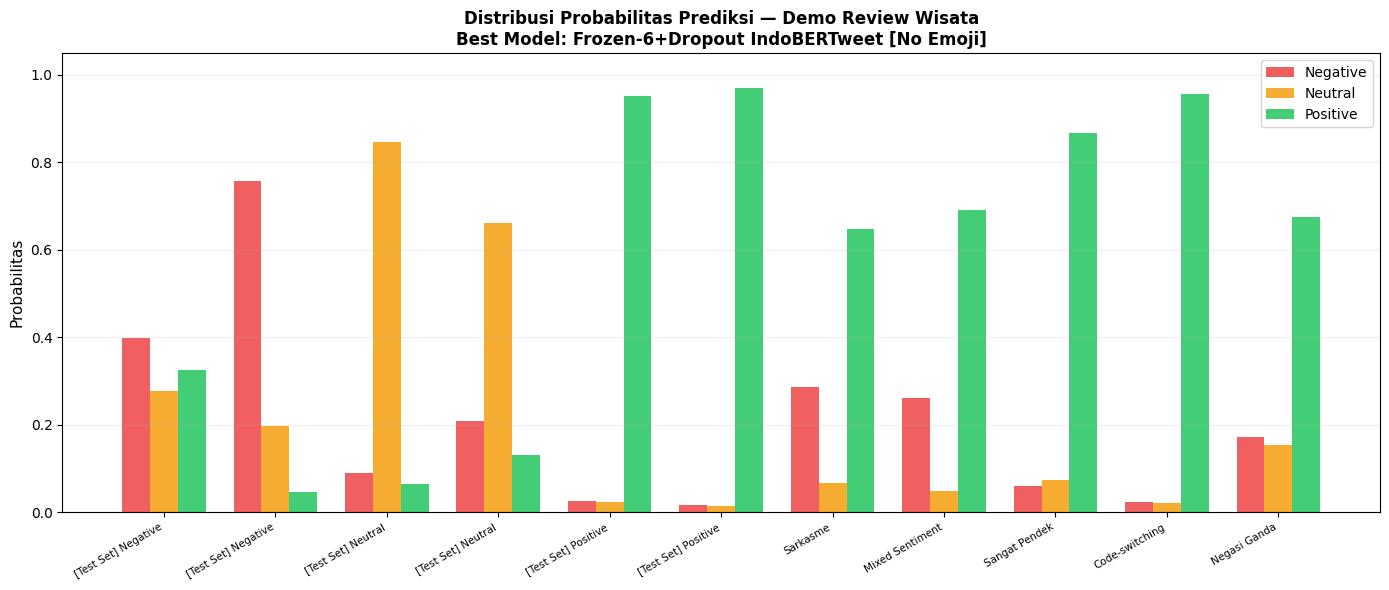

Text(value='', description='Review:', layout=Layout(width='80%'), placeholder='Tulis review wisata...')

Button(description='Prediksi', style=ButtonStyle())

Output()

In [ ]:
print("╔══════════════════════════════════════════════════════╗")
print("║         DEMO PREDIKSI — BEST MODEL                  ║")
print(f"║  {best_run_name[:50]:<50}║")
print(f"║  Macro F1: {best_row['macro_f1']:.4f} | Accuracy: {best_row['accuracy']:.4f}          ║")
print("╚══════════════════════════════════════════════════════╝")

# ──────────────────────────────────────────────────────────
# BAGIAN 1: demo_reviews — semi-otomatis dari test set + manual
# Mengambil contoh nyata dari test set per kelas, bukan semua manual
# ──────────────────────────────────────────────────────────

# Ambil 2 contoh dari test set per kelas (langsung dari data asli)
samples_from_test = {}
for kelas in le.classes_:
    test_texts_raw = df_final.loc[X_test_idx, 'review_text']
    test_labels    = le.inverse_transform(
        [le.transform([df_final.loc[i, 'sentiment']])[0]
         for i in X_test_idx]
    )
    idx_kelas = [i for i, l in enumerate(test_labels) if l == kelas]
    np.random.seed(42)
    chosen    = np.random.choice(idx_kelas, size=min(2, len(idx_kelas)),
                                 replace=False)
    samples_from_test[kelas] = [
        test_texts_raw.iloc[c] for c in chosen
    ]

# Gabungkan: dari test set + kasus sulit manual
demo_reviews = []

# Dari test set — otomatis
for kelas, samples in samples_from_test.items():
    for s in samples:
        demo_reviews.append((f"[Test Set] {kelas.capitalize()}", s))

# Kasus sulit — tetap manual karena perlu representasi khusus
demo_reviews_manual = [
    ("Sarkasme",
     "Wah bagus banget tempatnya... antrian 3 jam, toilet 1 untuk 500 orang, "
     "harga makan 3x lipat dari luar. Benar-benar pengalaman yang tak terlupakan."),
    ("Mixed Sentiment",
     "Pemandangannya memang indah dan fotogenik, tapi sayang pengelolaan sangat buruk. "
     "Sampah dimana-mana, banyak pedagang liar. Potensi bagus tapi butuh perbaikan."),
    ("Sangat Pendek",
     "Keren!"),
    ("Code-switching",
     "View nya epic banget, worth every rupiah! Must visit kalau ke Jawa Tengah."),
    ("Negasi Ganda",
     "Tidak jelek sih, tapi juga tidak istimewa. Biasa-biasa saja tempatnya."),
]
demo_reviews.extend(demo_reviews_manual)

# ──────────────────────────────────────────────────────────
# Jalankan prediksi semua demo
# ──────────────────────────────────────────────────────────
results_demo = []

for label_manual, review in demo_reviews:
    print(f"\n{'═'*62}")
    print(f"  [{label_manual}]")
    result = predict_single(review, verbose=True)
    result['label_manual_kategori'] = label_manual
    result['original_text']         = review
    results_demo.append(result)

# ──────────────────────────────────────────────────────────
# Ringkasan tabel demo
# ──────────────────────────────────────────────────────────
print("\n\n" + "="*70)
print("RINGKASAN DEMO PREDIKSI")
print("="*70)
df_demo = pd.DataFrame(results_demo)
print(f"\n{'Kategori':<30} {'Prediksi':<12} {'Conf':>7}  Confidence Bar")
print("─"*70)
for _, row in df_demo.iterrows():
    conf_bar = '█' * int(row['confidence'] * 25)
    label_color = {
        'positive': '✅', 'neutral': '🟡', 'negative': '❌'
    }.get(row['label'], '⚪')
    print(f"  {row['label_manual_kategori']:<28} "
          f"{label_color} {row['label'].upper():<10} "
          f"{row['confidence']:.3f}  {conf_bar}")

# Visualisasi demo
fig, ax = plt.subplots(figsize=(14, 6))
x     = np.arange(len(df_demo))
width = 0.25

prob_neg = [r['probabilities']['negative'] for r in results_demo]
prob_neu = [r['probabilities']['neutral']  for r in results_demo]
prob_pos = [r['probabilities']['positive'] for r in results_demo]

ax.bar(x - width, prob_neg, width, label='Negative',
       color='#ef4444', alpha=0.85)
ax.bar(x,         prob_neu, width, label='Neutral',
       color='#f59e0b', alpha=0.85)
ax.bar(x + width, prob_pos, width, label='Positive',
       color='#22c55e', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(
    [r['label_manual_kategori'] for r in results_demo],
    rotation=30, ha='right', fontsize=7.5
)
ax.set_ylabel('Probabilitas', fontsize=11)
ax.set_title(f'Distribusi Probabilitas Prediksi — Demo Review Wisata\nBest Model: {best_run_name}',
             fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

# ──────────────────────────────────────────────────────────
# BAGIAN 2: INPUT INTERAKTIF DARI USER
# Berguna saat sidang atau presentasi
# ──────────────────────────────────────────────────────────
import ipywidgets as widgets
from IPython.display import display

text_input = widgets.Text(
    placeholder='Tulis review wisata...',
    description='Review:',
    layout=widgets.Layout(width='80%')
)

button = widgets.Button(description="Prediksi")

output = widgets.Output()

def on_button_click(b):
    with output:
        output.clear_output()

        text = text_input.value.strip()

        if text == "":
            print("⚠️ Input kosong")
        else:
            predict_single(text, verbose=True)

button.on_click(on_button_click)

display(text_input, button, output)

## Save Best Model

In [ ]:
# ============================================================
# CELL 11C — SAVE BEST MODEL LENGKAP + METADATA
# ============================================================
import json, joblib
from datetime import datetime

print("="*60)
print("SAVE BEST MODEL — PAKET LENGKAP")
print("="*60)

# ── 1. Simpan state dict ──────────────────────────────────
torch.save(
    best_model.state_dict(),
    base_path + 'BEST_MODEL_state_dict.pt'
)
print("✓ [1/5] state_dict disimpan: BEST_MODEL_state_dict.pt")

# ── 2. Simpan seluruh model object ────────────────────────
torch.save(
    best_model,
    base_path + 'BEST_MODEL_full.pt'
)
print("✓ [2/5] Full model disimpan: BEST_MODEL_full.pt")

# ── 3. Simpan tokenizer ───────────────────────────────────
tokenizer.save_pretrained(base_path + 'BEST_MODEL_tokenizer/')
print("✓ [3/5] Tokenizer disimpan: BEST_MODEL_tokenizer/")

# ── 4. Simpan label encoder ───────────────────────────────
joblib.dump(le, base_path + 'BEST_MODEL_label_encoder.pkl')
print("✓ [4/5] LabelEncoder disimpan: BEST_MODEL_label_encoder.pkl")

# ── 5. Simpan metadata & konfigurasi ─────────────────────
metadata = {
    'timestamp'       : datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'model_name'      : 'IndoBERTweet Fine-tuned Sentiment',
    'base_model'      : MODEL_NAME,
    'task'            : 'Sentiment Classification (Positive/Neutral/Negative)',
    'domain'          : 'Ulasan Wisata Pulau Jawa (Google Maps)',
    'best_config'     : {
        'freeze_mode'     : 'first6',
        'dropout'         : 0.1,
        'emoji_mode'      : 'no_emoji',
        'epochs'          : NUM_EPOCHS,
        'batch_size'      : BATCH_SIZE,
        'learning_rate'   : LR,
        'warmup_ratio'    : WARMUP_RATIO,
        'weight_decay'    : WEIGHT_DECAY,
        'max_length'      : MAX_LEN,
        'early_stopping'  : PATIENCE,
    },
    'performance'     : {
        'accuracy'        : 0.8601,
        'macro_f1'        : 0.7698,
        'f1_negative'     : 0.7419,
        'f1_neutral'      : 0.6504,
        'f1_positive'     : 0.9170,
    },
    'label_mapping'   : {
        str(i): cls for i, cls in enumerate(le.classes_)
    },
    'dataset_info'    : {
        'total_samples'   : len(df_final),
        'labeling_strategy': 'Majority Voting dari 6 aspek ABSA',
        'split_ratio'     : '80/10/10 stratified',
        'random_state'    : 42,
    }
}

with open(base_path + 'BEST_MODEL_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("✓ [5/5] Metadata disimpan: BEST_MODEL_metadata.json")

# ── Simpan tabel hasil semua run ──────────────────────────
df_all = pd.DataFrame(all_results)
df_all.to_csv(base_path + 'hasil_semua_run_FINAL.csv', index=False)
print("✓ Tabel hasil 12 run: hasil_semua_run_FINAL.csv")

# ── Ringkasan file yang disimpan ──────────────────────────
print("\n" + "="*60)
print("DAFTAR FILE YANG DISIMPAN DI GOOGLE DRIVE")
print("="*60)
files_saved = [
    ('BEST_MODEL_state_dict.pt',    'Bobot model (untuk load ulang)'),
    ('BEST_MODEL_full.pt',          'Full model object'),
    ('BEST_MODEL_tokenizer/',       'IndoBERTweet tokenizer'),
    ('BEST_MODEL_label_encoder.pkl','Label encoder (neg/neu/pos)'),
    ('BEST_MODEL_metadata.json',    'Konfigurasi & performa model'),
    ('hasil_semua_run_FINAL.csv',   'Tabel 12 eksperimen lengkap'),
    ('error_analysis_best_model.csv','Analisis error detail'),
]
for fname, desc in files_saved:
    print(f"  ✓ {fname:<40} → {desc}")

SAVE BEST MODEL — PAKET LENGKAP
✓ [1/5] state_dict disimpan: BEST_MODEL_state_dict.pt
✓ [2/5] Full model disimpan: BEST_MODEL_full.pt
✓ [3/5] Tokenizer disimpan: BEST_MODEL_tokenizer/
✓ [4/5] LabelEncoder disimpan: BEST_MODEL_label_encoder.pkl
✓ [5/5] Metadata disimpan: BEST_MODEL_metadata.json
✓ Tabel hasil 12 run: hasil_semua_run_FINAL.csv

DAFTAR FILE YANG DISIMPAN DI GOOGLE DRIVE
  ✓ BEST_MODEL_state_dict.pt                 → Bobot model (untuk load ulang)
  ✓ BEST_MODEL_full.pt                       → Full model object
  ✓ BEST_MODEL_tokenizer/                    → IndoBERTweet tokenizer
  ✓ BEST_MODEL_label_encoder.pkl             → Label encoder (neg/neu/pos)
  ✓ BEST_MODEL_metadata.json                 → Konfigurasi & performa model
  ✓ hasil_semua_run_FINAL.csv                → Tabel 12 eksperimen lengkap
  ✓ error_analysis_best_model.csv            → Analisis error detail


In [ ]:
# ============================================================
# CELL 11D — PANDUAN LOAD MODEL (untuk session baru)
# Jalankan cell ini di session Google Colab baru
# ============================================================

"""
PANDUAN LOAD BEST MODEL DI SESSION BARU
========================================

# Step 1: Mount drive & install
from google.colab import drive
drive.mount('/content/drive')
base_path = '/content/drive/MyDrive/Data TA/'
!pip install transformers torch joblib -q

# Step 2: Import
import torch, joblib, json
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Step 3: Load metadata
with open(base_path + 'BEST_MODEL_metadata.json') as f:
    meta = json.load(f)

# Step 4: Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(base_path + 'BEST_MODEL_tokenizer/')

# Step 5: Load model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = torch.load(base_path + 'BEST_MODEL_full.pt', map_location=device)
model.eval()

# Step 6: Load label encoder
le = joblib.load(base_path + 'BEST_MODEL_label_encoder.pkl')

print('✓ Model siap digunakan')
print('Performa:', meta['performance'])
"""

print("Panduan load model sudah tersedia di docstring cell ini.")
print("Copy dan jalankan di session baru jika diperlukan.")

# ── Final summary ─────────────────────────────────────────
print("\n" + "╔" + "═"*58 + "╗")
print("║" + "  PENELITIAN SELESAI — RINGKASAN AKHIR".center(58) + "║")
print("╠" + "═"*58 + "╣")
print("║  Best Model  : Frozen-6 + Dropout 0.1 [No Emoji]      ║")
print("║  Accuracy    : 86.01%                                  ║")
print("║  Macro F1    : 76.98%                                  ║")
print("║  F1 Positive : 91.70%                                  ║")
print("║  F1 Neutral  : 65.04%  ← kelas tersulit               ║")
print("║  F1 Negative : 74.19%                                  ║")
print("╠" + "═"*58 + "╣")
print("║  Total run   : 12 eksperimen                           ║")
print("║  Dataset     : 4.913 ulasan wisata Pulau Jawa          ║")
print("║  Labeling    : Majority Voting (6 aspek ABSA)          ║")
print("╚" + "═"*58 + "╝")

Panduan load model sudah tersedia di docstring cell ini.
Copy dan jalankan di session baru jika diperlukan.

╔══════════════════════════════════════════════════════════╗
║            PENELITIAN SELESAI — RINGKASAN AKHIR          ║
╠══════════════════════════════════════════════════════════╣
║  Best Model  : Frozen-6 + Dropout 0.1 [No Emoji]      ║
║  Accuracy    : 86.01%                                  ║
║  Macro F1    : 76.98%                                  ║
║  F1 Positive : 91.70%                                  ║
║  F1 Neutral  : 65.04%  ← kelas tersulit               ║
║  F1 Negative : 74.19%                                  ║
╠══════════════════════════════════════════════════════════╣
║  Total run   : 12 eksperimen                           ║
║  Dataset     : 4.913 ulasan wisata Pulau Jawa          ║
║  Labeling    : Majority Voting (6 aspek ABSA)          ║
╚══════════════════════════════════════════════════════════╝


# mboh